# Scoring, Roster Depth, and Lineup Flexibility

### A visual comparison of Pigskin Punters' current rules and the proposed format

**Question:** How would QB/TE 1.0 PPR, RB/WR 0.5 PPR, and replacing one required WR with an additional RB/WR/TE FLEX change positional value, team roster choices, and best legal lineups?

The purpose of this comparison is to see how changing the scoring system and starting lineup would affect the league. The goal is not simply to raise or lower fantasy scores. It is to see whether managers would have more flexibility when building lineups and could make better use of players already on their rosters.

The proposed format makes two changes. RB and WR receptions are worth half a point instead of one point. QB receptions remain worth one point, while TE receptions fall from two points to one point. One required WR position is also replaced with an additional FLEX position.

The total number of starters stays the same. Managers would start two required WRs and two FLEX players instead of three required WRs and one FLEX. All other starting positions remain unchanged.

The analysis separates the scoring change from the lineup change so we can understand what each does on its own and what happens when they are combined.

## Scope and comparison design

All roster analysis uses one Sleeper ownership snapshot and the same season-to-date player statistics under both scoring formats. Current roster ownership is not historical ownership. The best-lineup charts use the production players recorded so far this season; they do not show lineups managers actually submitted or predict future results.

| Scenario | Scoring | Starter slots |
|---|---|---|
| A - Current baseline | Pigskin Punters' current Sleeper scoring | Current |
| B - Scoring only | 1.0 PPR for QB/TE; 0.5 PPR for RB/WR | Current |
| C - Lineup only | Current Sleeper scoring | Proposed |
| D - Combined proposal | 1.0 PPR for QB/TE; 0.5 PPR for RB/WR | Proposed |

The proposed lineup changes exactly one required WR slot to one standard FLEX slot. The existing SUPER_FLEX and all other roster slots remain unchanged.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display


def find_project_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "main.py").is_file() and (candidate / "outputs").is_dir():
            return candidate
    raise FileNotFoundError(
        "Open this notebook from the project folder or a child folder after running main.py."
    )


PROJECT_ROOT = find_project_root()
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import config


def read_report(name):
    path = OUTPUT_DIR / name
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {path.name}. Run the Sleeper pipeline with `python main.py` first."
        )
    return pd.read_csv(path)


run_metadata = json.loads((OUTPUT_DIR / "run_metadata.json").read_text(encoding="utf-8"))
lineup_settings = json.loads(
    (OUTPUT_DIR / "lineup_scenario_settings.json").read_text(encoding="utf-8")
)
slot_comparison = read_report("lineup_slot_comparison.csv")
lineup_scenarios = read_report("team_lineup_scenarios.csv")
lineup_impact = read_report("team_lineup_impact.csv")
lineup_selections = read_report("team_lineup_selections.csv")
viable_options = read_report("team_viable_options.csv")
roster_depth = read_report("team_roster_depth.csv")
flex_candidates = read_report("team_flex_candidates.csv")
scoring_audit = read_report("scoring_audit.csv")
scoring_settings = read_report("current_sleeper_scoring_settings.csv")

current_slots = lineup_settings["current_roster_positions"]
proposed_slots = lineup_settings["proposed_roster_positions"]
slot_changes = slot_comparison.set_index("Slot")["Change"]
assert int(slot_comparison["Current starters"].sum()) == int(
    slot_comparison["Proposed starters"].sum()
)
assert int(slot_changes.get("WR", 0)) == -1
assert int(slot_changes.get("FLEX", 0)) == 1
assert int(slot_changes.get("SUPER_FLEX", 0)) == 0
assert slot_comparison.loc[~slot_comparison["Slot"].isin(["WR", "FLEX"]), "Change"].eq(0).all()

scenario_counts = lineup_scenarios.groupby("Roster ID")["Scenario"].nunique()
assert scenario_counts.eq(4).all()
assert set(lineup_scenarios["Scenario"]) == {"A", "B", "C", "D"}
assert lineup_scenarios.groupby("Roster ID")["Team"].nunique().eq(1).all()
assert lineup_scenarios["Unfilled starter slots"].eq(0).all()
selected_ids = lineup_selections.loc[lineup_selections["Filled"], [
    "Roster ID", "Scenario", "Sleeper player ID"
]]
assert not selected_ids.duplicated().any()
assert lineup_scenarios["Roster ID"].nunique() == int(run_metadata["team_count"])

current_scoring = scoring_settings.set_index("setting")["points_per_stat"].to_dict()
comparison_scoring = dict(current_scoring)
comparison_scoring["rec"] = config.COMPARISON_BASE_RECEPTION_POINTS
comparison_scoring["bonus_rec_te"] = config.COMPARISON_TE_PREMIUM
comparison_reception_points = {
    "QB": config.COMPARISON_QB_RECEPTION_POINTS,
    "RB": config.COMPARISON_BASE_RECEPTION_POINTS,
    "WR": config.COMPARISON_BASE_RECEPTION_POINTS,
    "TE": config.COMPARISON_BASE_RECEPTION_POINTS + config.COMPARISON_TE_PREMIUM,
}
assert comparison_reception_points == {"QB": 1.0, "RB": 0.5, "WR": 0.5, "TE": 1.0}
reception_keys = {"rec", "bonus_rec_te"}
all_scoring_keys = set(current_scoring) | set(comparison_scoring)
changed_non_reception = [
    key for key in all_scoring_keys - reception_keys
    if current_scoring.get(key, 0) != comparison_scoring.get(key, 0)
]
assert not changed_non_reception, changed_non_reception

roster_snapshot = lineup_settings["roster_snapshot_retrieved_at_utc"]
statistical_period = lineup_settings["statistical_period"]
print(f"League: {lineup_settings['league_name']}")
print(f"Season: {lineup_settings['season']} | {statistical_period}")
print(f"Current roster snapshot (UTC): {roster_snapshot}")
print(f"Teams: {lineup_scenarios['Roster ID'].nunique()} | Scenarios: A, B, C, D")
print(
    "Scoring audit: "
    f"{scoring_audit['status'].eq('applied').sum()} categories applied; "
    f"{scoring_audit['status'].eq('unsupported').sum()} unsupported categories."
)

League: Pigskin Punters
Season: 2026 | Season-to-date through completed Week 8
Current roster snapshot (UTC): 2026-11-05T00:13:44.711513+00:00
Teams: 12 | Scenarios: A, B, C, D
Scoring audit: 44 categories applied; 0 unsupported categories.


### Current and proposed scoring / starter slots

Current scoring comes from Sleeper's league `scoring_settings`. The comparison changes reception points only; all non-reception settings are passed through the existing scoring engine unchanged. The slot table is read from the same Sleeper league configuration used by the optimizer.

In [2]:
import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import config

current_rec = float(current_scoring.get("rec", 0))
current_te_premium = float(current_scoring.get("bonus_rec_te", 0))
reception_rules = pd.DataFrame({
    "Position": ["QB", "RB", "WR", "TE"],
    "Current points per reception": [
        current_rec, current_rec, current_rec, current_rec + current_te_premium
    ],
    "Comparison points per reception": [
        config.COMPARISON_QB_RECEPTION_POINTS,
        config.COMPARISON_BASE_RECEPTION_POINTS,
        config.COMPARISON_BASE_RECEPTION_POINTS,
        config.COMPARISON_BASE_RECEPTION_POINTS + config.COMPARISON_TE_PREMIUM,
    ],
})
display(Markdown("**Starter slots (non-starter roster slots omitted):**"))
display(slot_comparison.sort_values("Slot").reset_index(drop=True))
display(Markdown("**Reception scoring:**"))
display(reception_rules)

**Starter slots (non-starter roster slots omitted):**

,Slot,Current starters,Proposed starters,Change
0,DEF,1,1,0
1,FLEX,1,2,1
2,K,1,1,0
3,QB,1,1,0
4,RB,2,2,0
5,SUPER_FLEX,1,1,0
6,TE,1,1,0
7,WR,3,2,-1


**Reception scoring:**

,Position,Current points per reception,Comparison points per reception
0,QB,1.0,1.0
1,RB,1.0,0.5
2,WR,1.0,0.5
3,TE,2.0,1.0


## 1 - How does scoring change positional value?

These first charts compare player rankings and points under current and proposed scoring, while keeping the starting lineup unchanged. They show how the position mix among high-scoring players and the size of the gap between a starter and a lower-ranked option can change.

#### Reception points by position under each scoring format

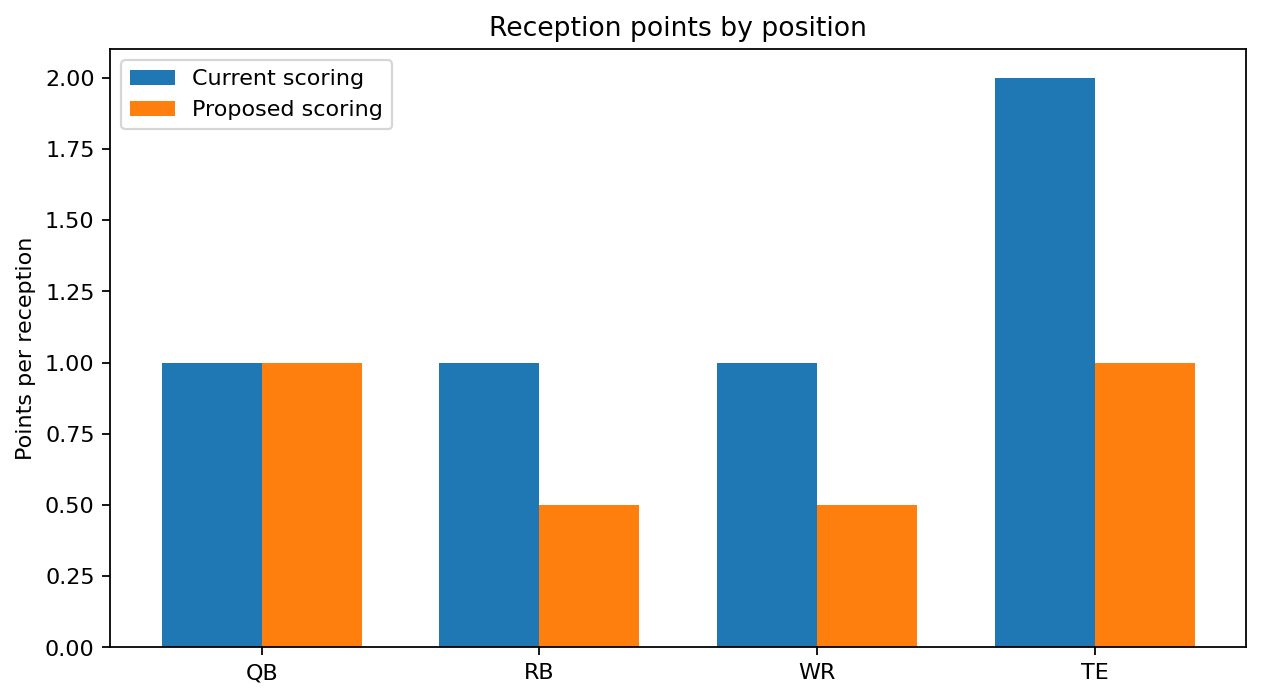

The proposed scoring reduces the reception bonus for RBs and WRs from one point to half a point. QB receptions remain at one point, while TE receptions fall from two points to one. A TE catch still earns twice as much as an RB or WR catch under the proposal, although the extra TE value over RB/WR shrinks from one point to half a point.

Players still earn points for receiving yards and touchdowns; this change only reduces the value of the catch itself for RBs and WRs. The aim is to make reception volume less influential while keeping a clear TE premium.

#### Positional composition across the overall ranking tiers

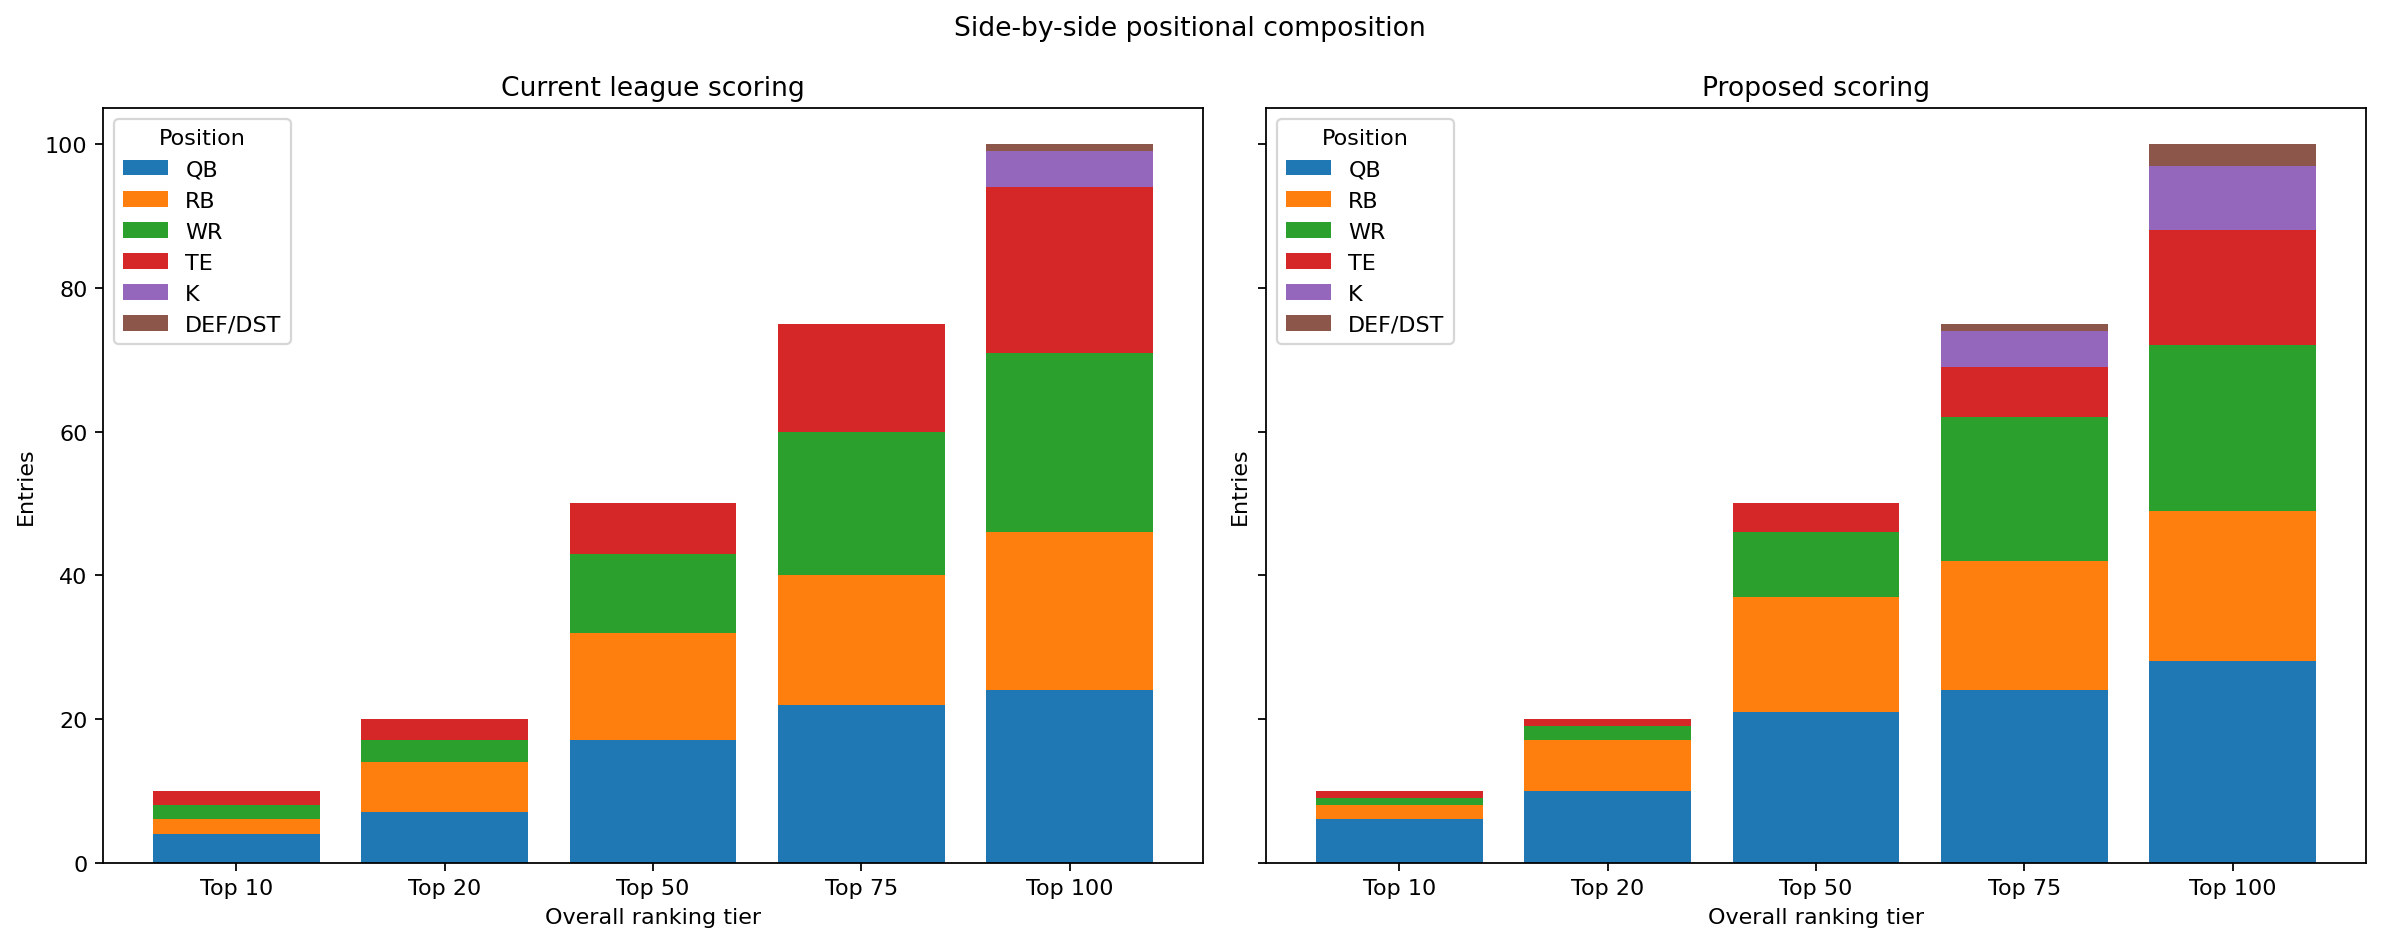

This chart shows how many players from each position appear among the highest-scoring players in the Top 10, 20, 50, 75, and 100. The proposed scoring changes the mix, especially in the larger groups.

Tight ends have the largest decline. Quarterbacks and kickers become more prominent, while RB and WR representation changes less. This matters when building rosters and deciding whether every manager needs to start three WRs.

#### Positional count changes across the ranking tiers

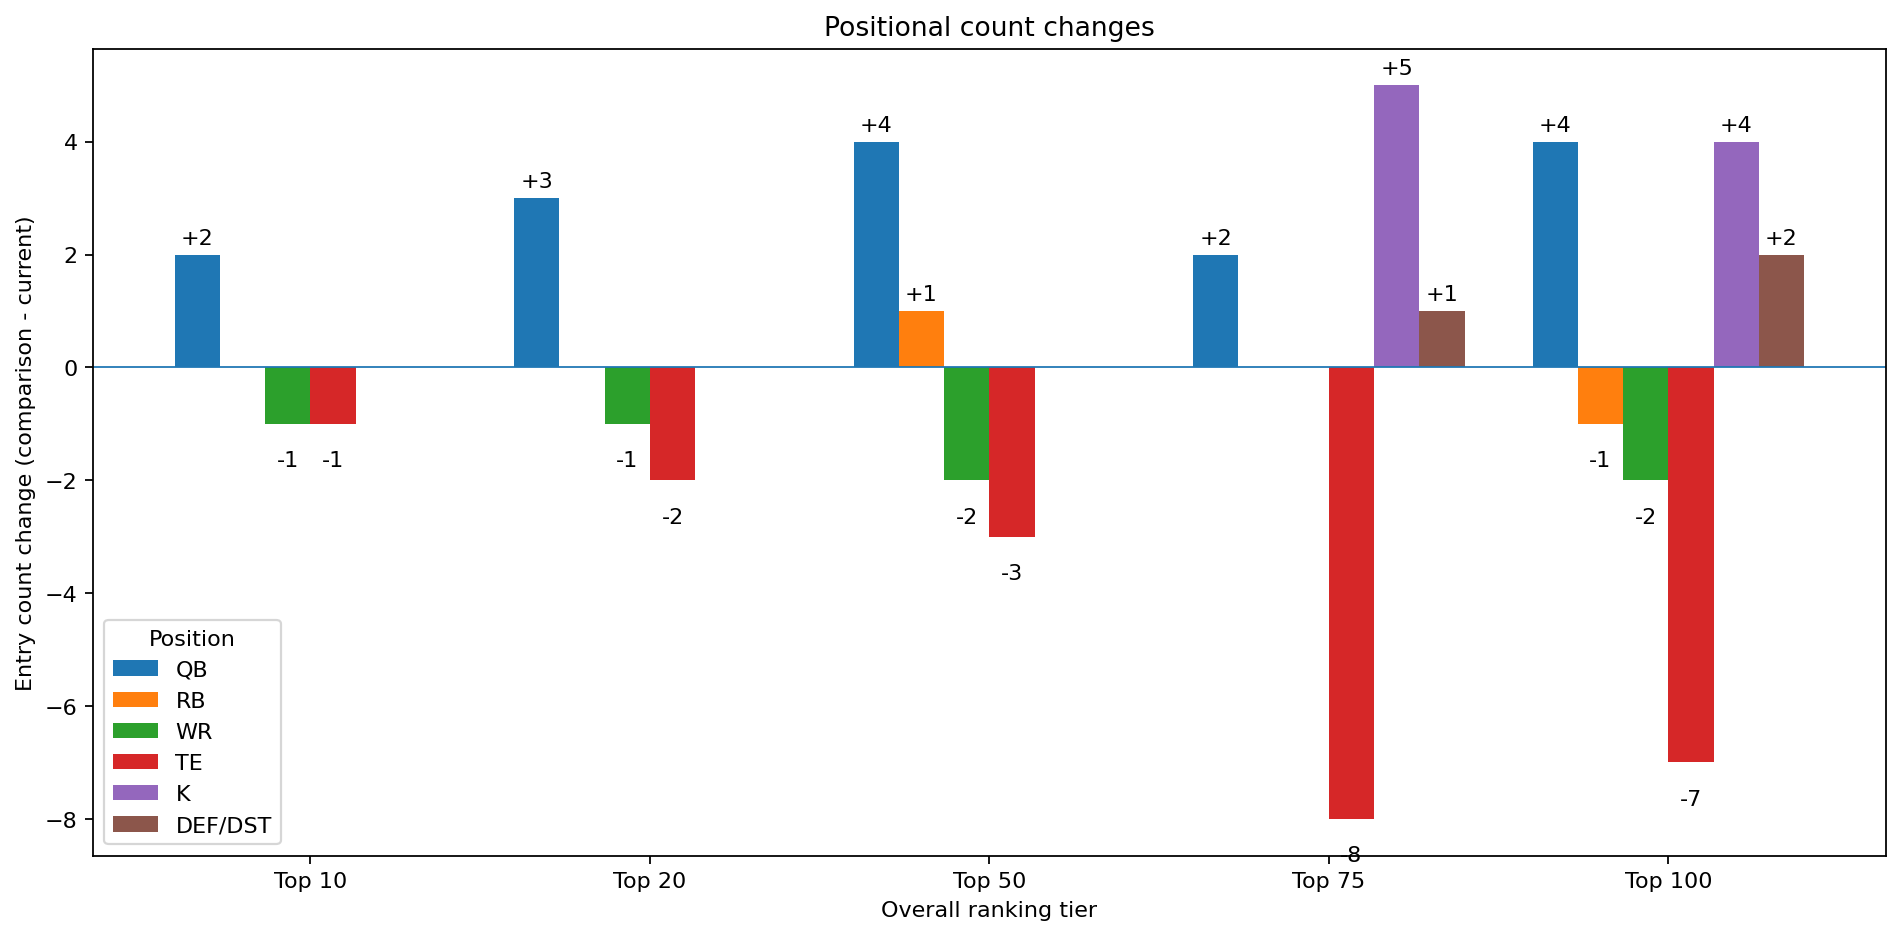

**Top 100 count by position (change = proposed scoring minus current):**

,Position,Current,Proposed scoring,Change
0,QB,24,28,4
1,RB,22,21,-1
2,WR,25,23,-2
3,TE,23,16,-7
4,K,5,9,4
5,DEF/DST,1,3,2


The count-change chart and table show that the Top 75 has eight fewer TEs and the Top 100 has seven fewer. In the Top 100, QBs increase by four and kickers increase by four; RBs decrease by one and WRs by two. Across the five tiers, QB counts rise by 2, 3, 4, 2, and 4; kicker counts rise by five in the Top 75 and four in the Top 100.

RB and WR representation changes less than TE representation. This does not mean kickers became better players; their scores simply compare more favorably after reception points are reduced elsewhere. The change is relevant to roster construction, not a claim that one position is inherently better.

#### Direct-slot starter-to-replacement point gaps

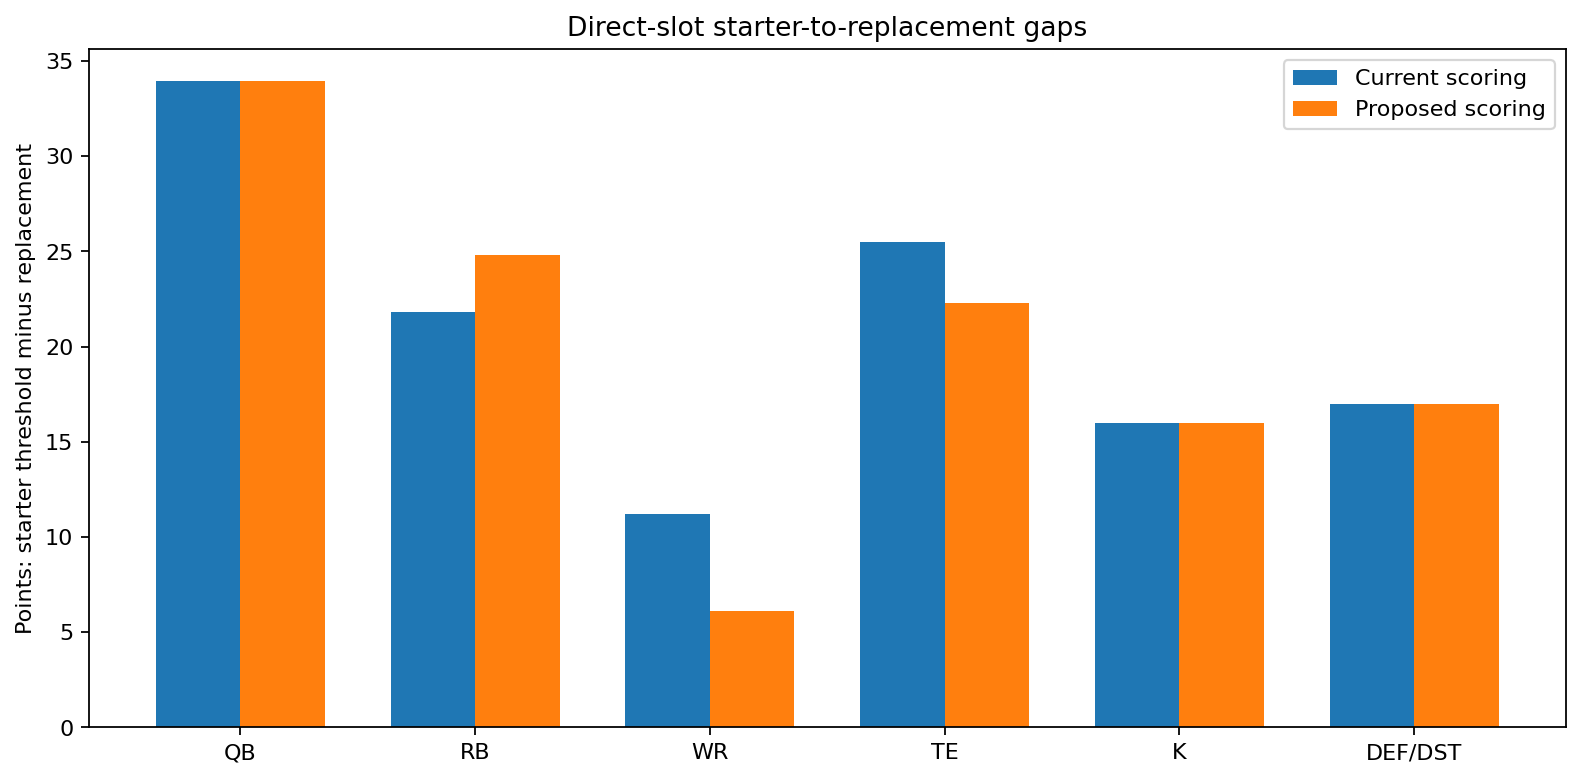

This chart compares the points of a typical starter with a lower-ranked player who could replace them. A larger gap means the starter scores more than the available lower-ranked option.

The WR gap falls from 11.2 to 6.1 points, while the RB gap grows from 21.8 to 24.8. The TE gap declines from 25.5 to 22.3; QB, K, and DEF/DST gaps do not change. This suggests the gap between higher- and lower-ranked WRs is smaller under the proposed scoring, while the RB gap is larger.

If a team's third WR is not much stronger than another eligible player, the manager may prefer to use a productive RB or TE in FLEX. These estimates use direct position slots and do not assign FLEX or SUPER_FLEX demand to a position.

In [3]:
import matplotlib.pyplot as plt


def _save_notebook_figure(fig, filename):
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, dpi=160, bbox_inches="tight")
    plt.close(fig)


# Rebuild notebook-only figures from the latest pipeline tables on each run.
current_distribution = read_report("positional_distribution_current.csv")
comparison_distribution = read_report("positional_distribution_half_ppr_te.csv")
changes = read_report("positional_distribution_changes.csv")

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(4)
labels = ["QB", "RB", "WR", "TE"]
current_rates = [
    current_scoring.get("rec", 0), current_scoring.get("rec", 0),
    current_scoring.get("rec", 0),
    current_scoring.get("rec", 0) + current_scoring.get("bonus_rec_te", 0),
]
comparison_rates = [comparison_reception_points[pos] for pos in labels]
width = 0.36
ax.bar(x - width / 2, current_rates, width, label="Current scoring")
ax.bar(x + width / 2, comparison_rates, width, label="Proposed scoring")
ax.set_xticks(x, labels)
ax.set_ylabel("Points per reception")
ax.set_title("Reception points by position")
ax.legend()
_save_notebook_figure(fig, "story_reception_points_by_position.png")

ranked_all = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "all_ranked_players.csv")
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for ax, position in zip(axes.flat, ["QB", "RB", "WR", "TE", "K", "DEF/DST"]):
    subset = ranked_all.loc[ranked_all["position"].eq(position)]
    for rank_col, points_col, label in [
        ("current_rank", "current_points", "Current scoring"),
        ("comparison_rank", "comparison_points", "Proposed scoring"),
    ]:
        ordered = subset.sort_values(rank_col)
        ordered = ordered.loc[ordered[rank_col].le(100)]
        ax.plot(ordered[rank_col], ordered[points_col], label=label)
    ax.set_title(position)
    ax.set_xlabel("Positional rank")
    ax.set_ylabel("Season points")
axes.flat[0].legend()
fig.suptitle("Corrected season points across positional ranks")
_save_notebook_figure(fig, "story_positional_rank_curves.png")

scarcity = read_report("positional_scarcity.csv")
fig, ax = plt.subplots(figsize=(10, 5))
scarcity_positions = ["QB", "RB", "WR", "TE", "K", "DEF/DST"]
for fmt, label, offset in [
    ("Current scoring", "Current scoring", -0.18),
    (config.COMPARISON_FORMAT_NAME, "Proposed scoring", 0.18),
]:
    rows = scarcity.loc[scarcity["Scoring format"].eq(fmt)].set_index("Position")
    ax.bar(np.arange(len(scarcity_positions)) + offset,
           [rows.loc[pos, "Starter-to-replacement gap"] for pos in scarcity_positions],
           width=0.36, label=label)
ax.set_xticks(np.arange(len(scarcity_positions)), scarcity_positions)
ax.set_ylabel("Points: starter threshold minus replacement")
ax.set_title("Direct-slot starter-to-replacement gaps")
ax.legend()
_save_notebook_figure(fig, "story_starter_replacement_gaps.png")

strength = read_report("team_roster_strength.csv")
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, fmt, title in zip(
    axes, ["Current scoring", config.COMPARISON_FORMAT_NAME],
    ["Current scoring", "Proposed scoring"],
):
    rows = strength.loc[strength["Scoring format"].eq(fmt)].sort_values("Roster ID")
    ax.plot(rows["Team"], rows["Top 3 average points"], marker="o", label="Top 3 average")
    ax.plot(rows["Team"], rows["Top 10 average points"], marker="s", label="Top 10 average")
    ax.set_title(title)
    ax.tick_params(axis="x", labelrotation=75)
    ax.set_ylabel("Season points per player")
    ax.legend()
fig.suptitle("Roster top-end and depth under each scoring format")
_save_notebook_figure(fig, "team_top_end_vs_depth.png")

outcomes = read_report("weekly_team_season_outcomes.csv")
current_outcomes = outcomes.loc[outcomes["Scoring format"].eq("Current scoring")]
comparison_outcomes = outcomes.loc[outcomes["Scoring format"].eq(config.COMPARISON_FORMAT_NAME)]
fig, ax = plt.subplots(figsize=(12, 5))
team_order = current_outcomes.sort_values("Roster ID")["Team"].tolist()
current_sorted = current_outcomes.set_index("Team").reindex(team_order)
comparison_sorted = comparison_outcomes.set_index("Team").reindex(team_order)
width = 0.38
x = np.arange(len(team_order))
ax.bar(x - width / 2, current_sorted["Wins"], width, label="Current scoring")
ax.bar(x + width / 2, comparison_sorted["Wins"], width, label="Proposed scoring")
ax.set_xticks(x, team_order, rotation=65, ha="right")
ax.set_ylabel("Reconstructed wins")
ax.set_title("Season wins with actual starters held fixed")
ax.legend()
_save_notebook_figure(fig, "season_team_wins_comparison.png")

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(current_outcomes["Points for"], comparison_outcomes.set_index("Roster ID").reindex(current_outcomes["Roster ID"])["Points for"])
for _, row in current_outcomes.iterrows():
    comp = comparison_outcomes.loc[comparison_outcomes["Roster ID"].eq(row["Roster ID"])]
    if not comp.empty:
        ax.annotate(str(row["Team"]), (row["Points for"], comp.iloc[0]["Points for"]), fontsize=7)
ax.set_xlabel("Current points for")
ax.set_ylabel("Comparison points for")
ax.set_title("Season points-for comparison by team")
_save_notebook_figure(fig, "season_points_for_rank_comparison.png")

fig, ax = plt.subplots(figsize=(12, 5))
for fmt, label in [("Current scoring", "Current scoring"), (config.COMPARISON_FORMAT_NAME, "Proposed scoring")]:
    rows = outcomes.loc[outcomes["Scoring format"].eq(fmt)].sort_values("Roster ID")
    ax.plot(rows["Team"], rows["Head-to-head win percentage"] * 100, marker="o", label=f"{label}: head-to-head")
    ax.plot(rows["Team"], rows["All-play win percentage"] * 100, marker="s", linestyle="--", label=f"{label}: all-play")
ax.set_ylabel("Win percentage")
ax.set_title("Head-to-head and all-play records by scoring format")
ax.tick_params(axis="x", labelrotation=65)
ax.legend(ncol=2, fontsize=8)
_save_notebook_figure(fig, "season_head_to_head_vs_all_play.png")

by_week = read_report("weekly_by_week_summary.csv")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True)
for ax, column, title in zip(
    axes,
    ["Rate within 5 points (%)", "Rate within 10 points (%)", "Rate within 15 points (%)"],
    ["Within 5 points", "Within 10 points", "Within 15 points"],
):
    for fmt, label in [("Current scoring", "Current scoring"), (config.COMPARISON_FORMAT_NAME, "Proposed scoring")]:
        rows = by_week.loc[by_week["Scoring format"].eq(fmt)].sort_values("Week")
        ax.plot(rows["Week"], rows[column], marker="o", label=label)
    ax.set_title(title)
    ax.set_xlabel("Week")
    ax.set_ylabel("Matchups (%)")
axes[0].legend(fontsize=8)
fig.suptitle("Close-game frequency by week")
_save_notebook_figure(fig, "weekly_close_game_frequency.png")

volatility = read_report("weekly_position_volatility.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, fmt, title in zip(
    axes, ["Current scoring", config.COMPARISON_FORMAT_NAME],
    ["Current scoring", "Proposed scoring"],
):
    rows = volatility.loc[volatility["Scoring format"].eq(fmt)].copy()
    rows = rows.loc[rows["Position"].isin(["QB", "RB", "WR", "TE", "K", "DEF/DST"])]
    y = np.arange(len(rows))
    ax.hlines(y, rows["10th percentile"], rows["90th percentile"], linewidth=3)
    ax.scatter(rows["Median starter points"], y, label="Median")
    ax.set_yticks(y, rows["Position"])
    ax.set_xlabel("Weekly points")
    ax.set_title(title)
axes[0].set_ylabel("Starter position")
_save_notebook_figure(fig, "weekly_starter_score_ranges_by_position.png")

weekly_scores = read_report("weekly_team_scores.csv")
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, column, title in zip(
    axes, ["Current points", "Comparison points"], ["Current scoring", "Proposed scoring"]
):
    for _, rows in weekly_scores.groupby("Team"):
        rows = rows.sort_values("Week")
        ax.plot(rows["Week"], rows[column], marker=".", alpha=0.7, label=rows["Team"].iloc[0])
    ax.set_title(title)
    ax.set_xlabel("Week")
    ax.set_ylabel("Team points")
axes[1].legend(fontsize=6, ncol=2, bbox_to_anchor=(1.03, 1), loc="upper left")
fig.suptitle("Weekly team score variation")
_save_notebook_figure(fig, "weekly_team_score_variation_by_team.png")

matchups = read_report("weekly_matchup_rescoring.csv")
def winner_from_margin(value):
    if np.isclose(value, 0):
        return "Tie"
    return "Team 1" if value > 0 else "Team 2"
matchups["Current winner"] = matchups["Current margin (team 1 - team 2)"].map(winner_from_margin)
matchups["Comparison winner"] = matchups["Comparison margin (team 1 - team 2)"].map(winner_from_margin)
transition = pd.crosstab(matchups["Current winner"], matchups["Comparison winner"]).reindex(
    index=["Team 1", "Team 2", "Tie"], columns=["Team 1", "Team 2", "Tie"], fill_value=0
)
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(transition, cmap="Blues")
ax.set_xticks(range(3), transition.columns)
ax.set_yticks(range(3), transition.index)
ax.set_xlabel("Comparison winner")
ax.set_ylabel("Current winner")
ax.set_title("Weekly winner transitions")
for i in range(3):
    for j in range(3):
        ax.text(j, i, int(transition.iloc[i, j]), ha="center", va="center")
fig.colorbar(image, ax=ax, label="Matchups")
_save_notebook_figure(fig, "weekly_winner_transition_matrix.png")

summary = read_report("weekly_competitiveness_summary.csv").set_index("Scoring format")
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
metrics = [
    ("Average absolute matchup margin", "Average absolute margin (points)"),
    ("Population standard deviation of team scores", "Team-week score spread (points)"),
    ("Outcome flips versus current scoring", "Outcome flips (count)"),
    ("Matchups decided by 10 points or fewer", "Matchups within 10 points (count)"),
]
for ax, (column, title) in zip(axes.flat, metrics):
    vals = [summary.loc[fmt, column] for fmt in ["Current scoring", config.COMPARISON_FORMAT_NAME]]
    ax.bar(["Current", "Comparison"], vals)
    ax.set_title(title)
fig.suptitle("Historical competitiveness evidence")
_save_notebook_figure(fig, "competitiveness_evidence_panels.png")

current = current_distribution.loc[current_distribution["Tier"].eq("Top 100")].iloc[0]
fig, ax = plt.subplots(figsize=(8, 5))
positions = ["QB", "RB", "WR", "TE", "K", "DEF/DST"]
ax.bar(positions, [current[pos] for pos in positions])
ax.set_ylabel("Players in overall Top 100")
ax.set_title("Current-scoring positional composition")
_save_notebook_figure(fig, "positional_composition.png")


def show_figure(filename, title):
    path = FIGURE_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f"Expected chart was not generated: {path}")
    display(Markdown(f"#### {title}"))
    display(Image(filename=str(path)))


show_figure(
    "story_reception_points_by_position.png",
    "Reception points by position under each scoring format",
)

display(Markdown("""The proposed scoring reduces the reception bonus for RBs and WRs from one point to half a point. QB receptions remain at one point, while TE receptions fall from two points to one. A TE catch still earns twice as much as an RB or WR catch under the proposal, although the extra TE value over RB/WR shrinks from one point to half a point.

Players still earn points for receiving yards and touchdowns; this change only reduces the value of the catch itself for RBs and WRs. The aim is to make reception volume less influential while keeping a clear TE premium."""))
show_figure(
    "positional_composition_side_by_side.png",
    "Positional composition across the overall ranking tiers",
)

display(Markdown("""This chart shows how many players from each position appear among the highest-scoring players in the Top 10, 20, 50, 75, and 100. The proposed scoring changes the mix, especially in the larger groups.

Tight ends have the largest decline. Quarterbacks and kickers become more prominent, while RB and WR representation changes less. This matters when building rosters and deciding whether every manager needs to start three WRs."""))
show_figure(
    "positional_count_changes.png",
    "Positional count changes across the ranking tiers",
)

current_top100 = read_report("positional_distribution_current.csv")
comparison_top100 = read_report("positional_distribution_half_ppr_te.csv")

def top_tier_row(frame, tier):
    rows = frame.loc[frame["Tier"].eq(tier)]
    if len(rows) != 1:
        raise ValueError(f"Expected one {tier} row, found {len(rows)}.")
    return rows.iloc[0]


positions = ["QB", "RB", "WR", "TE", "K", "DEF/DST"]
current_row = top_tier_row(current_top100, "Top 100")
comparison_row = top_tier_row(comparison_top100, "Top 100")
top100_counts = pd.DataFrame({
    "Position": positions,
    "Current": [int(current_row[position]) for position in positions],
    "Proposed scoring": [int(comparison_row[position]) for position in positions],
})
top100_counts["Change"] = top100_counts["Proposed scoring"] - top100_counts["Current"]
display(Markdown("**Top 100 count by position (change = proposed scoring minus current):**"))
display(top100_counts)

display(Markdown("""The count-change chart and table show that the Top 75 has eight fewer TEs and the Top 100 has seven fewer. In the Top 100, QBs increase by four and kickers increase by four; RBs decrease by one and WRs by two. Across the five tiers, QB counts rise by 2, 3, 4, 2, and 4; kicker counts rise by five in the Top 75 and four in the Top 100.

RB and WR representation changes less than TE representation. This does not mean kickers became better players; their scores simply compare more favorably after reception points are reduced elsewhere. The change is relevant to roster construction, not a claim that one position is inherently better."""))
show_figure(
    "story_starter_replacement_gaps.png",
    "Direct-slot starter-to-replacement point gaps",
)

display(Markdown("""This chart compares the points of a typical starter with a lower-ranked player who could replace them. A larger gap means the starter scores more than the available lower-ranked option.

The WR gap falls from 11.2 to 6.1 points, while the RB gap grows from 21.8 to 24.8. The TE gap declines from 25.5 to 22.3; QB, K, and DEF/DST gaps do not change. This suggests the gap between higher- and lower-ranked WRs is smaller under the proposed scoring, while the RB gap is larger.

If a team's third WR is not much stronger than another eligible player, the manager may prefer to use a productive RB or TE in FLEX. These estimates use direct position slots and do not assign FLEX or SUPER_FLEX demand to a position."""))

The scoring charts describe player value at the league level. The next section uses the current ownership snapshot to show what each roster has available; roster depth and lineup options depend on both player production and legal slot eligibility.

## 2 - What does each team have to work with?

### 2A - Roster depth by position

Each heatmap cell shows the average points per game from up to two rostered players at that position. The companion count chart shows how many rostered players at each position have appeared in a game this season. Owning more players does not necessarily mean a team has stronger options; their production matters too.

Points per game use season-to-date points divided by Sleeper's games-active count when available. Weekly active-game records are used when that count is missing. Players without a usable game count remain in the roster reports, but are left out of per-game lineup comparisons. The appendix retains the game-count and data-quality details.

#### Top-two roster production by position (points per game)

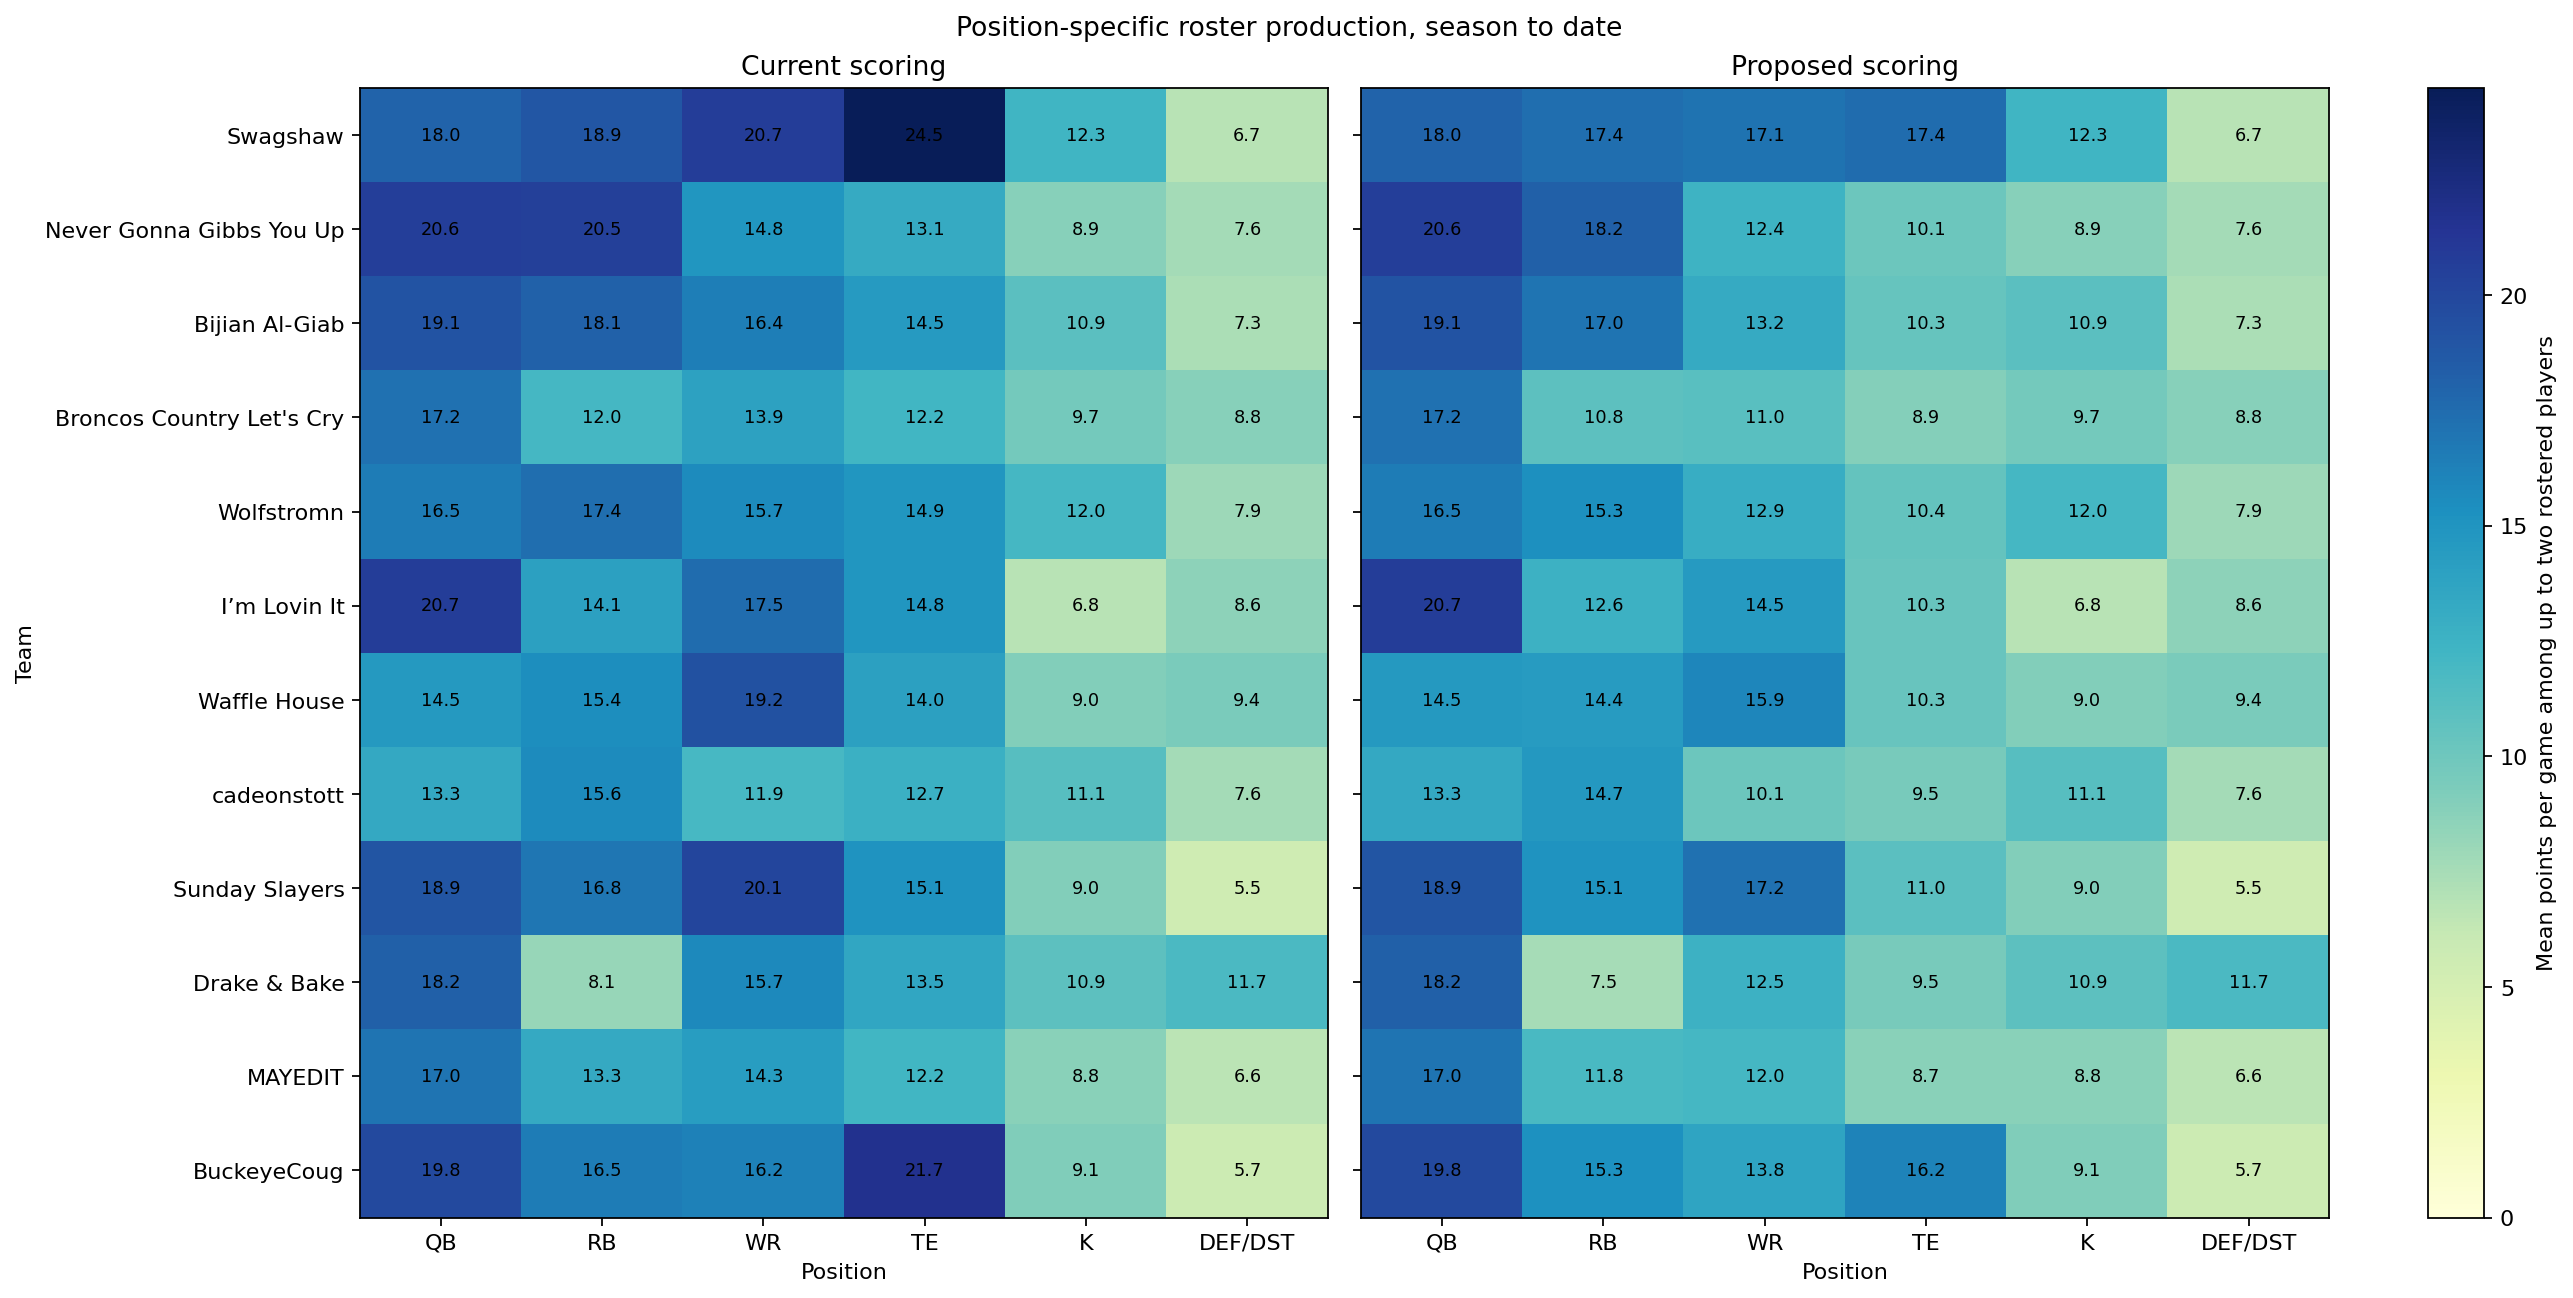

This chart compares the average season-to-date points per game from each team's top two players at each position. The effect varies with the players on each roster.

RB, WR, and TE production is affected by the lower reception values; QB production is unchanged. Some teams have more production at TE, while others are stronger at RB or WR. This is a snapshot of current rosters and past production, not a prediction of future results.

#### Rostered players with a recorded game by position

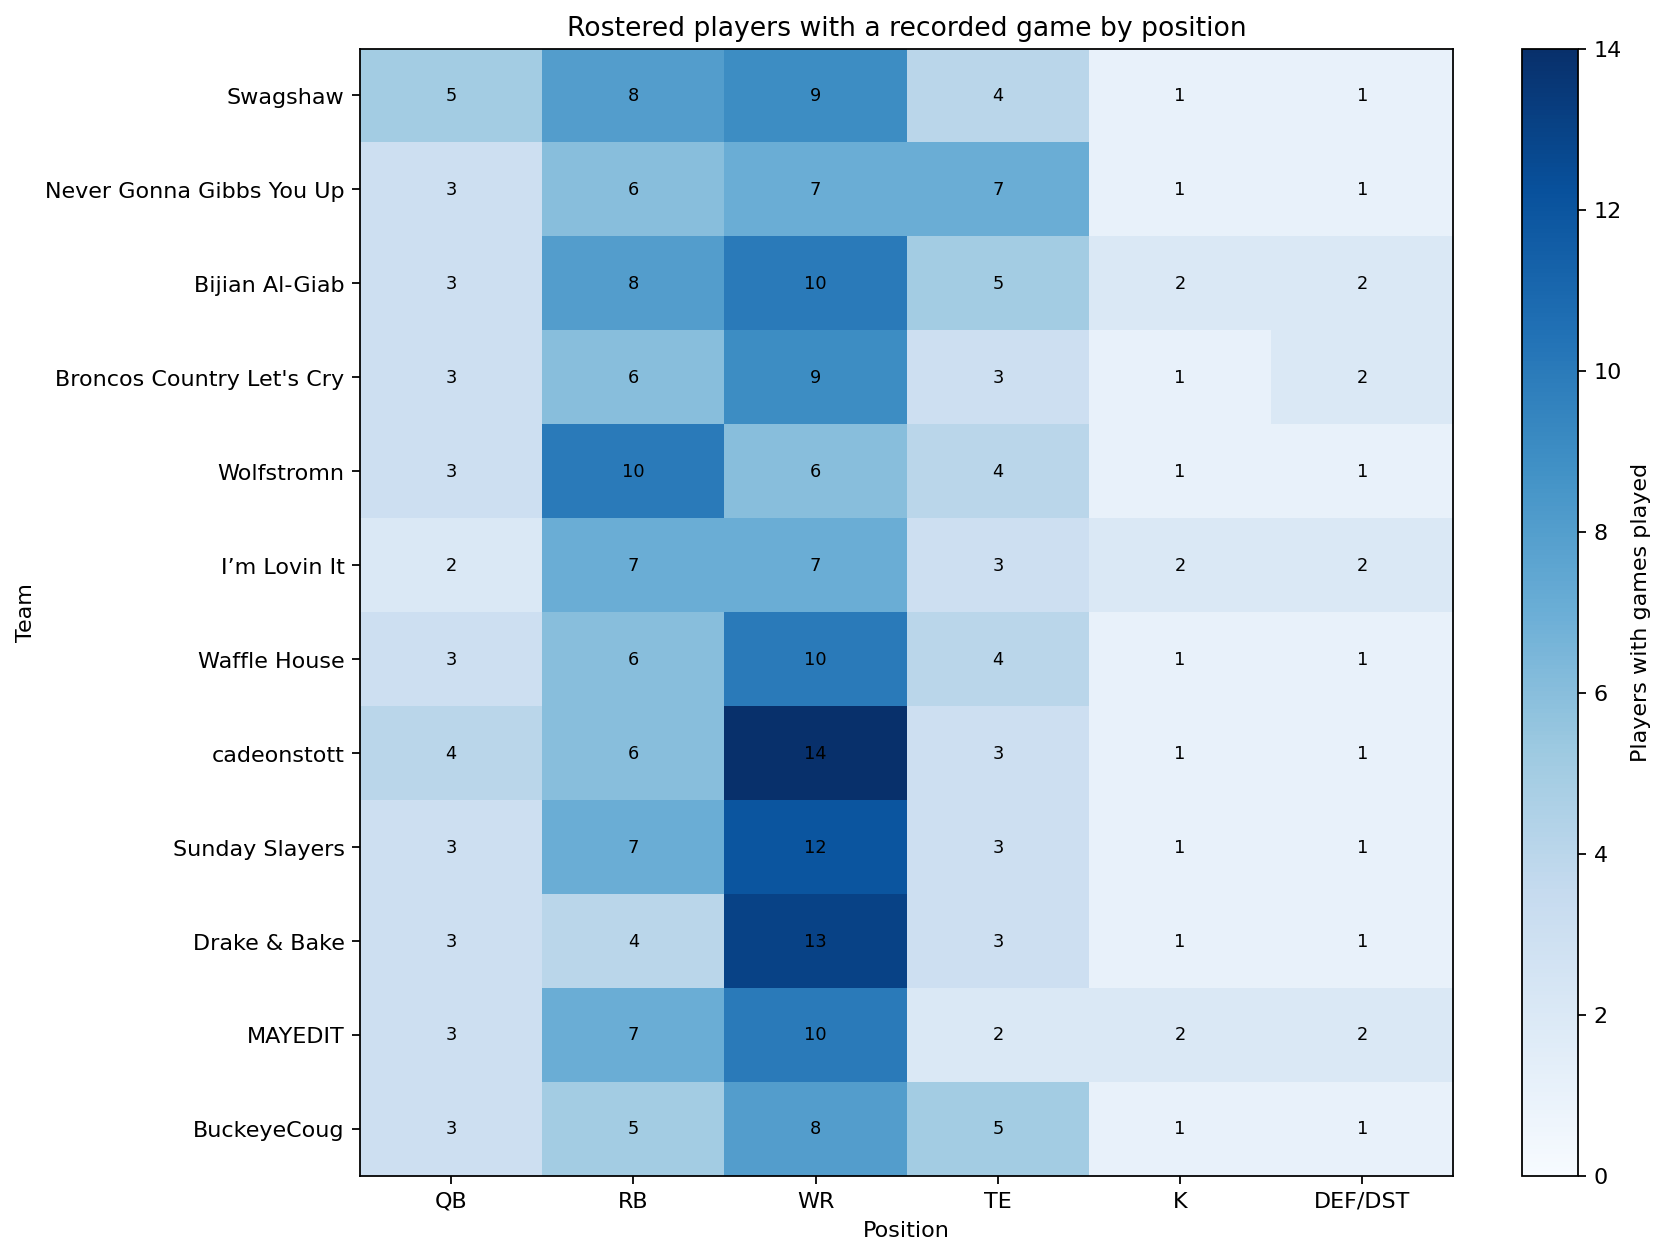

This chart shows how many players at each position on each team have appeared in a game this season. It helps show how each roster is built: some teams have more WRs, while others have more RB or TE depth.

Owning more players does not automatically mean having a stronger roster. The next charts look at whether those players produce enough to compete for a starting spot.

In [4]:
show_figure(
    "team_roster_depth_top2_ppg.png",
    "Top-two roster production by position (points per game)",
)

display(Markdown("""This chart compares the average season-to-date points per game from each team's top two players at each position. The effect varies with the players on each roster.

RB, WR, and TE production is affected by the lower reception values; QB production is unchanged. Some teams have more production at TE, while others are stronger at RB or WR. This is a snapshot of current rosters and past production, not a prediction of future results."""))
show_figure(
    "team_roster_depth_player_counts.png",
    "Rostered players with a recorded game by position",
)

display(Markdown("""This chart shows how many players at each position on each team have appeared in a game this season. It helps show how each roster is built: some teams have more WRs, while others have more RB or TE depth.

Owning more players does not automatically mean having a stronger roster. The next charts look at whether those players produce enough to compete for a starting spot."""))

### 2B - How strong is each team's best possible lineup?

Each player can fill only one starter spot, and the lineup follows Sleeper's position rules. Standard FLEX accepts RB, WR, or TE; SUPER_FLEX can also accept QB. The charts use each player's season-to-date points per game to find the strongest legal combination. This is a retrospective best-lineup comparison, not an actual submitted lineup or a forecast.

#### Best legal lineup points per game across scenarios A through D

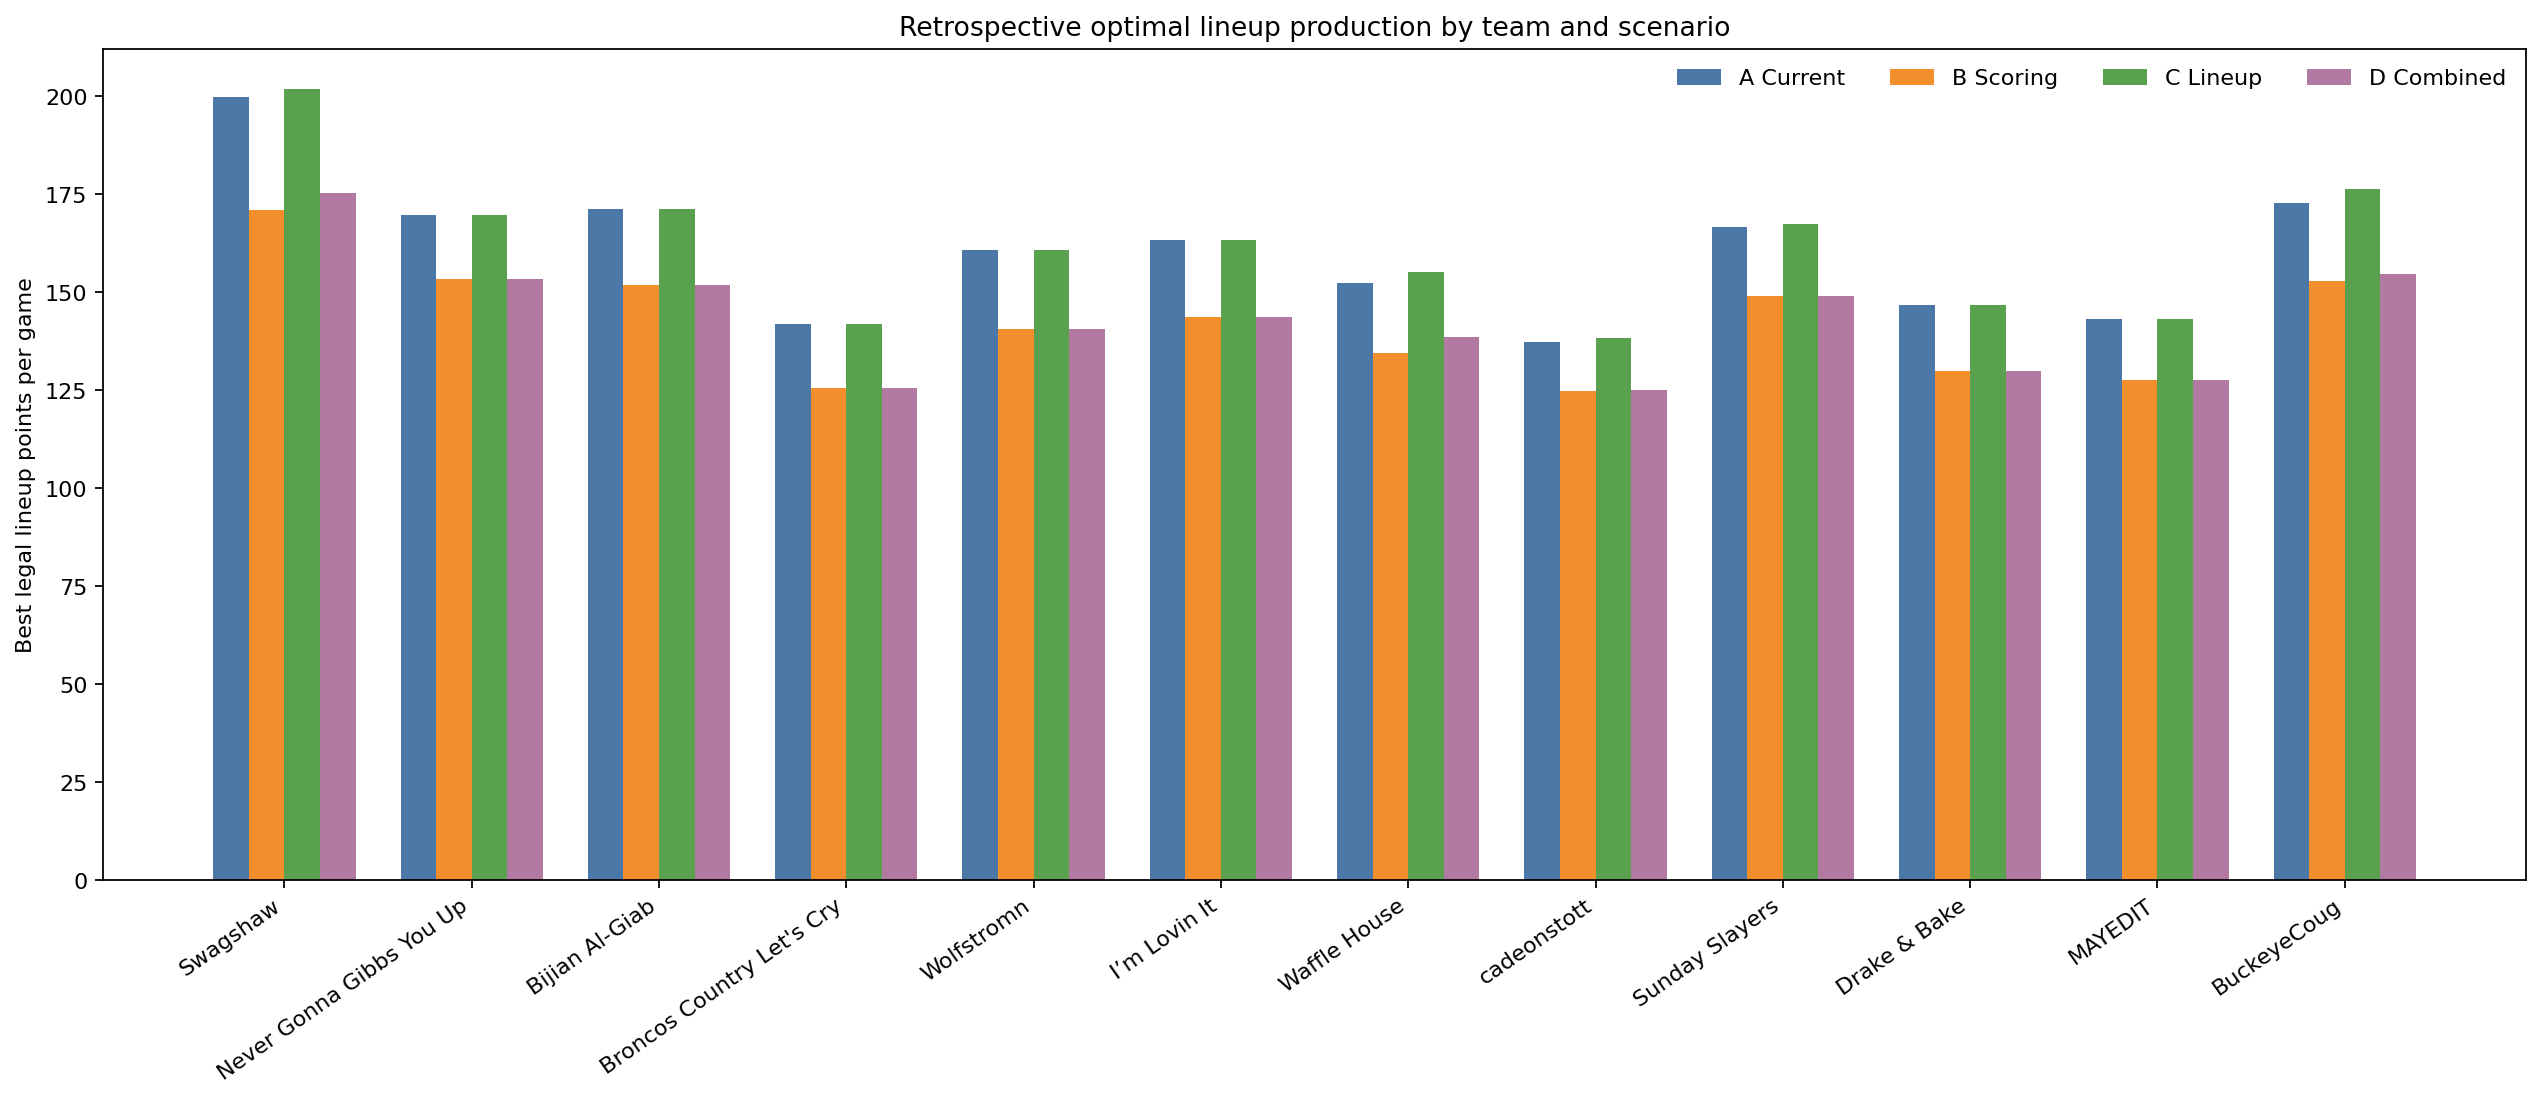

This chart asks what each team's strongest legal starting lineup could score using the production recorded so far this season. It compares four cases:

- A: current scoring and current lineup.
- B: proposed scoring and current lineup.
- C: current scoring and proposed lineup.
- D: proposed scoring and proposed lineup.

The scoring change lowers point totals because receptions are worth less; that change in scale does not by itself mean a team is worse. The lineup-only comparison shows whether a team can use a productive RB, WR, or TE in the additional FLEX spot instead of leaving them on the bench.

Results differ by team. This is a best-case look at recorded production, not a lineup managers actually submitted or what they could have known before games.

#### Scoring, lineup, and combined changes

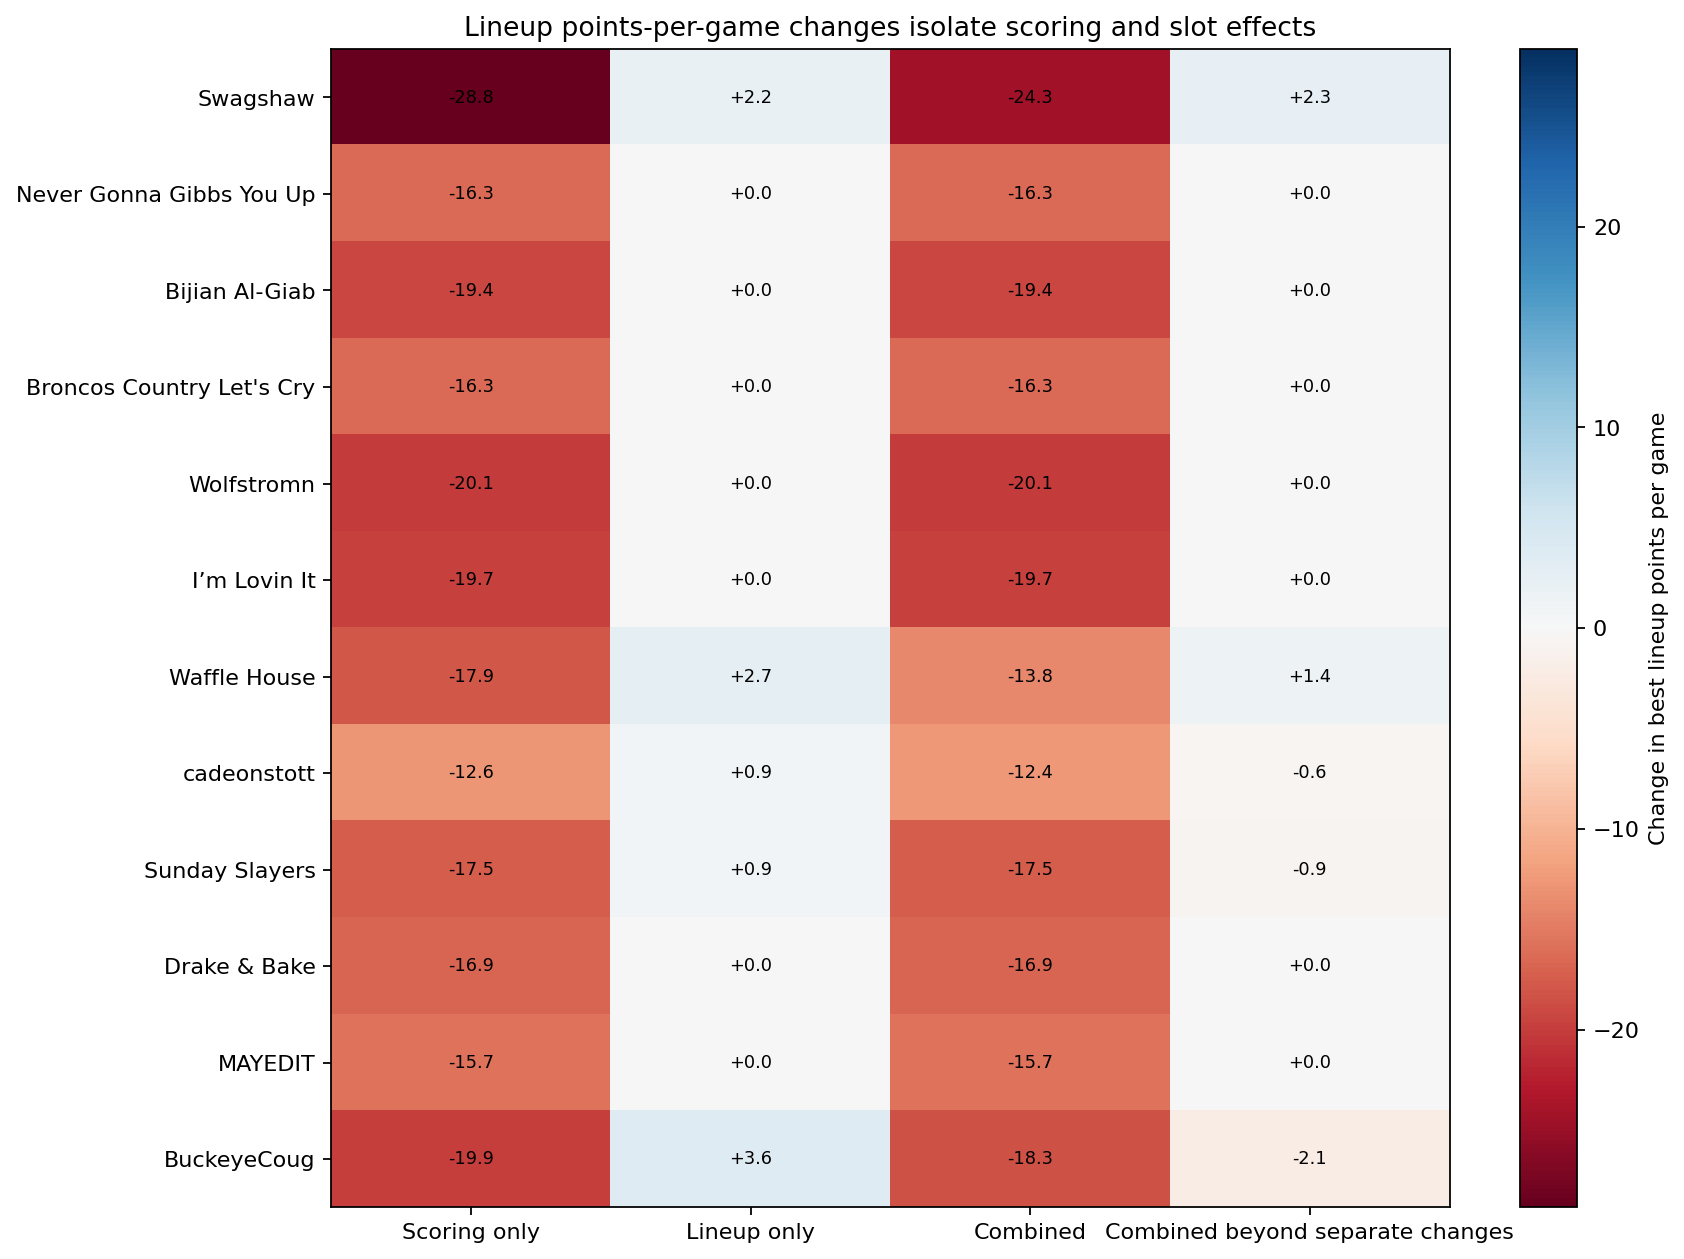

This chart separates the scoring change, the extra FLEX, and both changes together. The scoring-only result changes point values while keeping the lineup the same. The lineup-only result adds FLEX while keeping current scoring. The combined result includes both.

Under current scoring, the extra FLEX raises the best lineup by 3.62 points per game for BuckeyeCoug, 2.74 for Waffle House, 2.24 for Swagshaw, 0.90 for Sunday Slayers, and 0.88 for cadeonstott. The other seven teams show no lineup-only change.

The scoring-only change lowers every team's best-lineup total because the reception values are lower. The extra FLEX helps some teams use productive players who otherwise might stay on the bench, but it does not improve every lineup.

In [5]:
show_figure(
    "team_best_lineup_four_scenarios.png",
    "Best legal lineup points per game across scenarios A through D",
)

display(Markdown("""This chart asks what each team's strongest legal starting lineup could score using the production recorded so far this season. It compares four cases:

- A: current scoring and current lineup.
- B: proposed scoring and current lineup.
- C: current scoring and proposed lineup.
- D: proposed scoring and proposed lineup.

The scoring change lowers point totals because receptions are worth less; that change in scale does not by itself mean a team is worse. The lineup-only comparison shows whether a team can use a productive RB, WR, or TE in the additional FLEX spot instead of leaving them on the bench.

Results differ by team. This is a best-case look at recorded production, not a lineup managers actually submitted or what they could have known before games."""))
show_figure(
    "team_lineup_change_components.png",
    "Scoring, lineup, and combined changes",
)

display(Markdown("""This chart separates the scoring change, the extra FLEX, and both changes together. The scoring-only result changes point values while keeping the lineup the same. The lineup-only result adds FLEX while keeping current scoring. The combined result includes both.

Under current scoring, the extra FLEX raises the best lineup by 3.62 points per game for BuckeyeCoug, 2.74 for Waffle House, 2.24 for Swagshaw, 0.90 for Sunday Slayers, and 0.88 for cadeonstott. The other seven teams show no lineup-only change.

The scoring-only change lowers every team's best-lineup total because the reception values are lower. The extra FLEX helps some teams use productive players who otherwise might stay on the bench, but it does not improve every lineup."""))

### 2C - How many other players could compete for a starting spot?

A player counts as another possible choice if they have played and are within three or five points per game of at least one starting spot they are eligible to fill. Each player is counted once, even if they could fill more than one spot. These ranges help show which alternatives are close in production; they are not official cutoffs for a good player or a recommended start.

#### Additional position-eligible options within 3- and 5-point tolerances

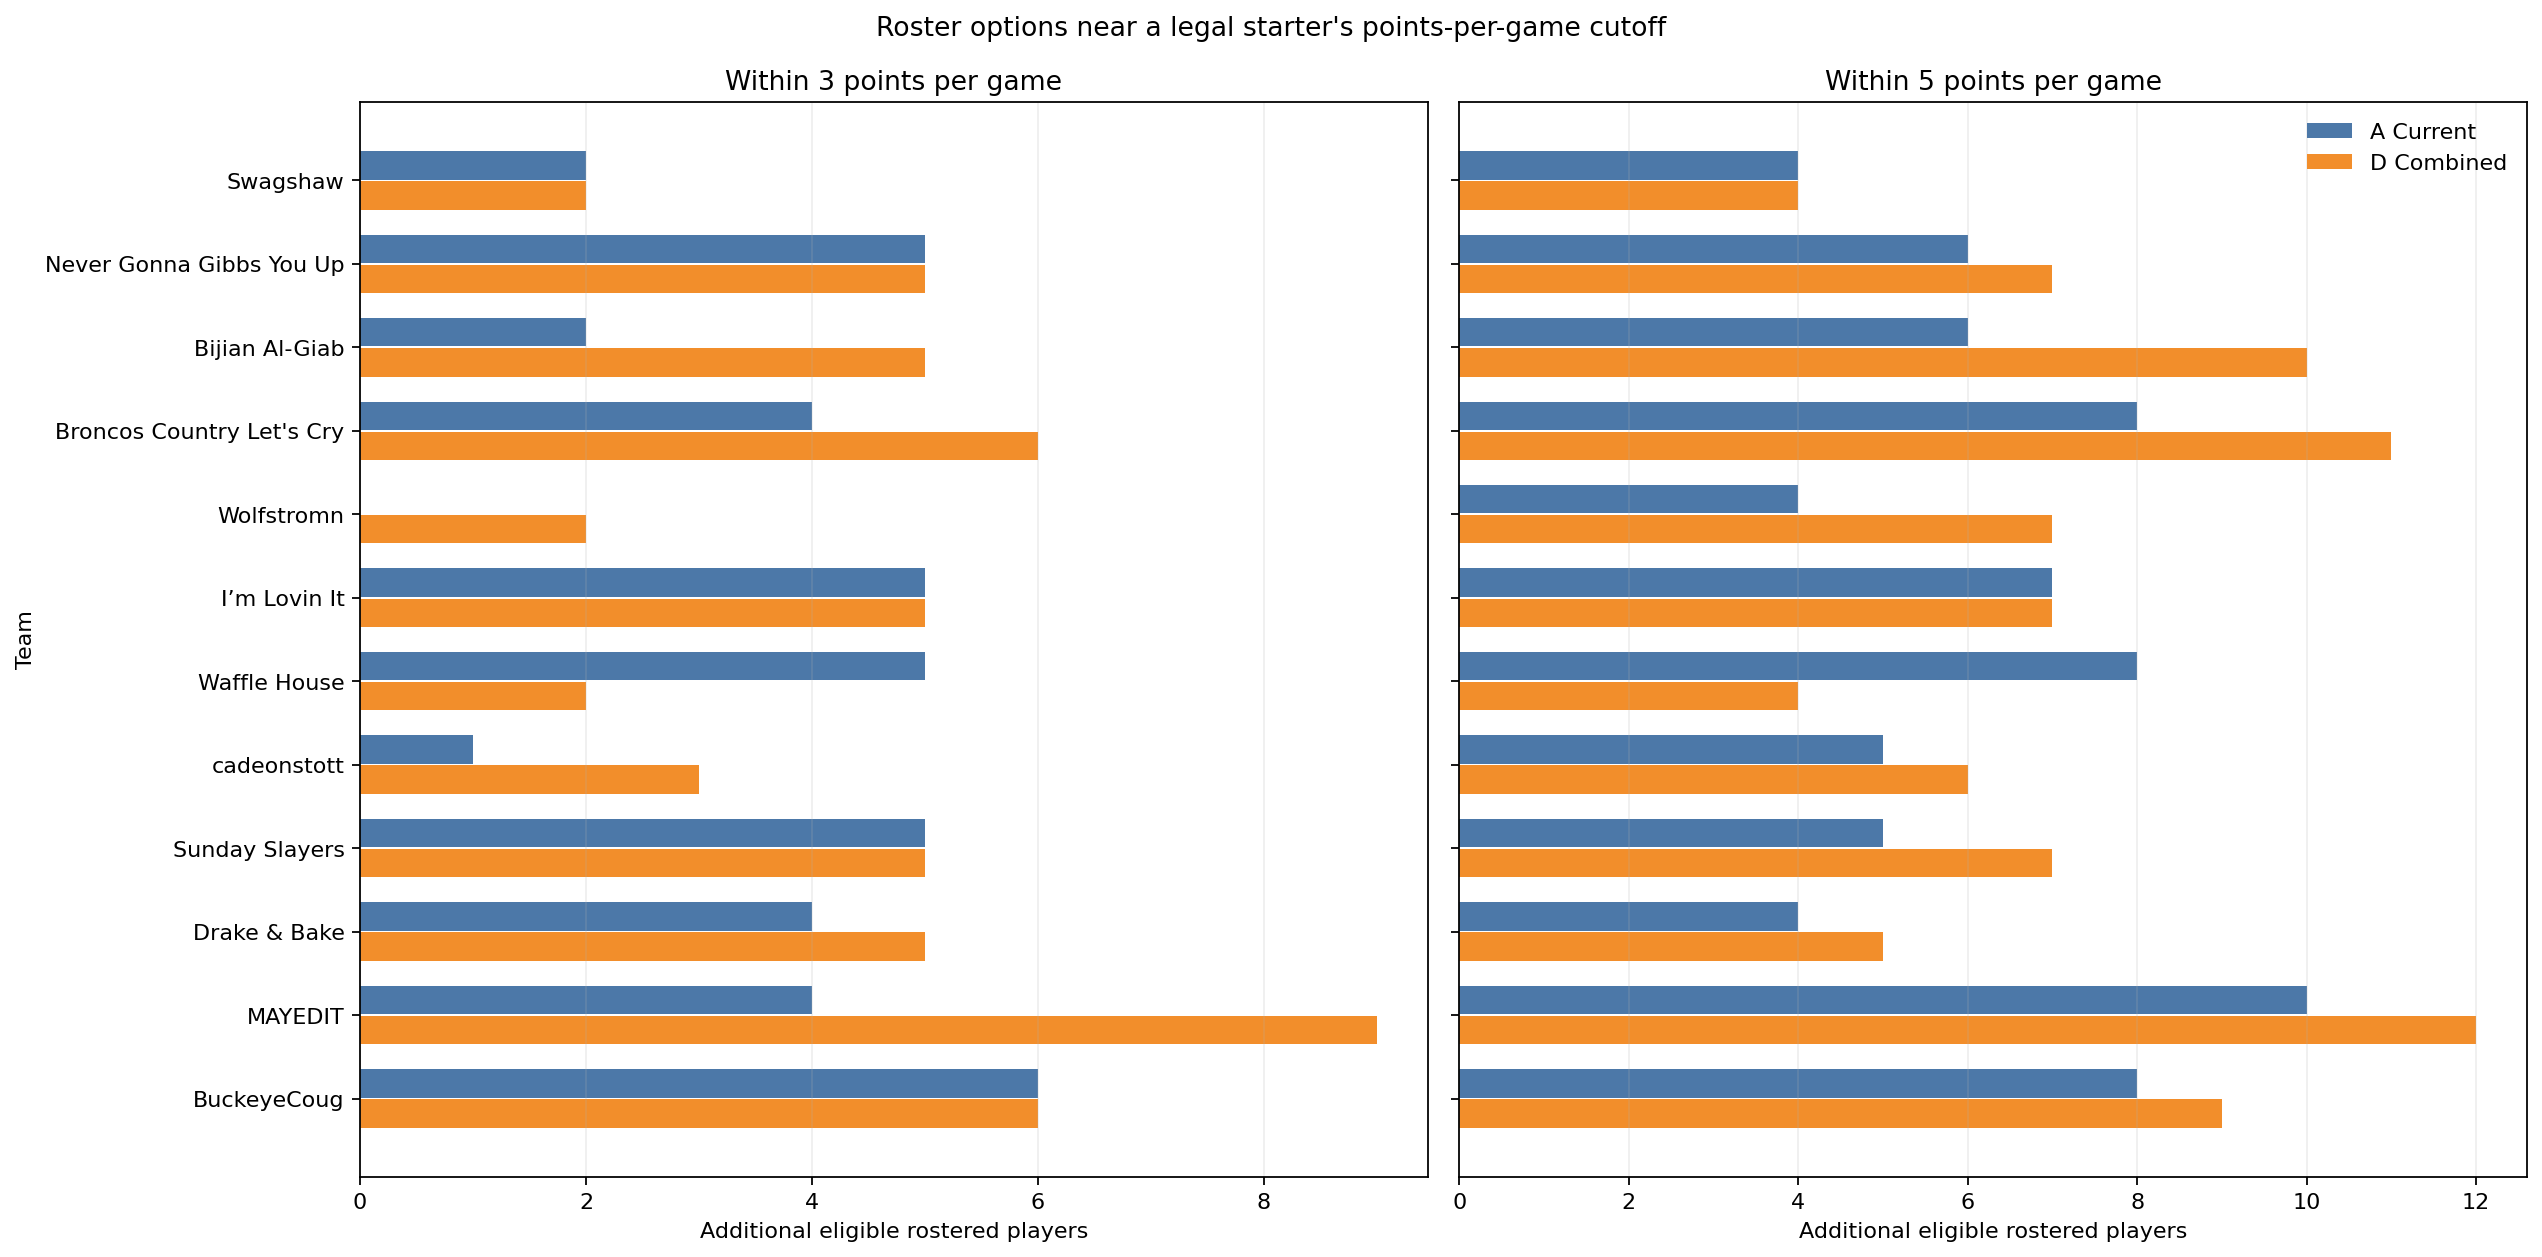

This chart looks beyond the best lineup and counts other rostered players who are close in points per game to a starting choice. It compares players within three points and within five points per game. Those distances are just a way to show how close the choices are, not official cutoffs for a good player.

Under the combined proposal, MAYEDIT gains five options within three points per game. Waffle House has three fewer within three points and four fewer within five. Other teams gain, lose, or keep the same number of alternatives. These are possible choices, not guaranteed starting-caliber players.

#### Closest legal starter-to-bench alternative by team

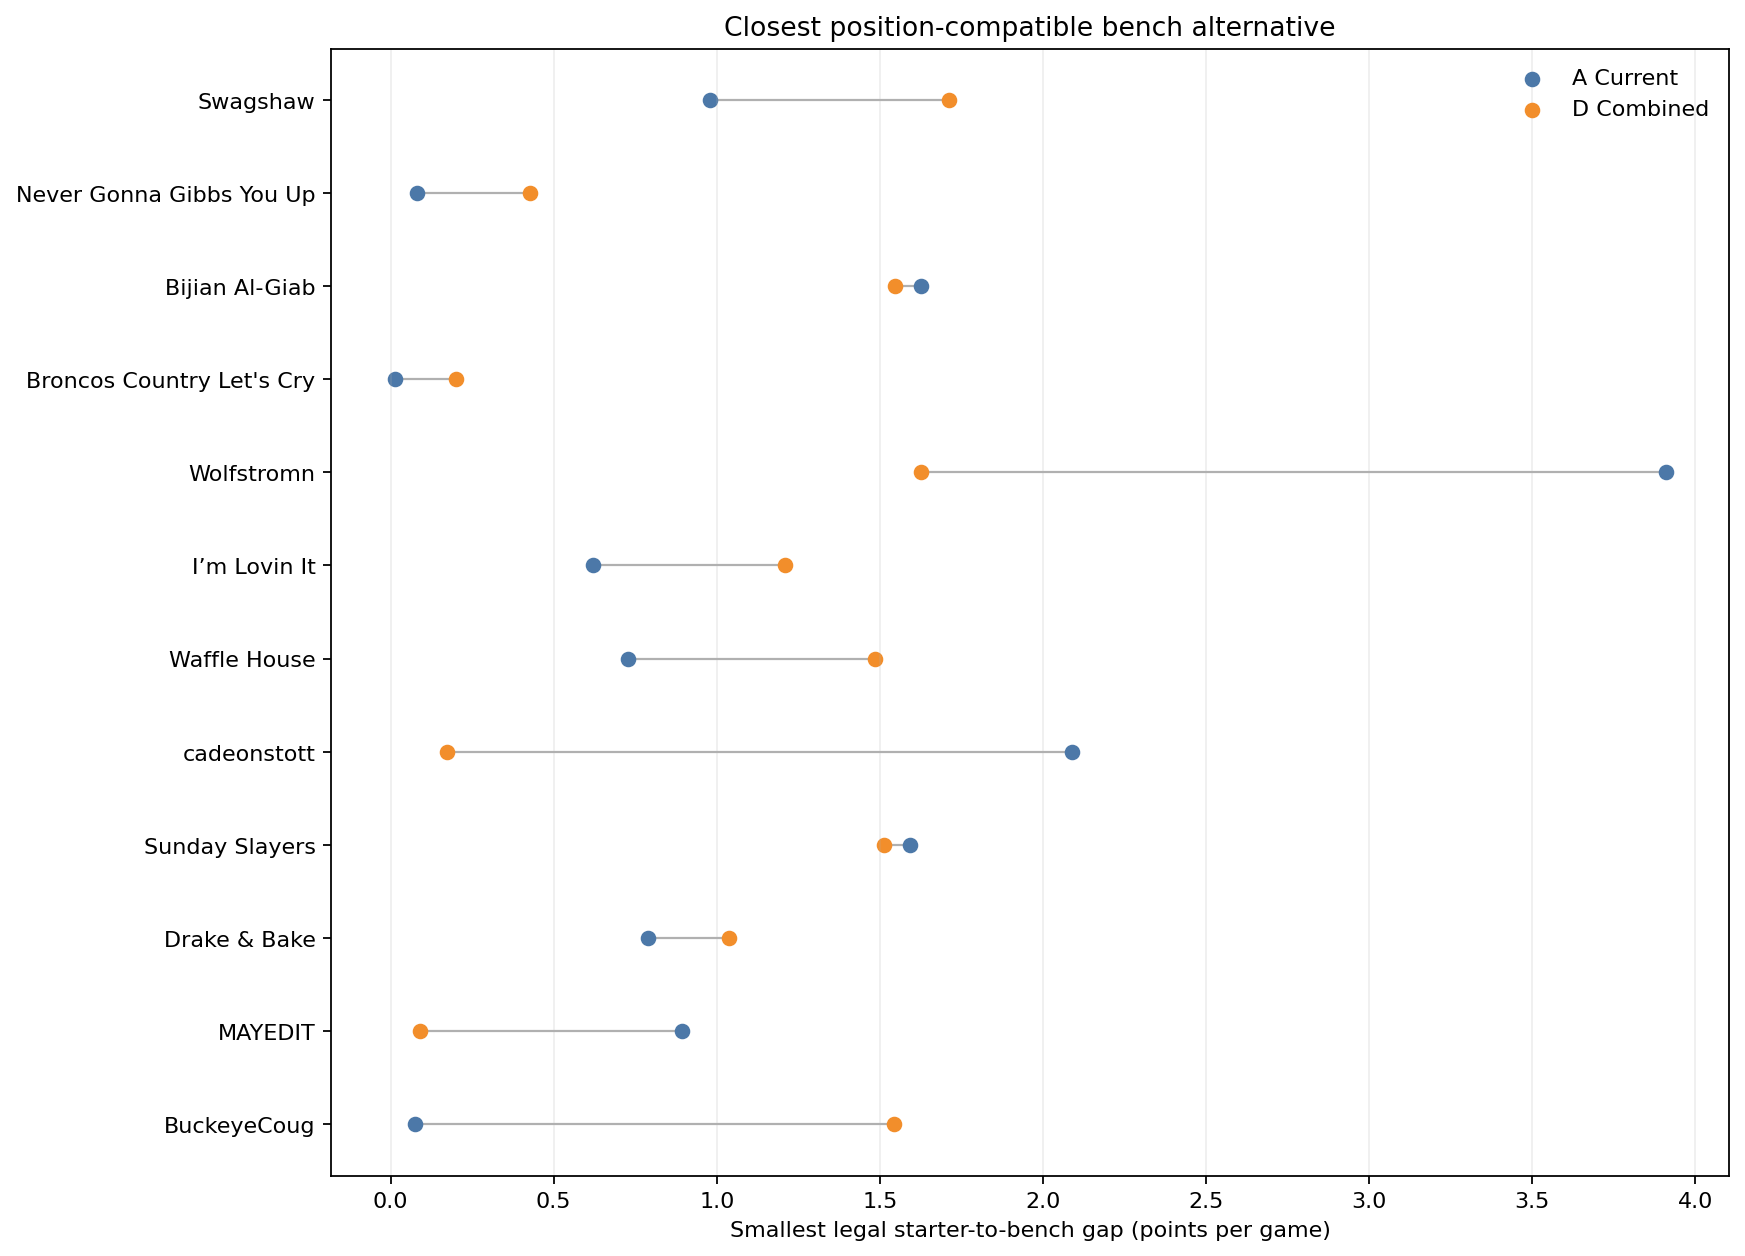

This chart compares a selected starter with the closest bench player who is eligible to fill that position. A small gap means a close alternative is available; a large gap means the starter is considerably more productive.

Read this alongside the previous chart: one close alternative does not necessarily mean the team has several good choices.

In [6]:
show_figure(
    "team_viable_options_sensitivity.png",
    "Additional position-eligible options within 3- and 5-point tolerances",
)

display(Markdown("""This chart looks beyond the best lineup and counts other rostered players who are close in points per game to a starting choice. It compares players within three points and within five points per game. Those distances are just a way to show how close the choices are, not official cutoffs for a good player.

Under the combined proposal, MAYEDIT gains five options within three points per game. Waffle House has three fewer within three points and four fewer within five. Other teams gain, lose, or keep the same number of alternatives. These are possible choices, not guaranteed starting-caliber players."""))
show_figure(
    "team_starter_bench_cutoff_gap.png",
    "Closest legal starter-to-bench alternative by team",
)

display(Markdown("""This chart compares a selected starter with the closest bench player who is eligible to fill that position. A small gap means a close alternative is available; a large gap means the starter is considerably more productive.

Read this alongside the previous chart: one close alternative does not necessarily mean the team has several good choices."""))

### 2D - How much FLEX depth does each team have?

FLEX candidates are rostered RB, WR, and TE players who have played this season. The chart shows the available pool and which positions fill the standard FLEX spots in each scenario. Team changes compare scoring only (B minus A), lineup only (C minus A), and both changes together (D minus A). The final comparison, D minus B minus C plus A, shows whether the combined result differs from simply adding the separate effects. These are descriptive comparisons, not predictions.

#### Rostered FLEX candidate pool and optimized standard FLEX usage

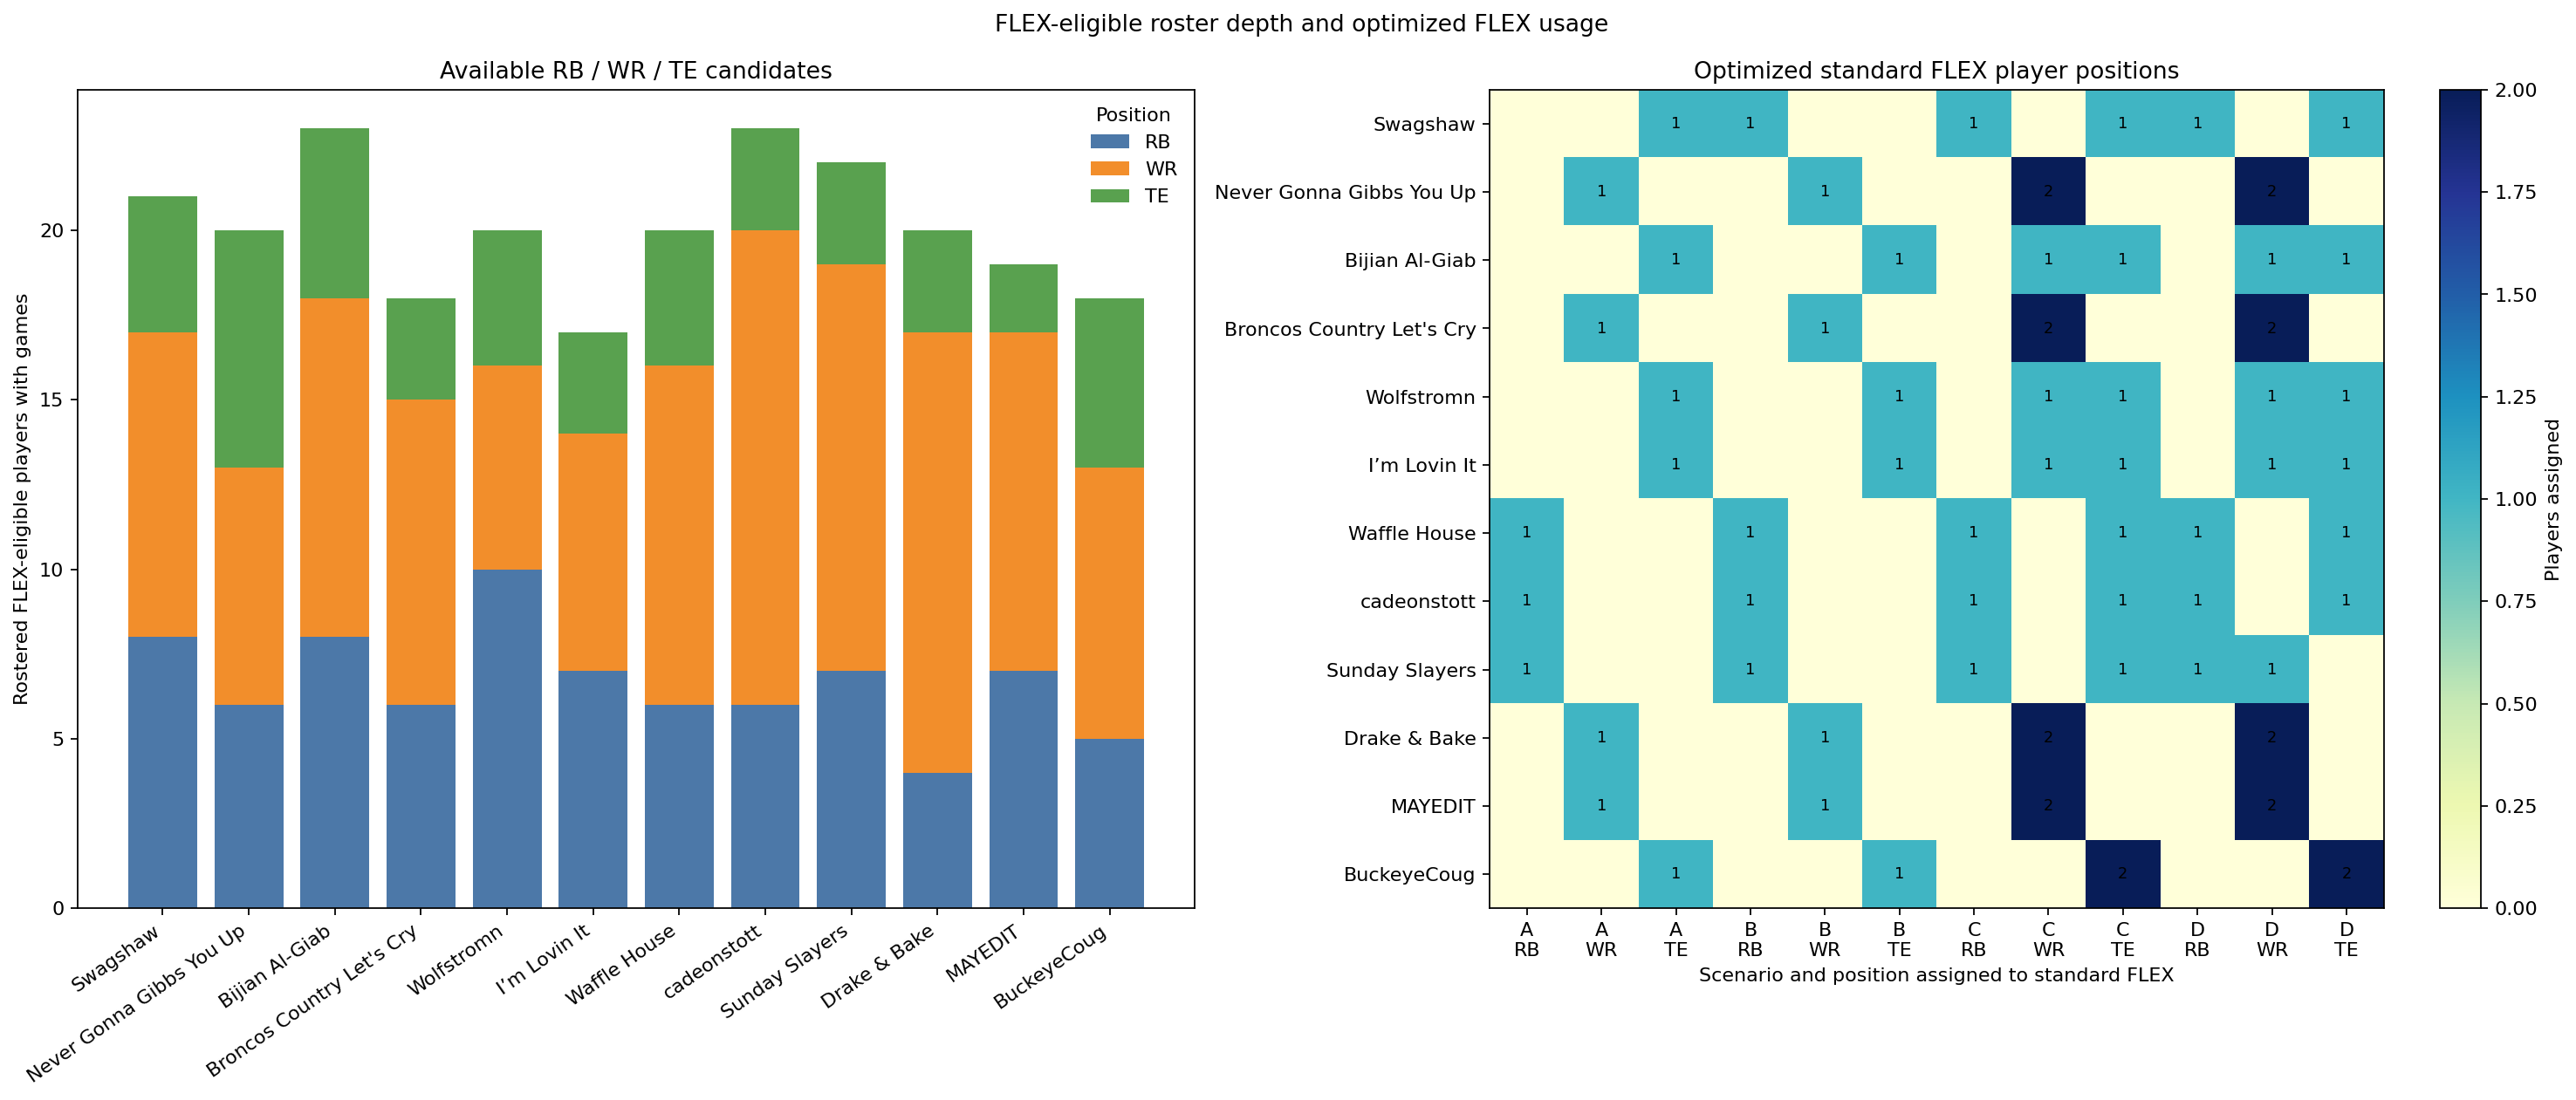

This chart focuses on RBs, WRs, and TEs who can compete for FLEX positions. It shows how many candidates each team has and which positions fill the standard FLEX spots in the four scenarios.

The strongest FLEX choice is not always a WR; an RB or TE may provide more points for a particular team. That is the main purpose of the extra FLEX: managers can choose the strongest available mix of RBs, WRs, and TEs rather than being required to start a third WR. A larger candidate pool helps only when those players produce enough to compete for a starting role.

,Team,"Scoring-only lineup change (B minus A, points per game)","Lineup-only change (C minus A, points per game)","Combined proposal change (D minus A, points per game)","Combined change beyond separate changes (D minus B minus C plus A, points per game)",Additional options within 3 PPG change (D minus A),Additional options within 5 PPG change (D minus A)
0,Swagshaw,-28.84,2.24,-24.29,2.30,0,0
1,Never Gonna Gibbs You Up,-16.34,0.00,-16.34,0.00,0,1
2,Bijian Al-Giab,-19.37,0.00,-19.37,0.00,3,4
3,Broncos Country Let's Cry,-16.32,0.00,-16.32,0.00,2,3
4,Wolfstromn,-20.08,0.00,-20.08,0.00,2,3
5,I’m Lovin It,-19.68,0.00,-19.68,0.00,0,0
6,Waffle House,-17.87,2.74,-13.76,1.37,-3,-4
7,cadeonstott,-12.64,0.88,-12.40,-0.63,2,1
8,Sunday Slayers,-17.49,0.90,-17.49,-0.90,0,2
9,Drake & Bake,-16.86,0.00,-16.86,0.00,1,1


This table brings the roster comparisons together for all 12 teams. Five teams improve their best possible lineup under the lineup-only change, with gains from 0.88 to 3.62 points per game; seven teams are unchanged. The additional-choice columns also show that flexibility differs by roster: some teams gain alternatives, some change little, and Waffle House loses potential alternatives under both comparisons.

The proposal offers managers more freedom to use their players. It does not guarantee that every team will score more or have a stronger lineup.

In [7]:
show_figure(
    "team_flex_candidate_depth.png",
    "Rostered FLEX candidate pool and optimized standard FLEX usage",
)

display(Markdown("""This chart focuses on RBs, WRs, and TEs who can compete for FLEX positions. It shows how many candidates each team has and which positions fill the standard FLEX spots in the four scenarios.

The strongest FLEX choice is not always a WR; an RB or TE may provide more points for a particular team. That is the main purpose of the extra FLEX: managers can choose the strongest available mix of RBs, WRs, and TEs rather than being required to start a third WR. A larger candidate pool helps only when those players produce enough to compete for a starting role."""))
impact_columns = [
    "Team",
    "Scoring-only lineup change (B minus A, points per game)",
    "Lineup-only change (C minus A, points per game)",
    "Combined proposal change (D minus A, points per game)",
    "Interaction effect (D - B - C + A, points per game)",
    "Additional options within 3 PPG change (D minus A)",
    "Additional options within 5 PPG change (D minus A)",
]
display(
    lineup_impact[impact_columns]
    .rename(columns={
        "Interaction effect (D - B - C + A, points per game)":
            "Combined change beyond separate changes (D minus B minus C plus A, points per game)"
    })
    .round(2)
    .reset_index(drop=True)
)

display(Markdown("""This table brings the roster comparisons together for all 12 teams. Five teams improve their best possible lineup under the lineup-only change, with gains from 0.88 to 3.62 points per game; seven teams are unchanged. The additional-choice columns also show that flexibility differs by roster: some teams gain alternatives, some change little, and Waffle House loses potential alternatives under both comparisons.

The proposal offers managers more freedom to use their players. It does not guarantee that every team will score more or have a stronger lineup."""))

## 3 - Does the format change weekly competition?

The historical matchup charts keep each team's actual starters fixed and change scoring only. They compare current scoring with proposed scoring; they do not simulate the additional FLEX. Current rosters cannot reliably show who each team owned in earlier weeks, so the historical results do not model the combined proposal.

,Scoring format,Average absolute matchup margin,Outcome flips versus current scoring,Matchup rate within 5 points (%)
0,Current scoring,40.43,2,6.25
1,QB/TE PPR + RB/WR half-PPR,36.34,2,6.25


#### Average absolute historical matchup margin by week (fixed actual starters)

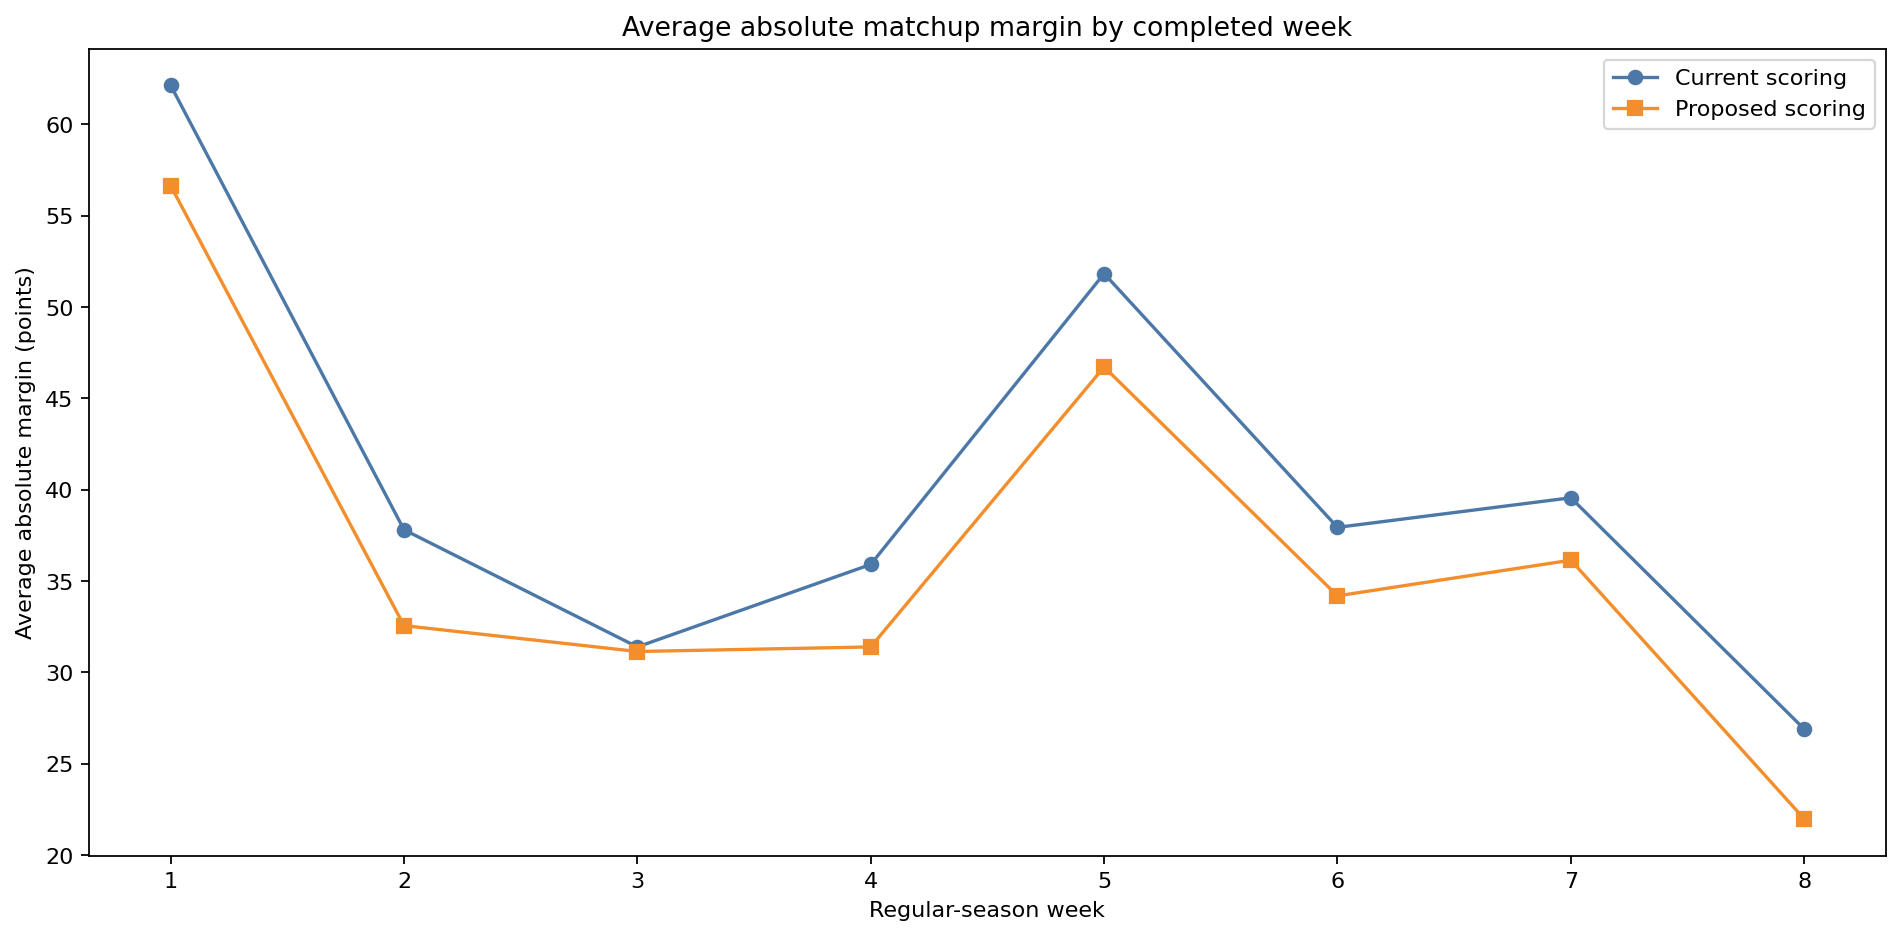

Across the 48 completed matchups, the average difference between opponents falls from 40.43 points under current scoring to 36.34 under proposed scoring. The share of games decided by five points or fewer stays at 6.25% under both formats.

The average margins are smaller, but very close finishes did not become more common in this sample. This is a scoring-only comparison: each historical lineup stays fixed, and the extra FLEX is not included.

#### Historical winner transitions after scoring-only rescoring

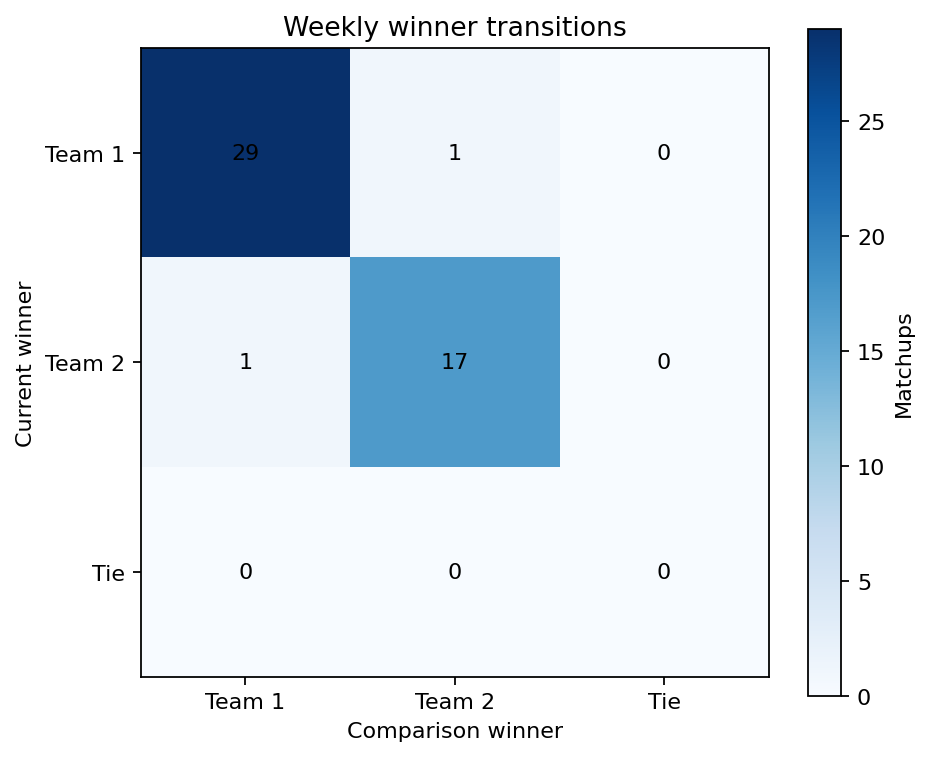

Most matchups kept the same winner. Proposed scoring changed the winner in two of the 48 games across the eight weeks shown. This suggests the scoring change can reduce margins without frequently changing which team wins. It does not include the additional FLEX.

#### Reconstructed team wins under fixed-starter scoring-only rescoring

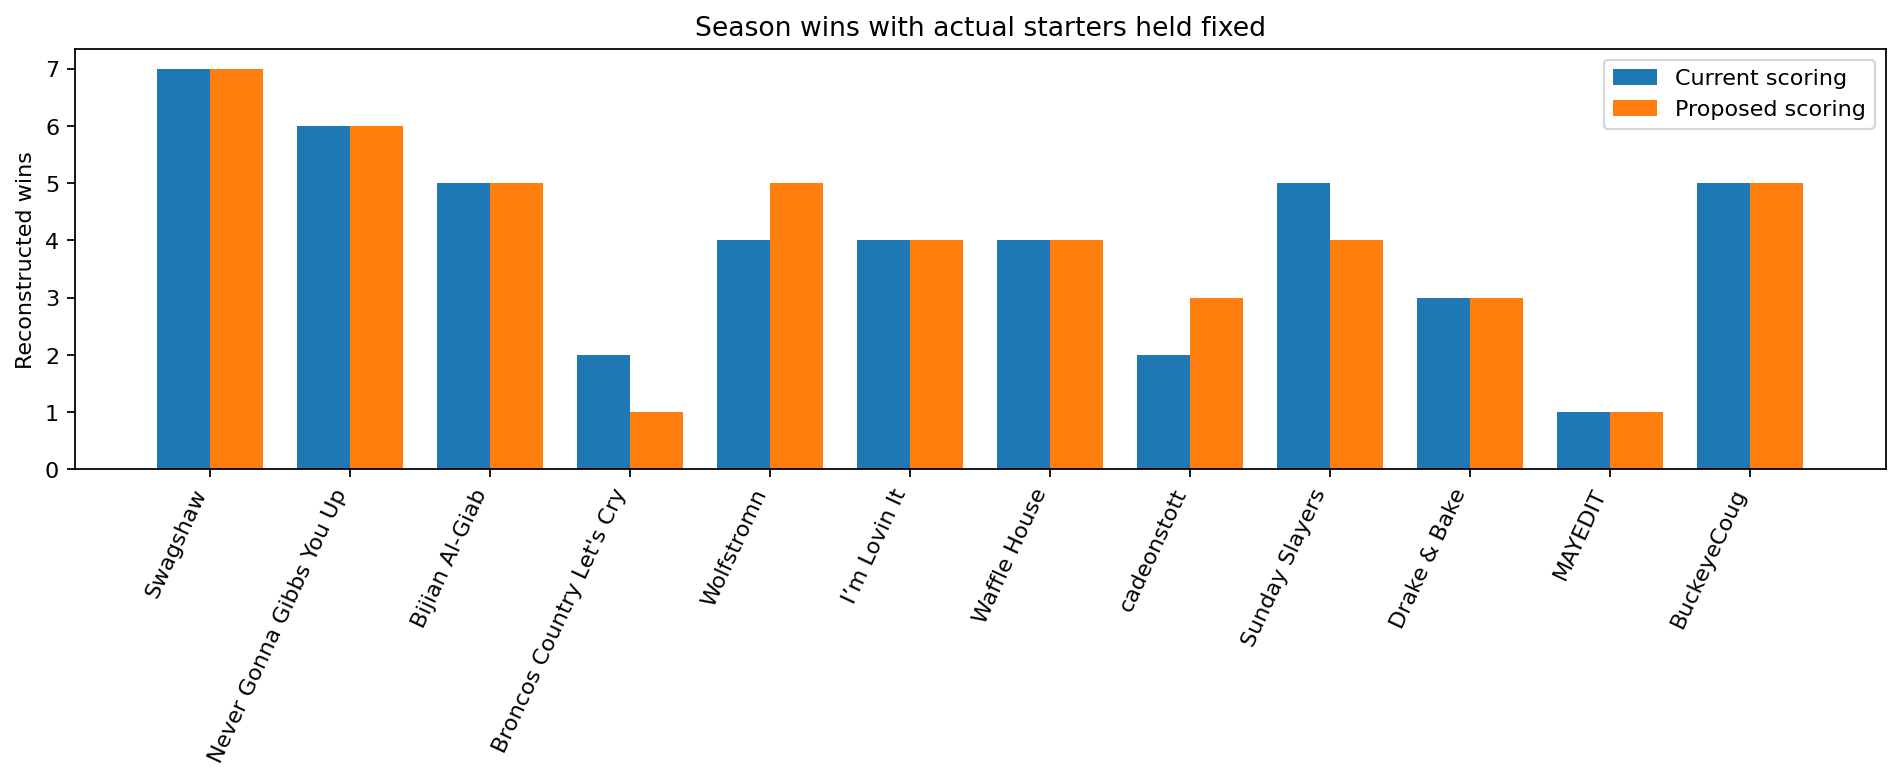

This chart shows each team's reconstructed wins when the same historical starters are scored under the proposed reception values. Four of the 12 teams change their record by one win; the other eight keep the same win total.

These results use the actual historical starters and change scoring only. They do not include the extra FLEX, and they describe this eight-week sample rather than predict the rest of the season.

In [8]:
weekly_summary = read_report("weekly_competitiveness_summary.csv")
weekly_display_columns = [
    "Scoring format",
    "Average absolute matchup margin",
    "Outcome flips versus current scoring",
    "Matchup rate within 5 points (%)",
]
display(weekly_summary[weekly_display_columns].round(2))
show_figure(
    "weekly_matchup_margins_by_week.png",
    "Average absolute historical matchup margin by week (fixed actual starters)",
)

display(Markdown("""Across the 48 completed matchups, the average difference between opponents falls from 40.43 points under current scoring to 36.34 under proposed scoring. The share of games decided by five points or fewer stays at 6.25% under both formats.

The average margins are smaller, but very close finishes did not become more common in this sample. This is a scoring-only comparison: each historical lineup stays fixed, and the extra FLEX is not included."""))
show_figure(
    "weekly_winner_transition_matrix.png",
    "Historical winner transitions after scoring-only rescoring",
)

display(Markdown("""Most matchups kept the same winner. Proposed scoring changed the winner in two of the 48 games across the eight weeks shown. This suggests the scoring change can reduce margins without frequently changing which team wins. It does not include the additional FLEX."""))
show_figure(
    "season_team_wins_comparison.png",
    "Reconstructed team wins under fixed-starter scoring-only rescoring",
)

display(Markdown("""This chart shows each team's reconstructed wins when the same historical starters are scored under the proposed reception values. Four of the 12 teams change their record by one win; the other eight keep the same win total.

These results use the actual historical starters and change scoring only. They do not include the extra FLEX, and they describe this eight-week sample rather than predict the rest of the season."""))

## 4 - Limitations and conclusion

This analysis uses season-to-date player production and one snapshot of current team rosters. It does not reconstruct each team's historical roster or account for every trade, injury, or roster change through the season.

The best-lineup comparisons show what each team could have started using production recorded so far. They are not predictions or the lineups managers actually submitted. Historical matchup comparisons keep the original starters fixed and change scoring only; they do not include the additional FLEX.

More available starting choices do not automatically make every team more competitive. The results show how the proposed rules affect player values, roster flexibility, and the choices available to each manager.

### Conclusion

The proposed changes affect both how positions compare and how managers can build a starting lineup. The scoring analysis shows the largest drop in tight-end representation: eight fewer TEs in the Top 75 and seven fewer in the Top 100. Quarterbacks and kickers gain the most representation, while RB and WR counts change less.

That shift matters when managers assess their rosters. Teams that rely on TE production may need to reconsider that value, while the reception bonus makes catches less important for RBs and WRs. It does not mean kickers have become better players; it means their scores compare more favorably under the new values.

Replacing a required WR with an extra FLEX does not improve every team's best possible lineup. It does let managers choose a stronger mix of RBs, WRs, and TEs. Five teams show a better lineup under current scoring with the extra FLEX, while seven show no change. The number of close alternatives also varies by team, so the proposal does not benefit every roster in the same way.

In the historical scoring-only comparison, average absolute matchup margins fall from 40.43 to 36.34 points, but the rate of games decided by five points or fewer stays at 6.25%. Two of 48 matchup winners change. This suggests smaller average margins in this sample without frequent changes to winners.

The strongest case for the additional FLEX is the added freedom to use a team's best available combination of RBs, WRs, and TEs rather than requiring a third WR. It may help managers make better use of their roster depth, but it does not guarantee equal benefits or make the league more competitive by itself.

### My Takeaway

*Add your own interpretation and recommendation here.*

- Does the combined proposal create more useful starting choices across the league?
- Which teams gain or lose, and which positional depth explains those changes?
- Does the extra FLEX let managers use their strongest available RB, WR, and TE combination?
- What tradeoffs should the league consider?

## Technical Appendix

Detailed CSV reports remain in `outputs/`. The figures and data below are secondary to the main story but retained for audit and further exploration.

In [9]:
appendix_reports = [
    ("scoring_audit.csv", "Complete scoring-category audit"),
    ("roster_data_quality.csv", "Roster snapshot and data-quality summary"),
    ("weekly_data_coverage.csv", "Historical weekly data coverage"),
    ("team_roster_depth.csv", "Team-by-position depth metrics"),
    ("team_lineup_scenarios.csv", "All team and scenario lineup summaries"),
    ("team_lineup_impact.csv", "Team-level scenario effects"),
    ("team_viable_options.csv", "Viable-option tolerance sensitivity"),
    ("team_flex_candidates.csv", "FLEX candidate depth"),
]
for filename, title in appendix_reports:
    report = read_report(filename)
    display(Markdown(f"### {title} - `{filename}` ({len(report)} rows)"))
    display(report.head(30))

ownership_audit = read_report("roster_ownership_audit.csv")
ownership_issues = ownership_audit.loc[
    ~ownership_audit["Status"].eq("mapped_to_one_team")
]
display(Markdown("### Roster ownership exceptions"))
display(ownership_issues if not ownership_issues.empty else Markdown("No ownership exceptions were reported."))

match_report = read_report("player_match_report.csv")
match_summary = match_report.groupby(["record_type", "status"], dropna=False).size().rename("Records").reset_index()
display(Markdown("### Player-directory and statistics matching summary"))
display(match_summary)

### Complete scoring-category audit - `scoring_audit.csv` (44 rows)

,setting,points_per_stat,source_stat,status,assumptions
0,blk_kick,2.00,blk_kick,applied,NaN
1,bonus_rec_te,1.00,bonus_rec_te (TE reception count; rec fallback),applied,NaN
2,def_st_ff,1.00,def_st_ff,applied,NaN
3,def_st_fum_rec,1.00,def_st_fum_rec,applied,NaN
4,def_st_td,6.00,def_st_td,applied,NaN
5,def_td,6.00,def_td,applied,NaN
6,ff,1.00,ff,applied,NaN
7,fgm_0_19,3.00,fgm_0_19,applied,NaN
8,fgm_20_29,3.00,fgm_20_29,applied,NaN
9,fgm_30_39,3.00,fgm_30_39,applied,NaN


### Roster snapshot and data-quality summary - `roster_data_quality.csv` (7 rows)

,Metric,Value
0,Team count,12
1,Unique rostered player IDs,317
2,Players mapped to exactly one team,317
3,Conflicting ownership player IDs,0
4,Rostered IDs missing from the player directory,0
5,Current roster snapshot retrieved at (UTC),2026-11-05T00:13:44.711513+00:00
6,Historical roster snapshots available by week,"1, 2, 3, 4, 5, 6, 7, 8"


### Historical weekly data coverage - `weekly_data_coverage.csv` (9 rows)

,Week,Stats records,Matchup team records,Starter records,Starters without stat records,Starters missing directory mapping,Maximum current-score reconciliation error,Included,Reason
0,1,2331,12,132,1,0,0.0,True,"Historical starters, roster snapshots, and cur..."
1,2,2352,12,132,6,0,0.0,True,"Historical starters, roster snapshots, and cur..."
2,3,2357,12,132,1,0,0.0,True,"Historical starters, roster snapshots, and cur..."
3,4,2386,12,132,0,0,0.0,True,"Historical starters, roster snapshots, and cur..."
4,5,2241,12,132,4,0,0.0,True,"Historical starters, roster snapshots, and cur..."
5,6,2103,12,132,6,0,0.0,True,"Historical starters, roster snapshots, and cur..."
6,7,2095,12,131,3,0,0.0,True,"Historical starters, roster snapshots, and cur..."
7,8,2080,12,131,1,0,0.0,True,"Historical starters, roster snapshots, and cur..."
8,9,0,0,0,0,0,NaN,False,Excluded current NFL state week; only complete...


... (10 outputs left out)

### Roster ownership exceptions

No ownership exceptions were reported.

### Player-directory and statistics matching summary

,record_type,status,Records
0,eligible_player,matched_no_stats,2350
1,eligible_player,matched_with_stats,882
2,eligible_player,no_stats_record,25
3,unmatched_stats_id,not found in Sleeper player directory,32


In [10]:
MAIN_FIGURES = {
    "story_reception_points_by_position.png",
    "positional_composition_side_by_side.png",
    "positional_count_changes.png",
    "story_starter_replacement_gaps.png",
    "team_roster_depth_top2_ppg.png",
    "team_roster_depth_player_counts.png",
    "team_best_lineup_four_scenarios.png",
    "team_lineup_change_components.png",
    "team_viable_options_sensitivity.png",
    "team_starter_bench_cutoff_gap.png",
    "team_flex_candidate_depth.png",
    "weekly_matchup_margins_by_week.png",
    "weekly_winner_transition_matrix.png",
    "season_team_wins_comparison.png",
}

### Player-level games played and per-game sample - first 48 rostered players

,sleeper_id,full_name,position,Team,games_played,games_played_source_available,has_season_stats_record,current_season_points,current_points_per_game,comparison_season_points,comparison_points_per_game
0,11533,Brandon Aubrey,K,Sunday Slayers,8.0,True,True,72.00,9.000000,72.00,9.000000
1,9487,Parker Washington,WR,Never Gonna Gibbs You Up,7.0,True,True,95.50,13.642857,82.00,11.714286
2,6786,CeeDee Lamb,WR,Waffle House,8.0,True,True,168.30,21.037500,138.30,17.287500
3,11584,Bucky Irving,RB,Waffle House,8.0,True,True,130.60,16.325000,121.60,15.200000
4,9504,Kayshon Boutte,WR,cadeonstott,7.0,True,True,34.40,4.914286,26.90,3.842857
5,12507,Omarion Hampton,RB,Drake & Bake,7.0,True,True,62.20,8.885714,56.70,8.100000
6,13302,Adam Randall,RB,cadeonstott,8.0,True,True,0.00,0.000000,0.00,0.000000
7,12493,Oronde Gadsden,TE,Bijian Al-Giab,7.0,True,True,55.70,7.957143,38.70,5.528571
8,7553,Kyle Pitts Sr.,TE,MAYEDIT,8.0,True,True,87.70,10.962500,65.70,8.212500
9,11579,Audric Estime,RB,Sunday Slayers,5.0,True,True,7.90,1.580000,7.90,1.580000


### Selected player IDs, slot assignments, and per-game scores - first 48 rows

,Roster ID,Team,Scenario,Scenario label,Slot,Slot type,Sleeper player ID,Player,Position,Points per game,Selected season-to-date points,Filled
0,1,Swagshaw,A,Current baseline,QB 1,QB,11560,Caleb Williams,QB,19.516000,97.58,True
1,1,Swagshaw,A,Current baseline,RB 1,RB,6790,D'Andre Swift,RB,18.837500,150.70,True
2,1,Swagshaw,A,Current baseline,RB 2,RB,7594,Chuba Hubbard,RB,19.000000,133.00,True
3,1,Swagshaw,A,Current baseline,WR 1,WR,8146,Garrett Wilson,WR,14.212500,113.70,True
4,1,Swagshaw,A,Current baseline,WR 2,WR,8167,Christian Watson,WR,18.350000,146.80,True
5,1,Swagshaw,A,Current baseline,WR 3,WR,9493,Puka Nacua,WR,23.100000,138.60,True
6,1,Swagshaw,A,Current baseline,TE 1,TE,8130,Trey McBride,TE,27.050000,216.40,True
7,1,Swagshaw,A,Current baseline,FLEX 1,FLEX,8131,Isaiah Likely,TE,21.928571,153.50,True
8,1,Swagshaw,A,Current baseline,SUPER_FLEX 1,SUPER_FLEX,8150,Kyren Williams,RB,18.750000,150.00,True
9,1,Swagshaw,A,Current baseline,K 1,K,11792,Will Reichard,K,12.285714,86.00,True


### Competitiveness Evidence Panels

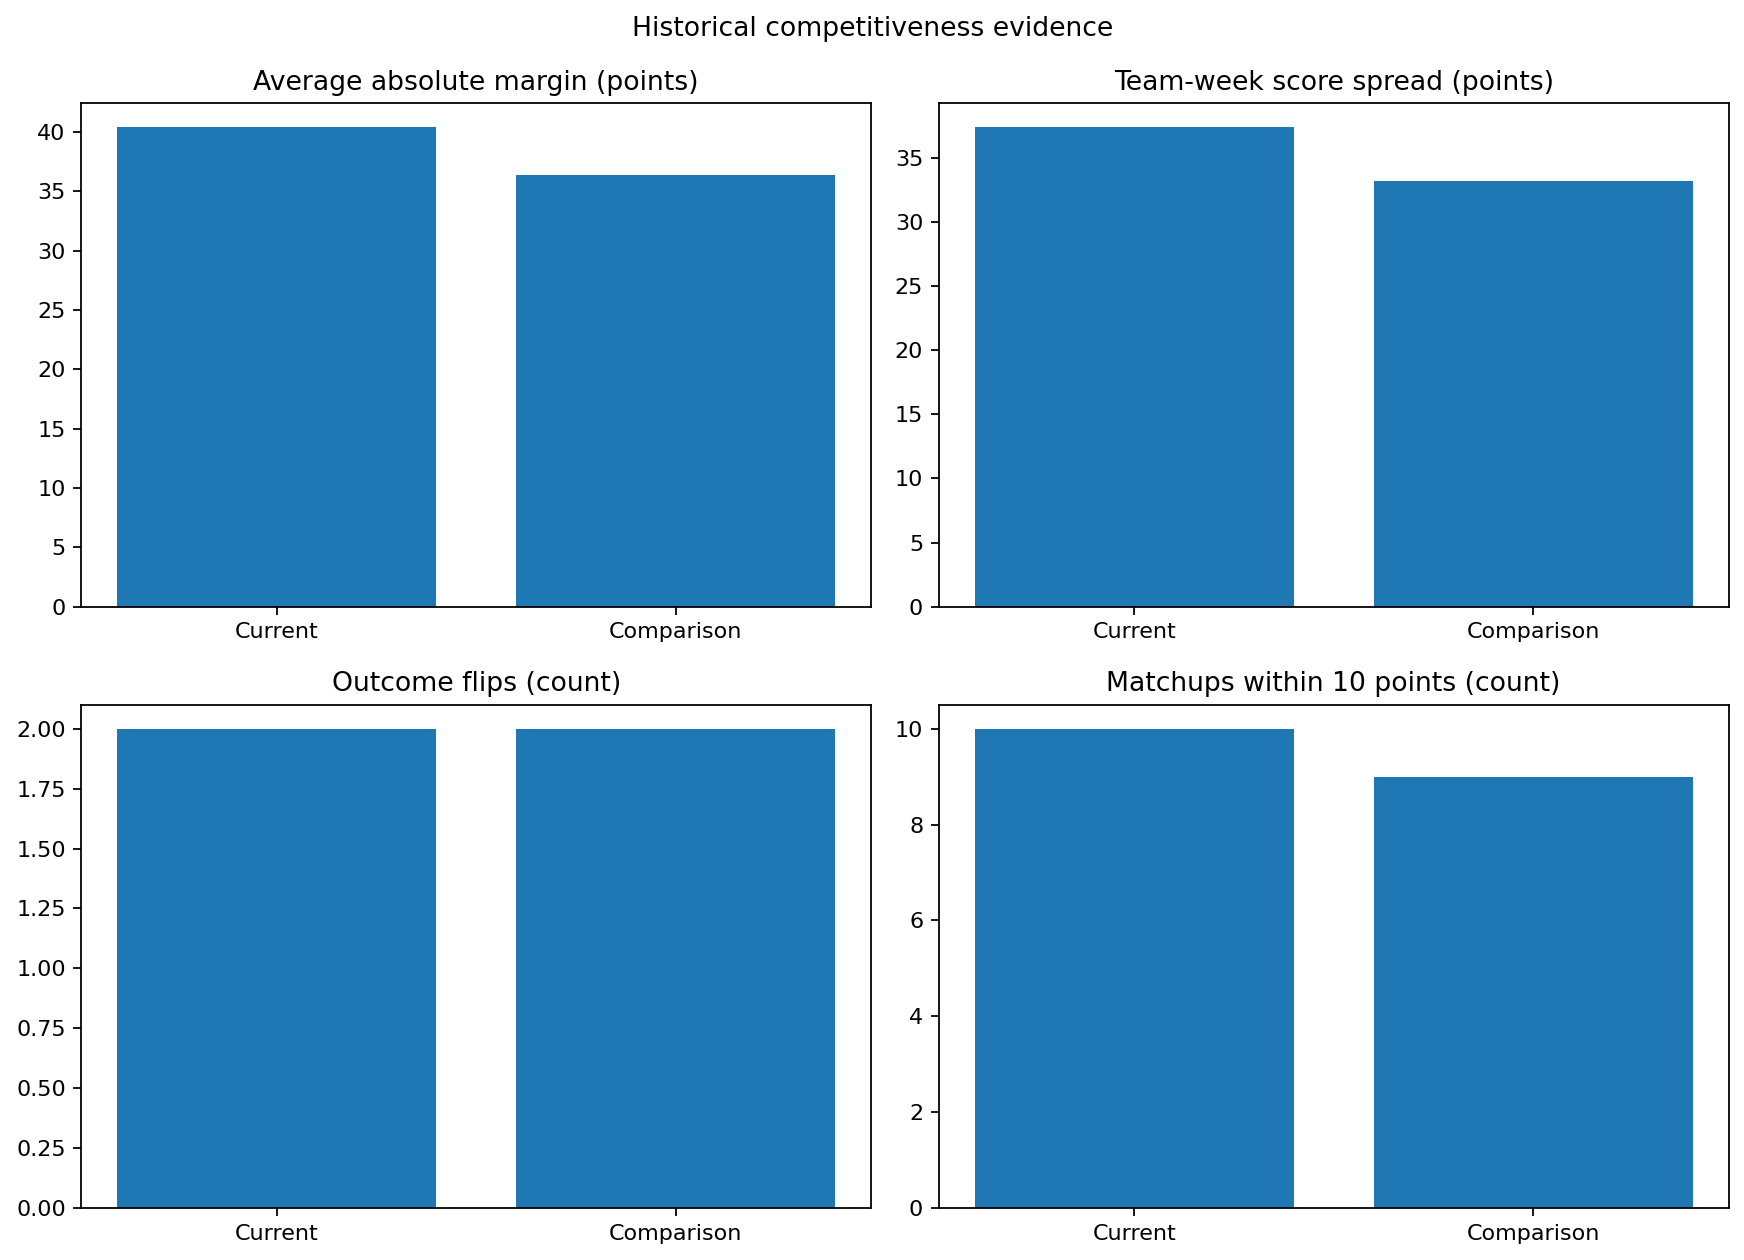

### Positional Composition

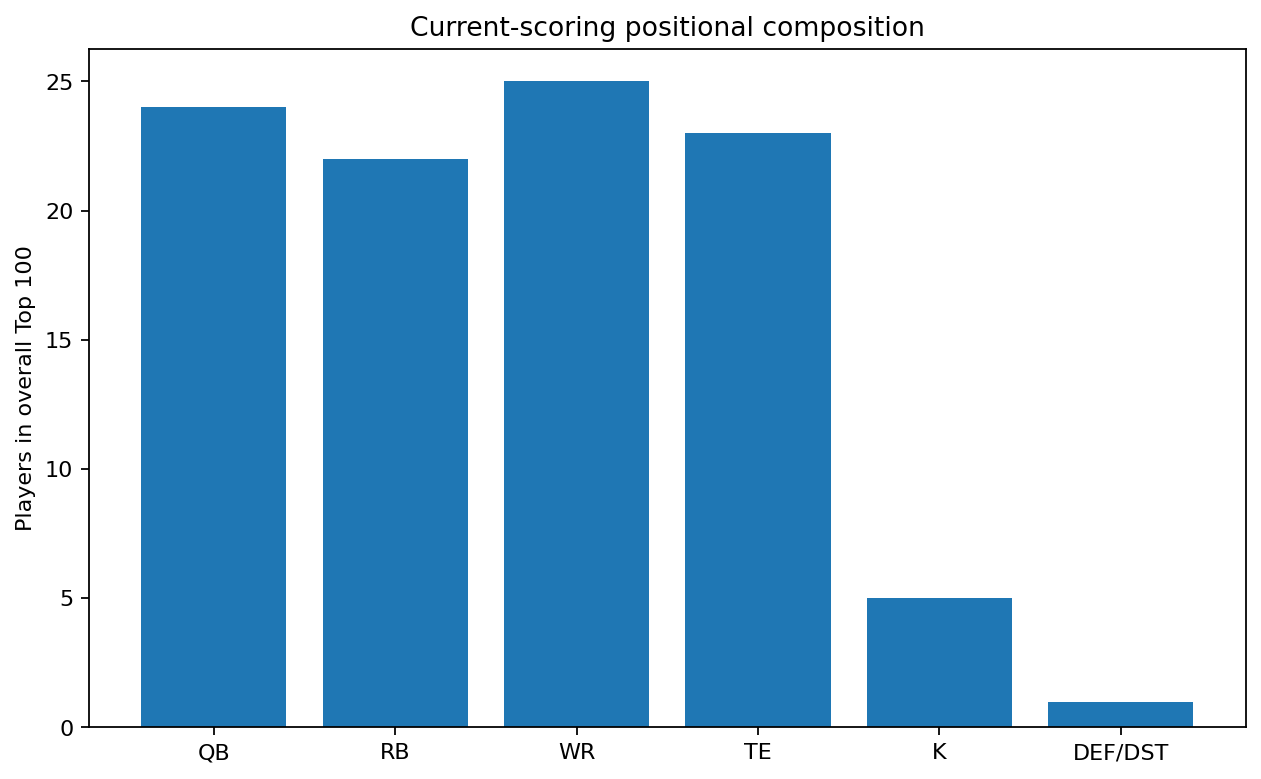

### Positional Composition Current

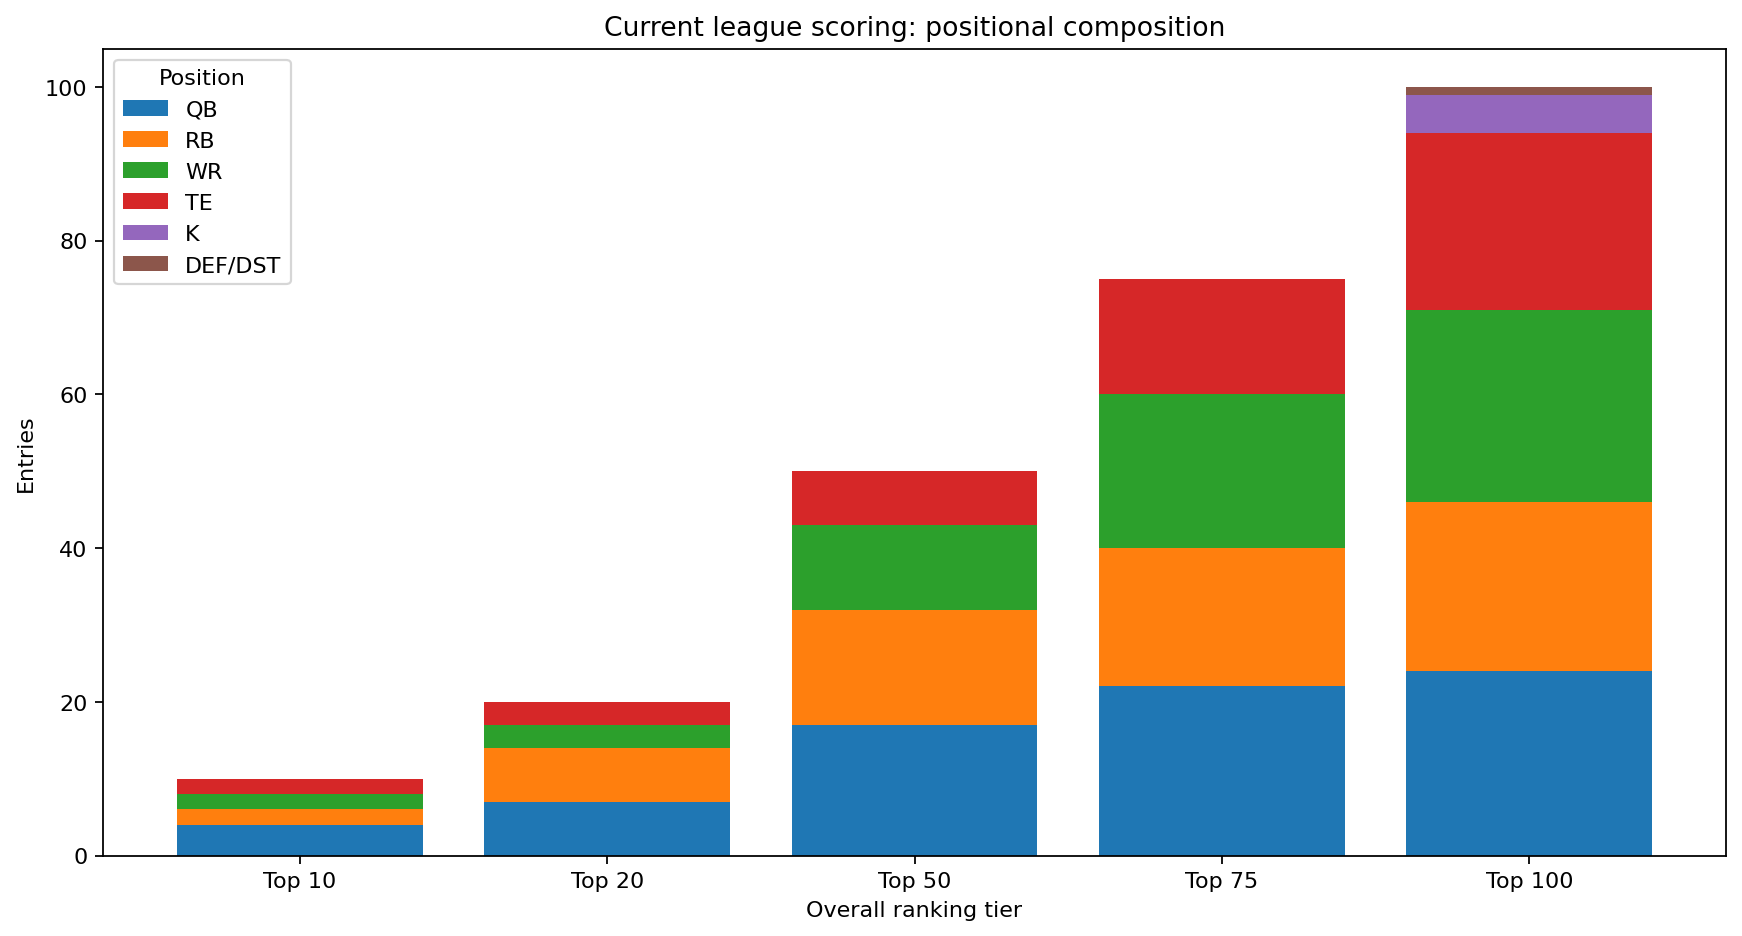

### Positional Composition Half Ppr Te

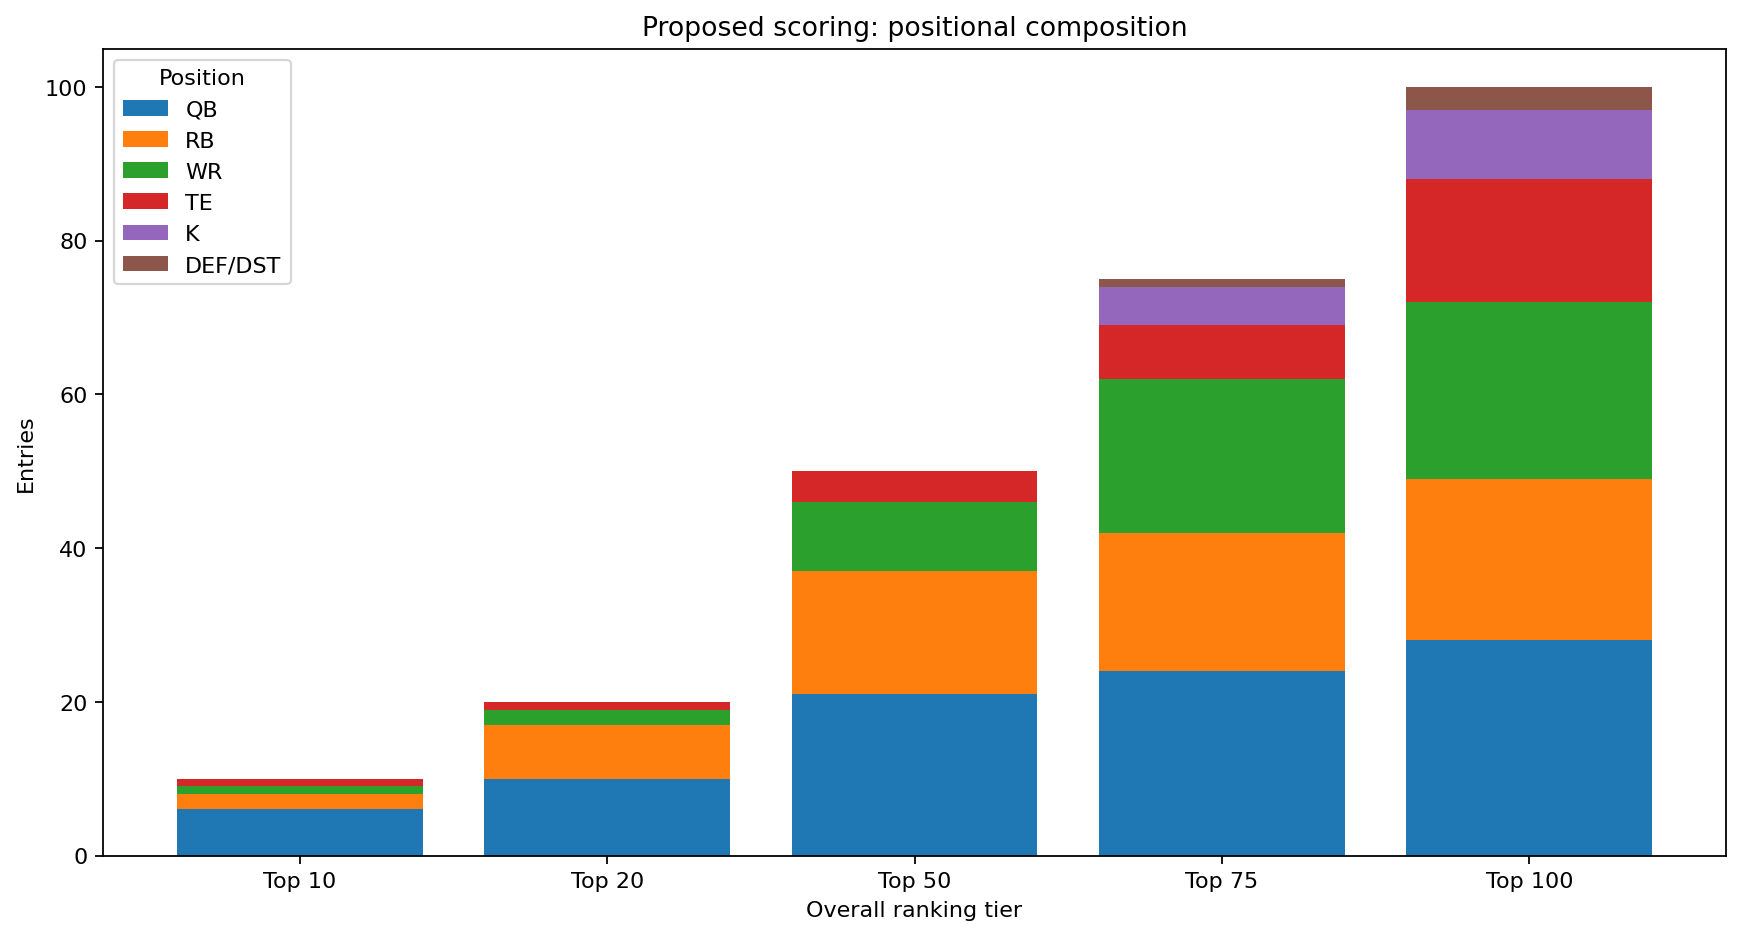

### Positional Percentage Distribution

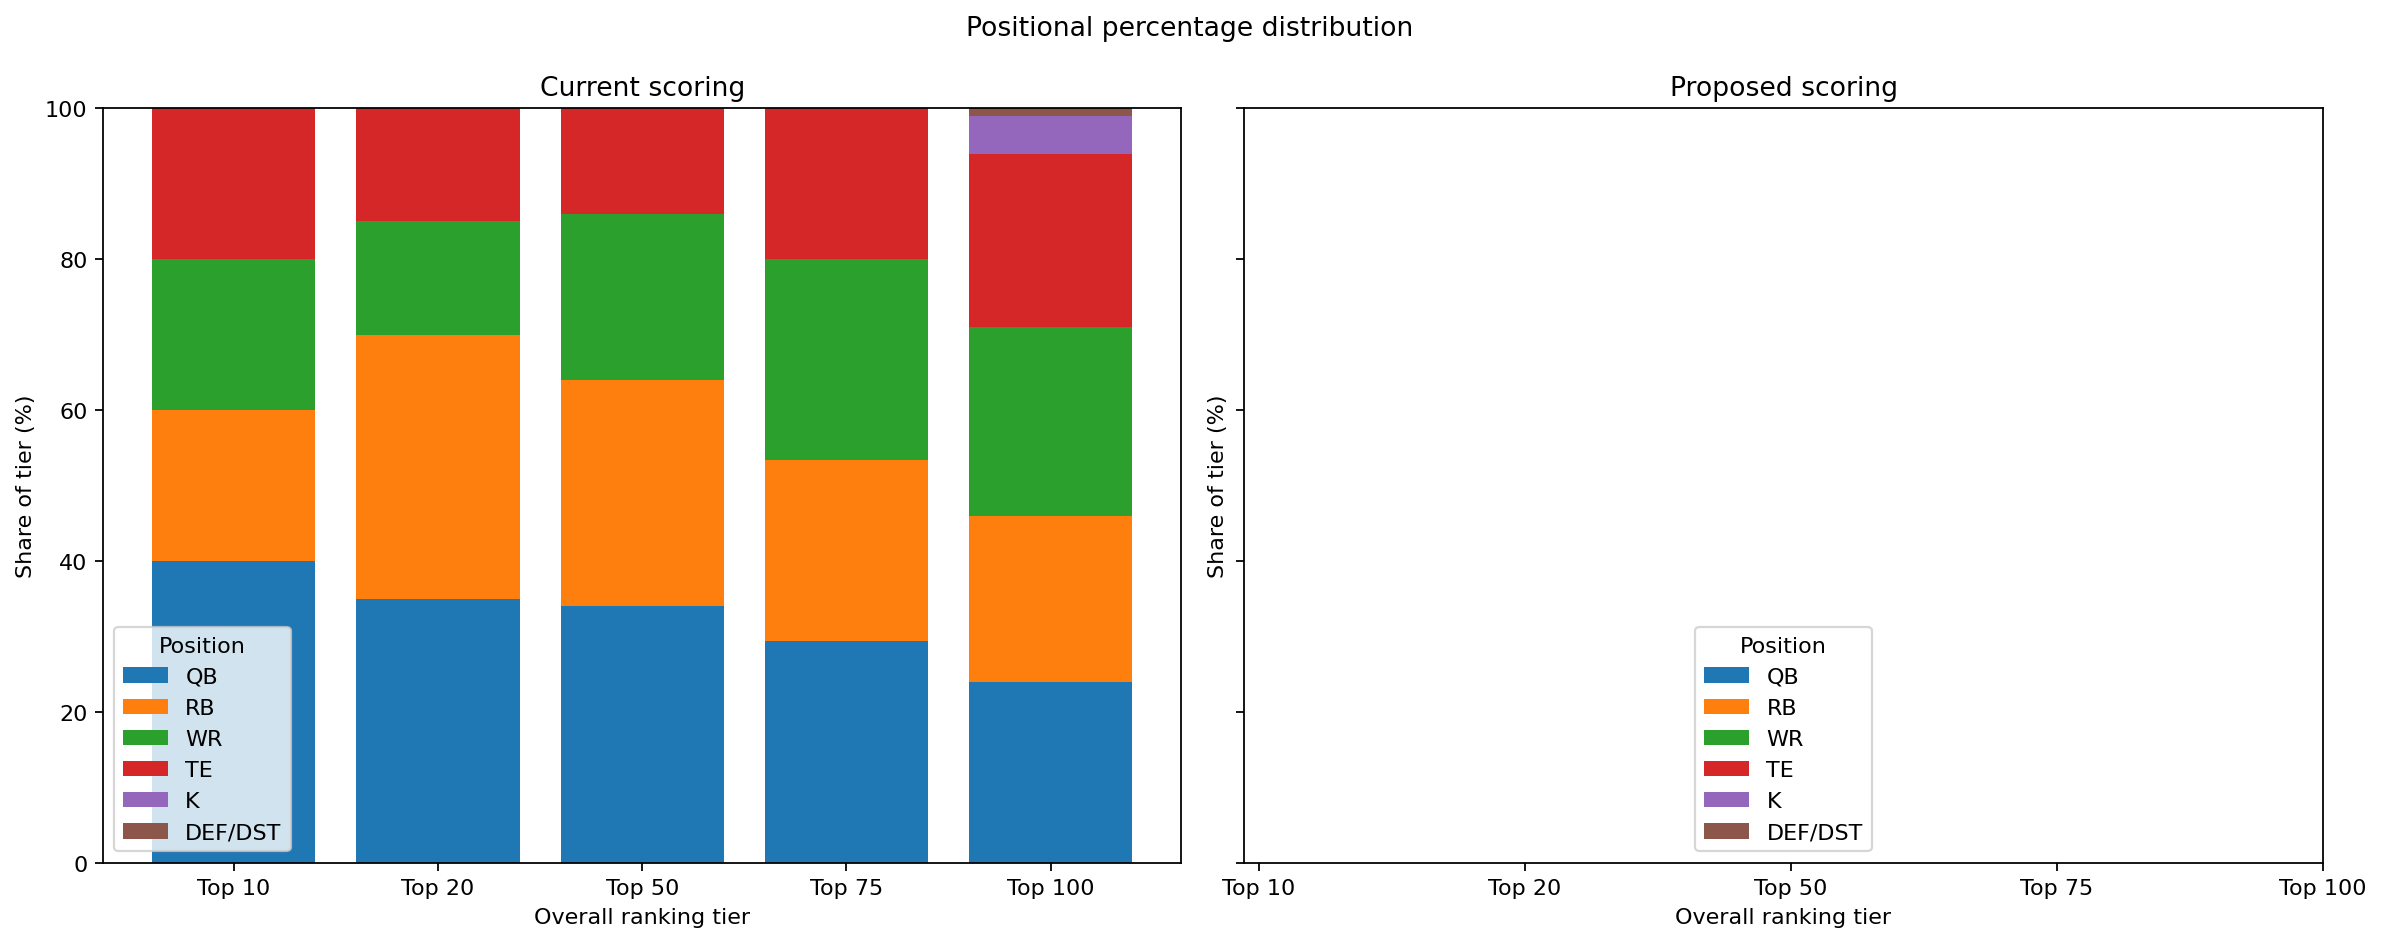

### Season Head To Head Vs All Play

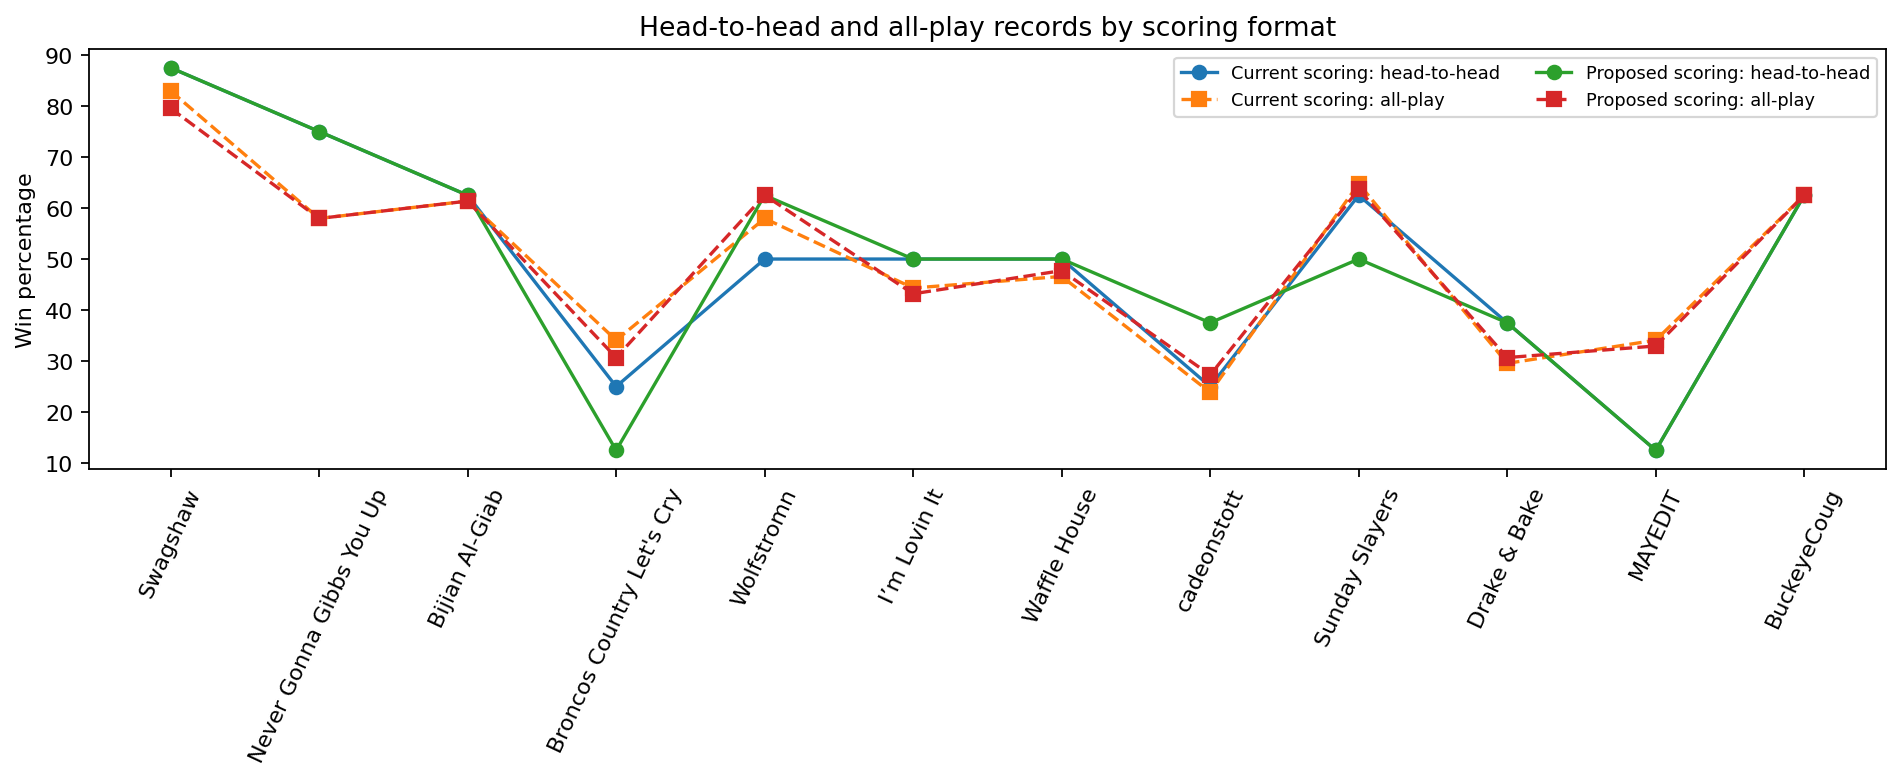

### Season Points For Rank Comparison

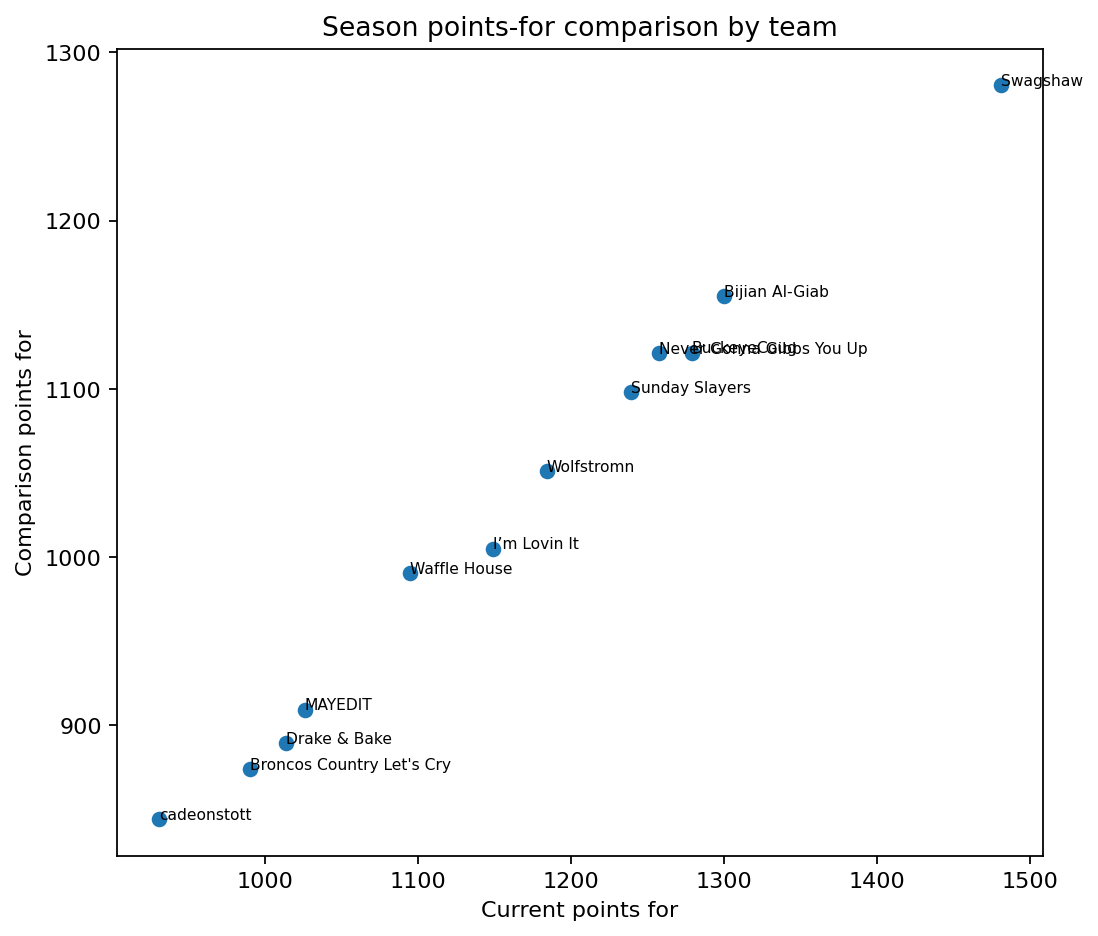

### Story Positional Rank Curves

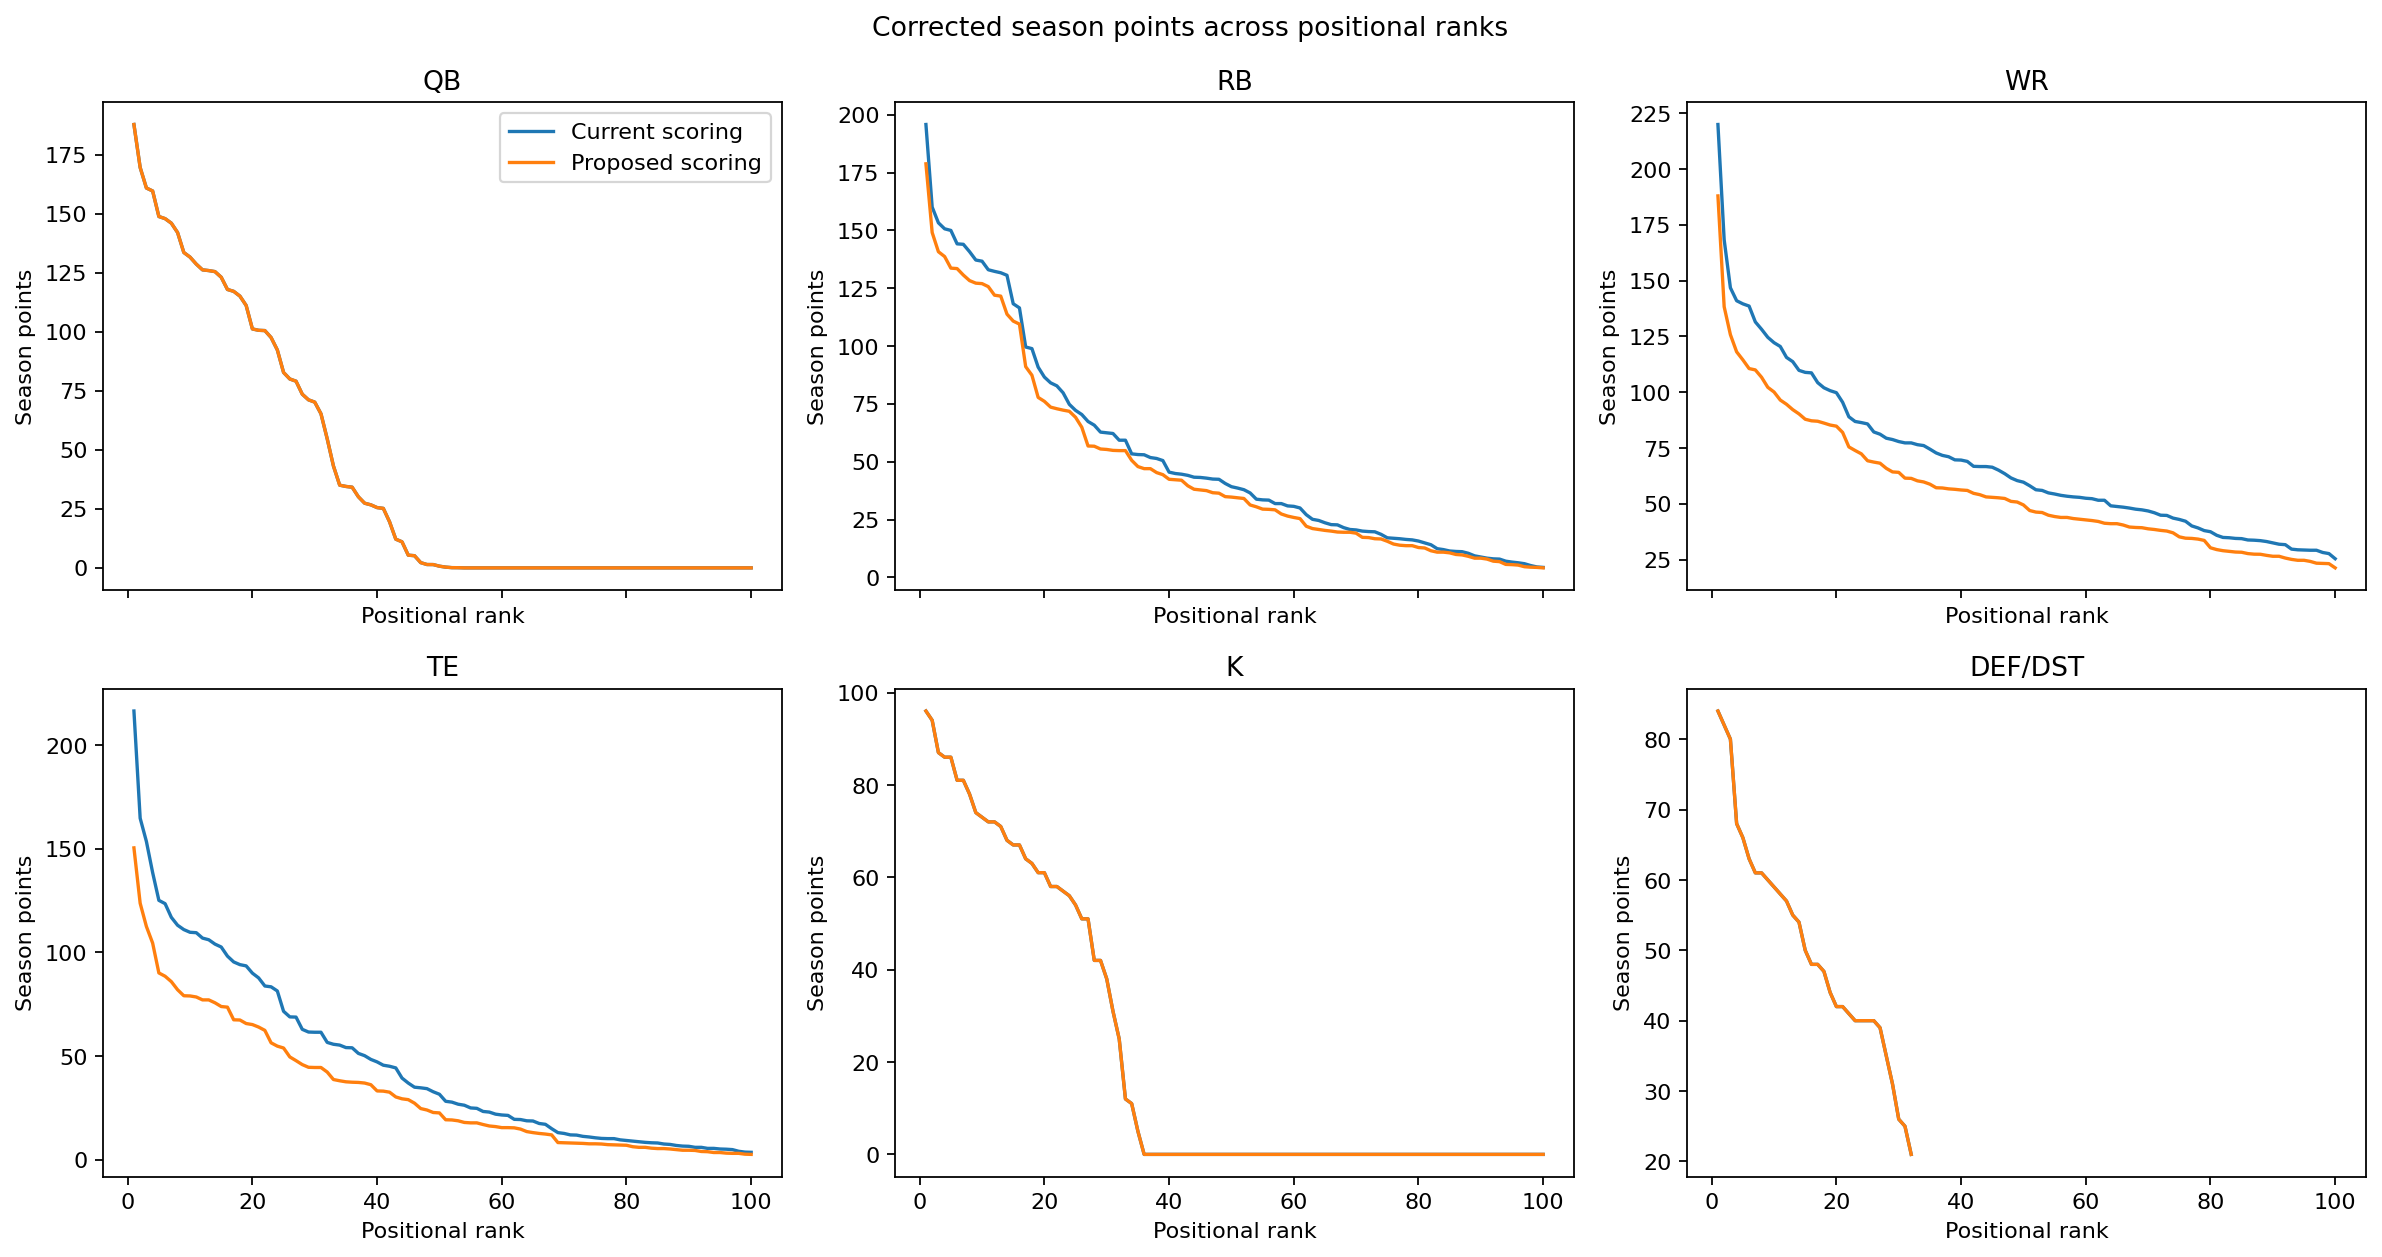

### Team Positional Production

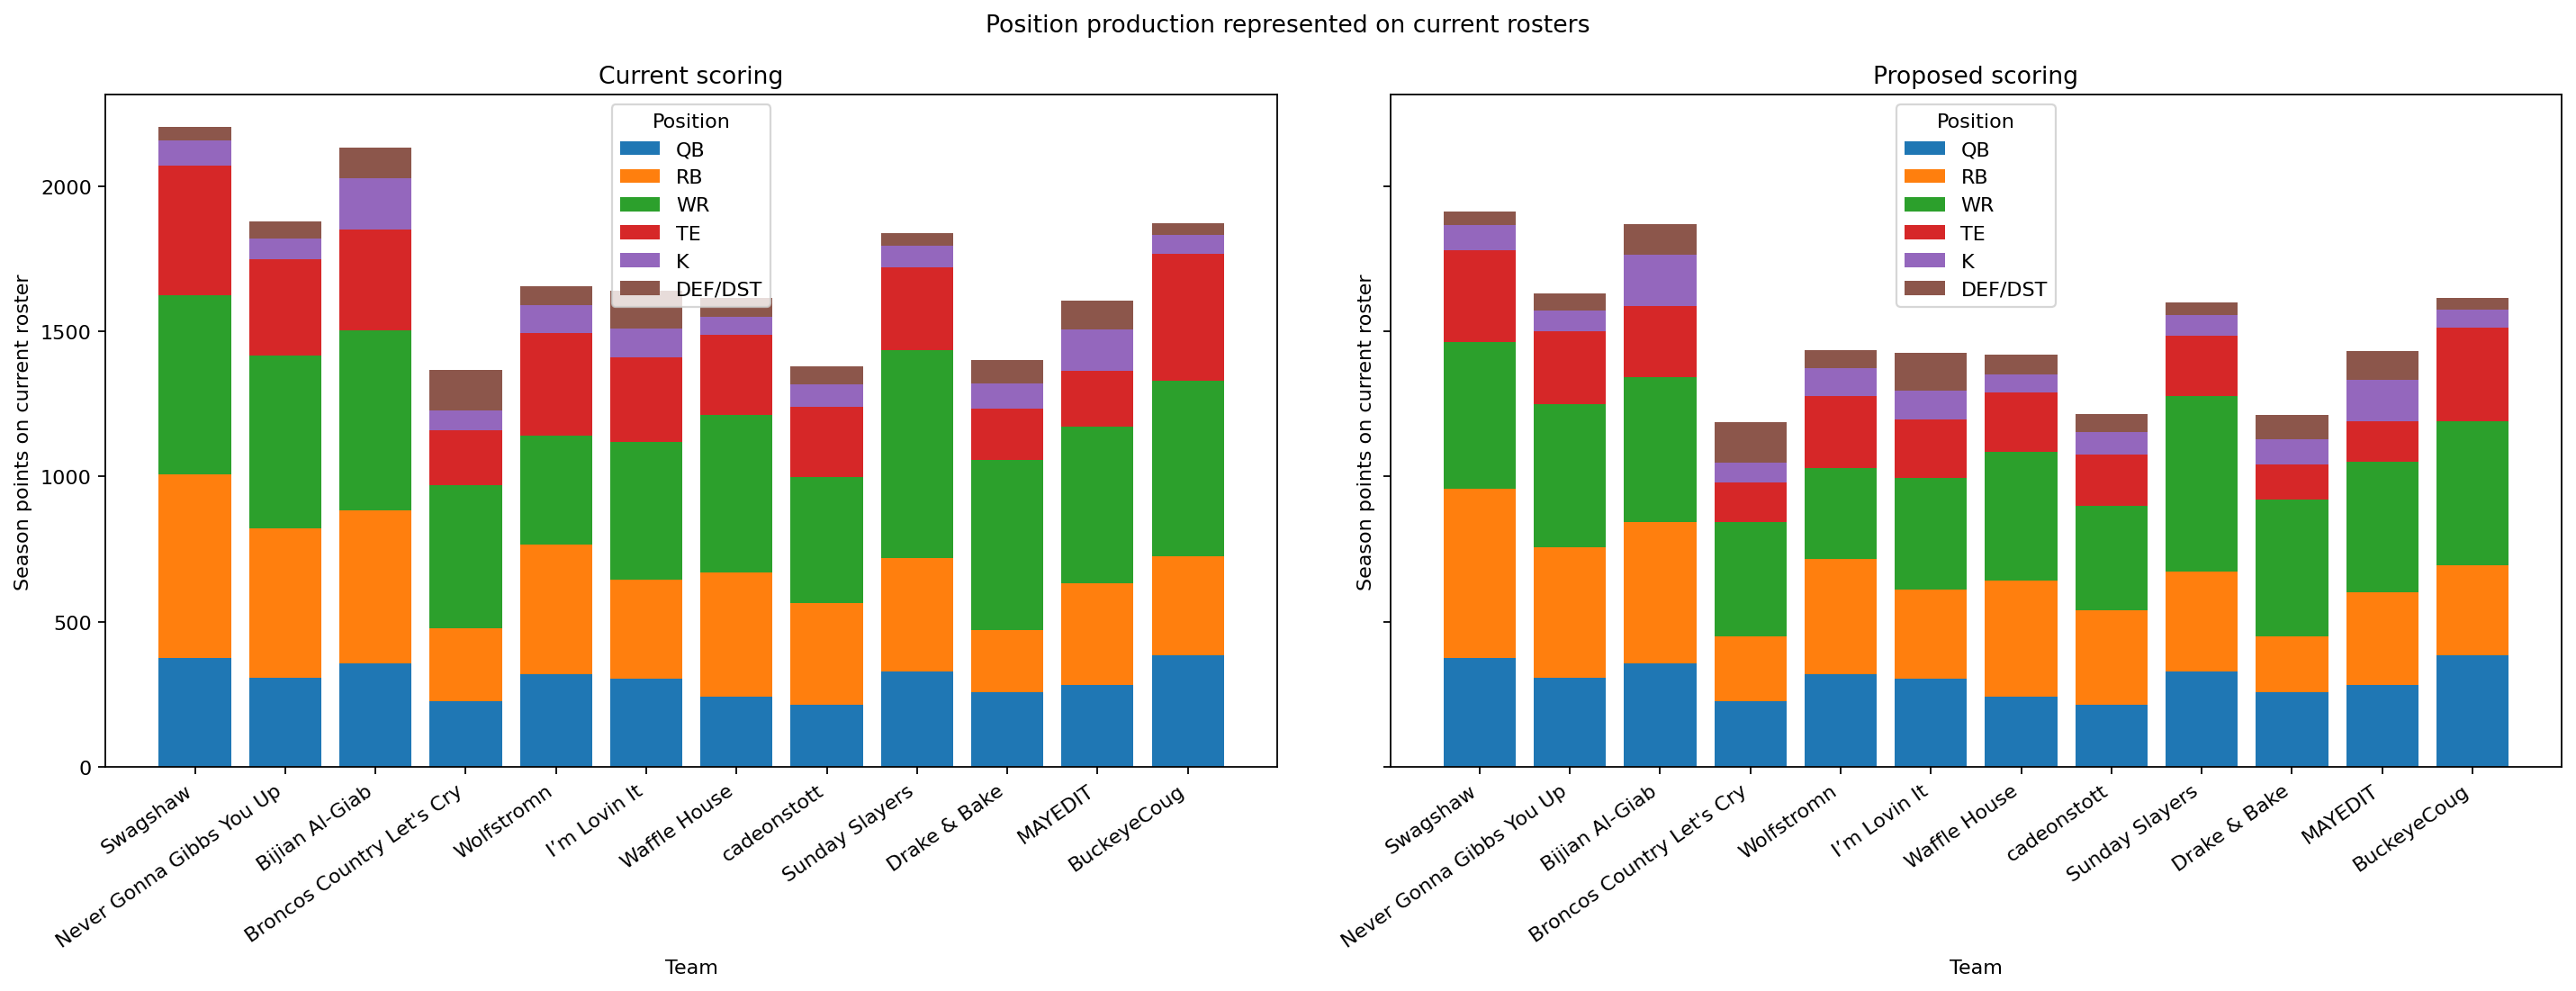

### Team Top End Vs Depth

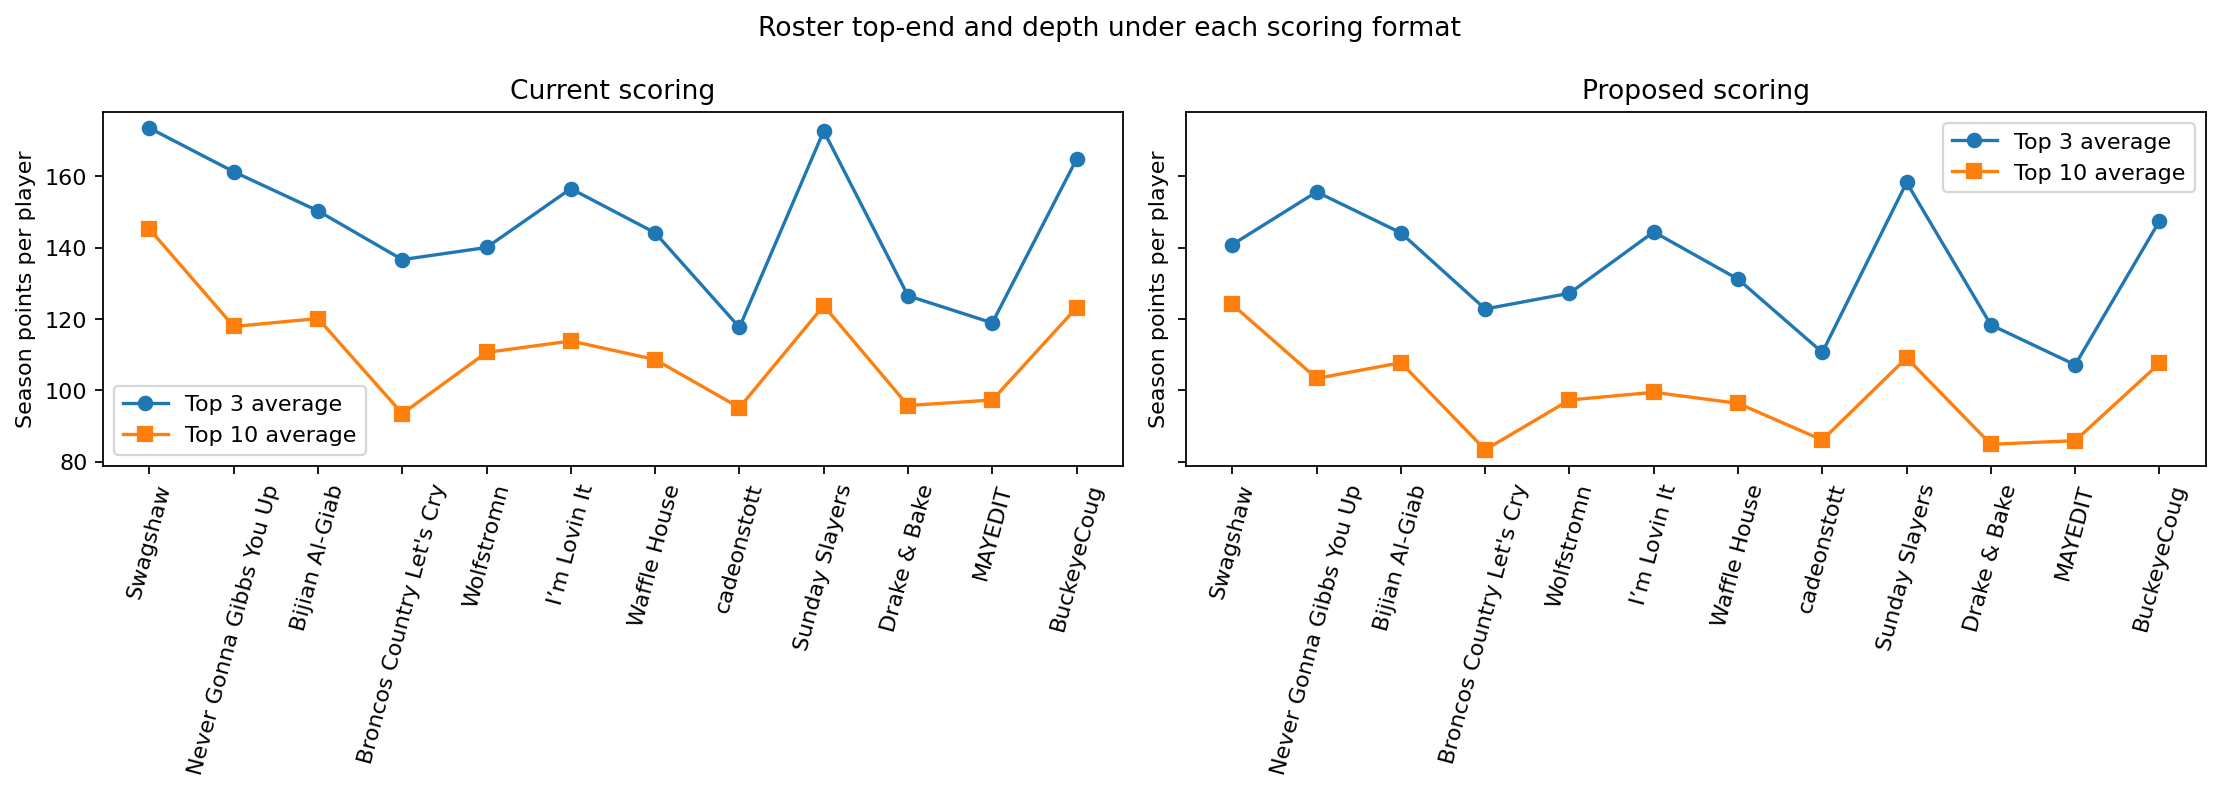

### Top100 Players By Team Comparison

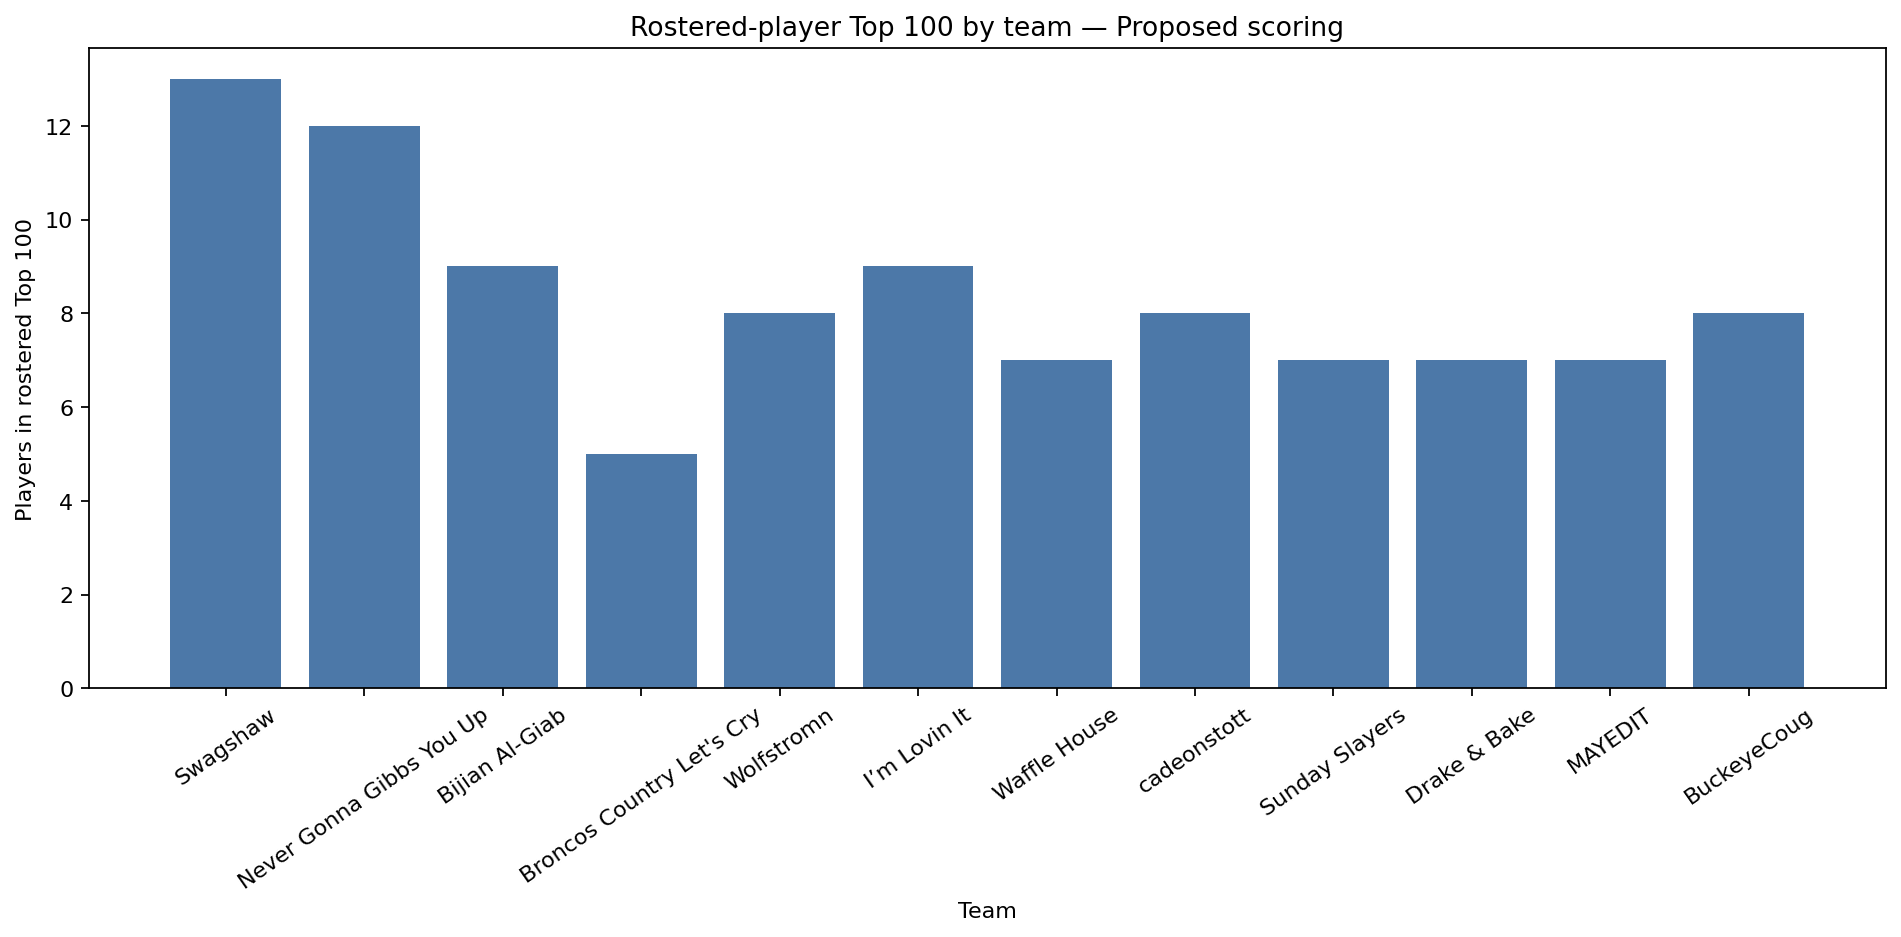

### Top100 Players By Team Current

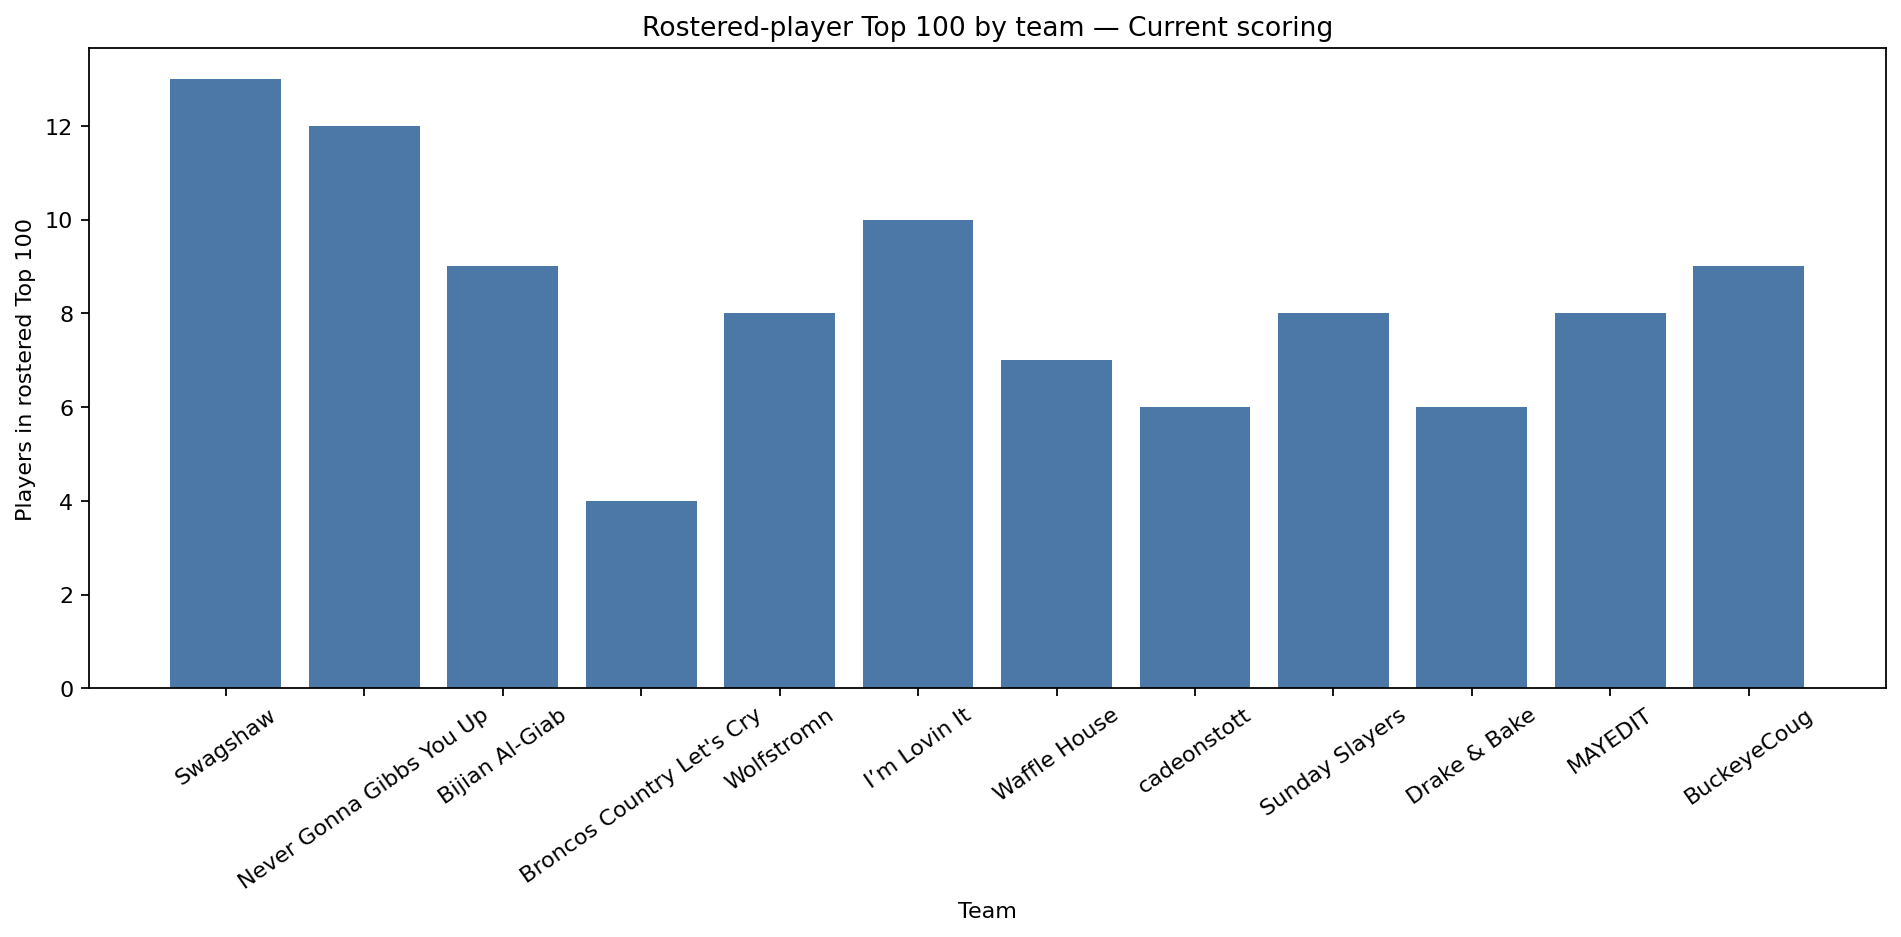

### Top100 Team Count Changes

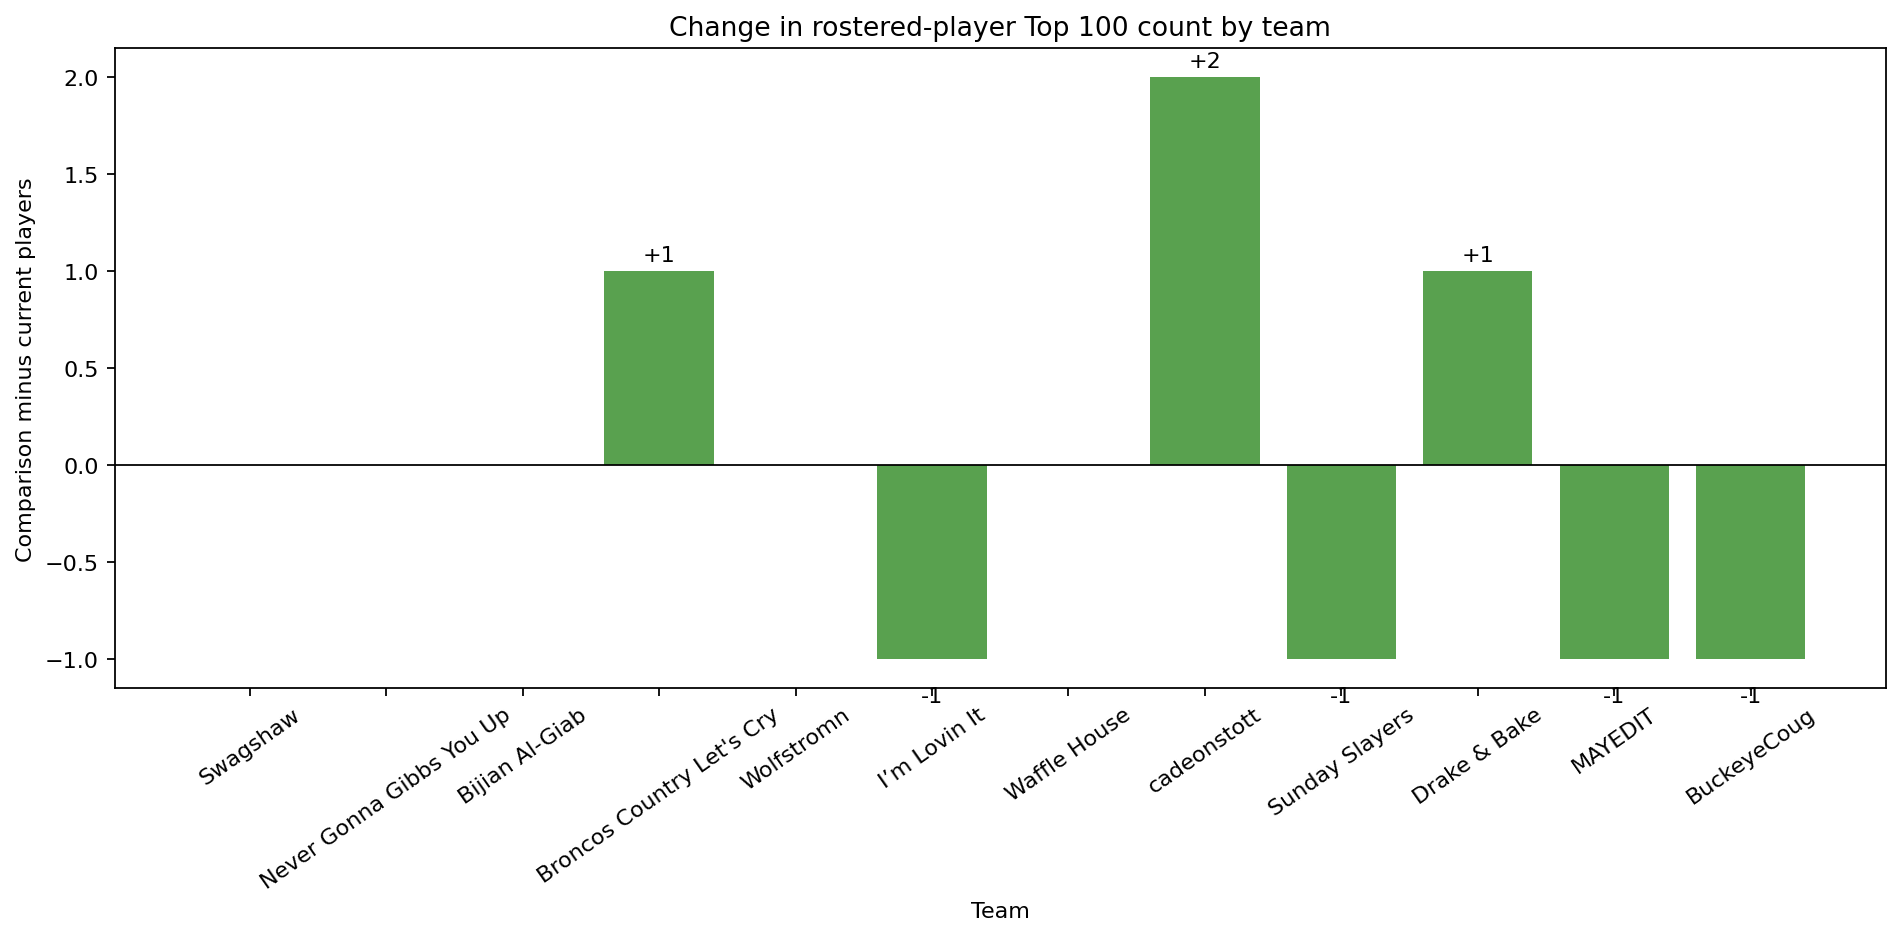

### Top100 Team Position Composition

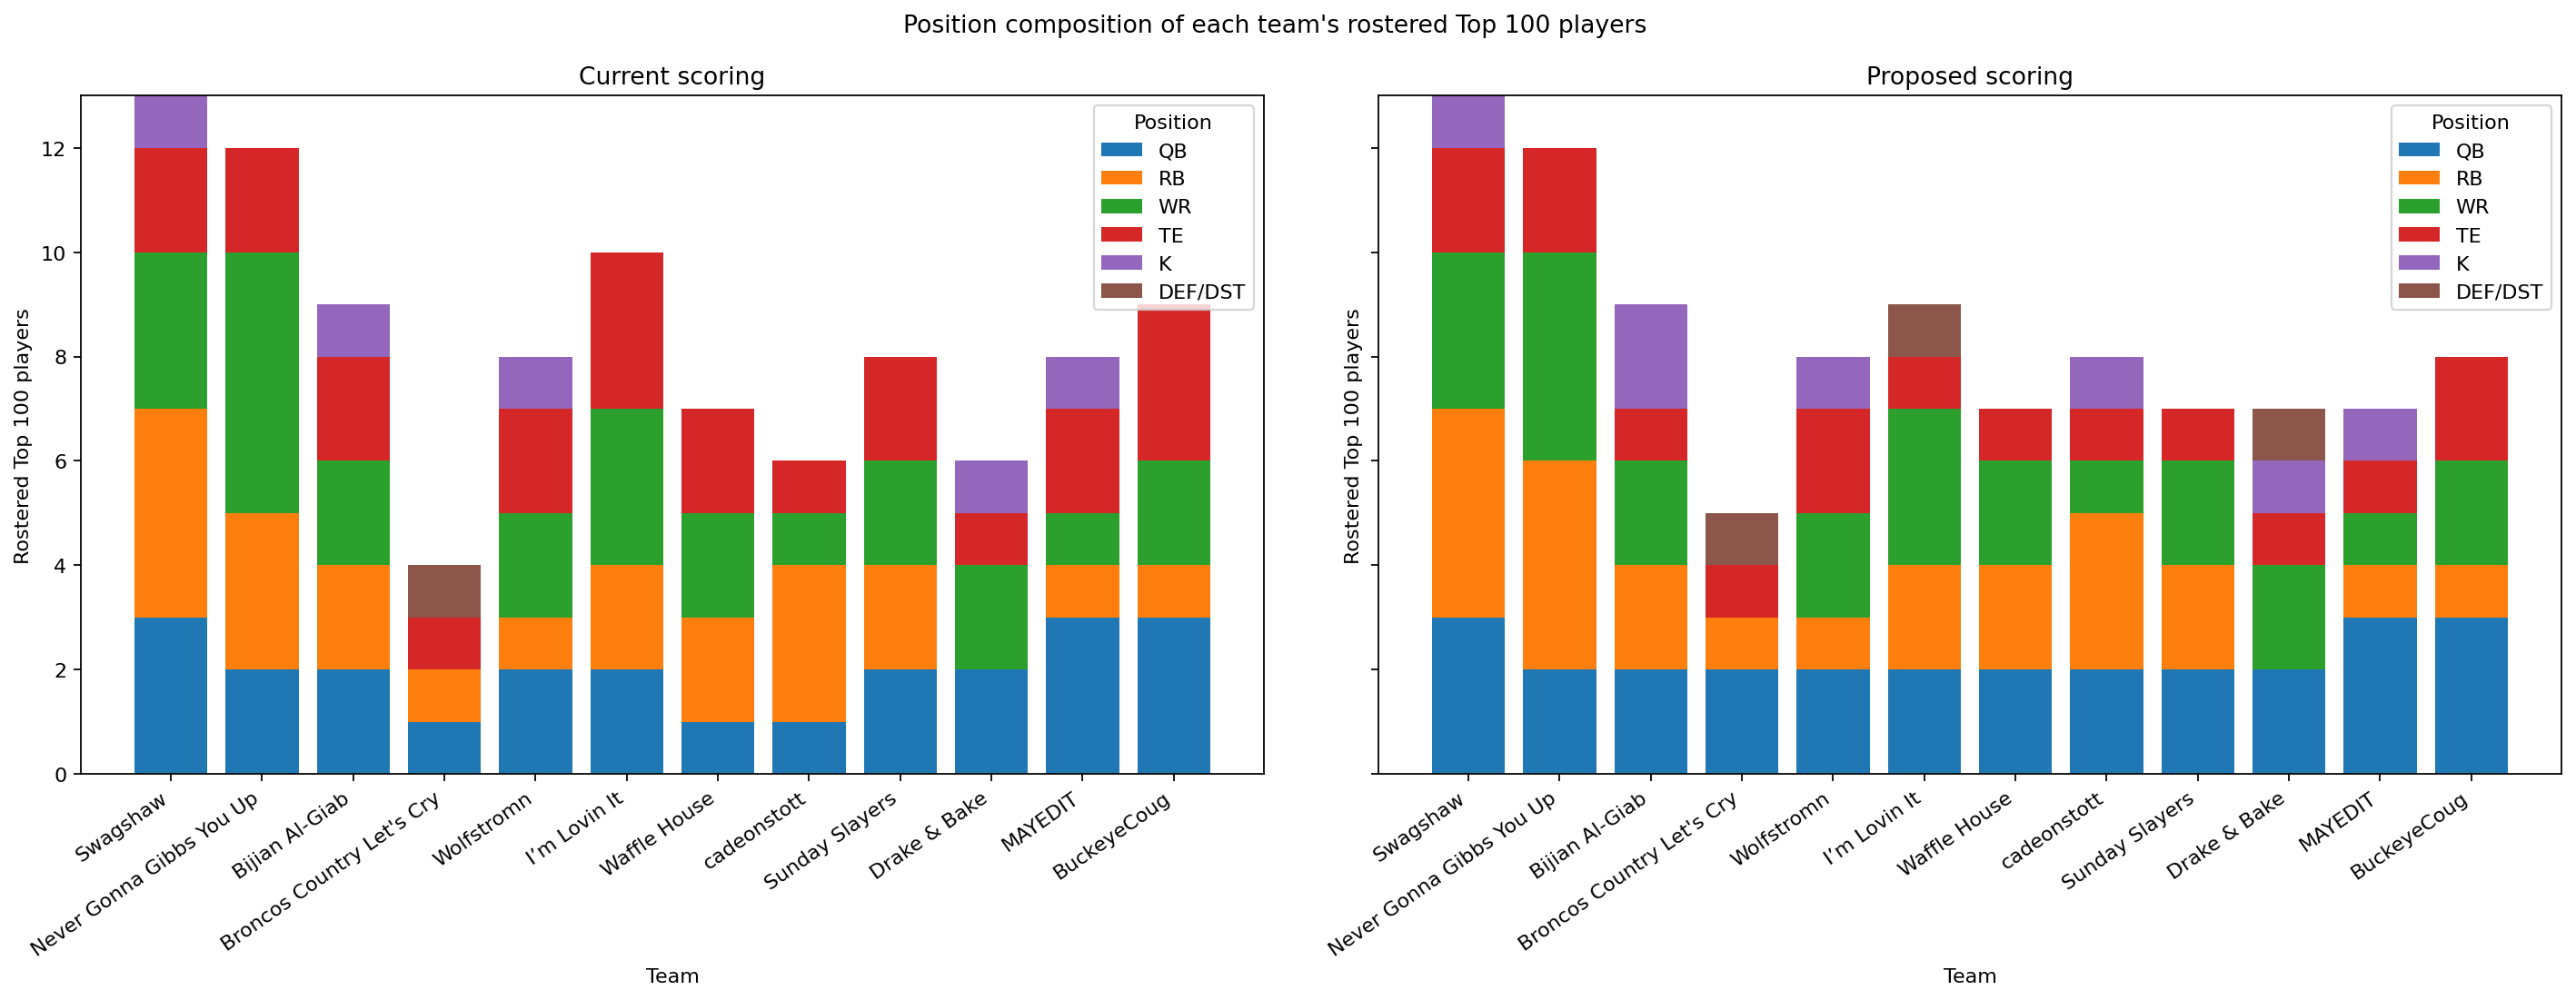

### Weekly Close Game Frequency

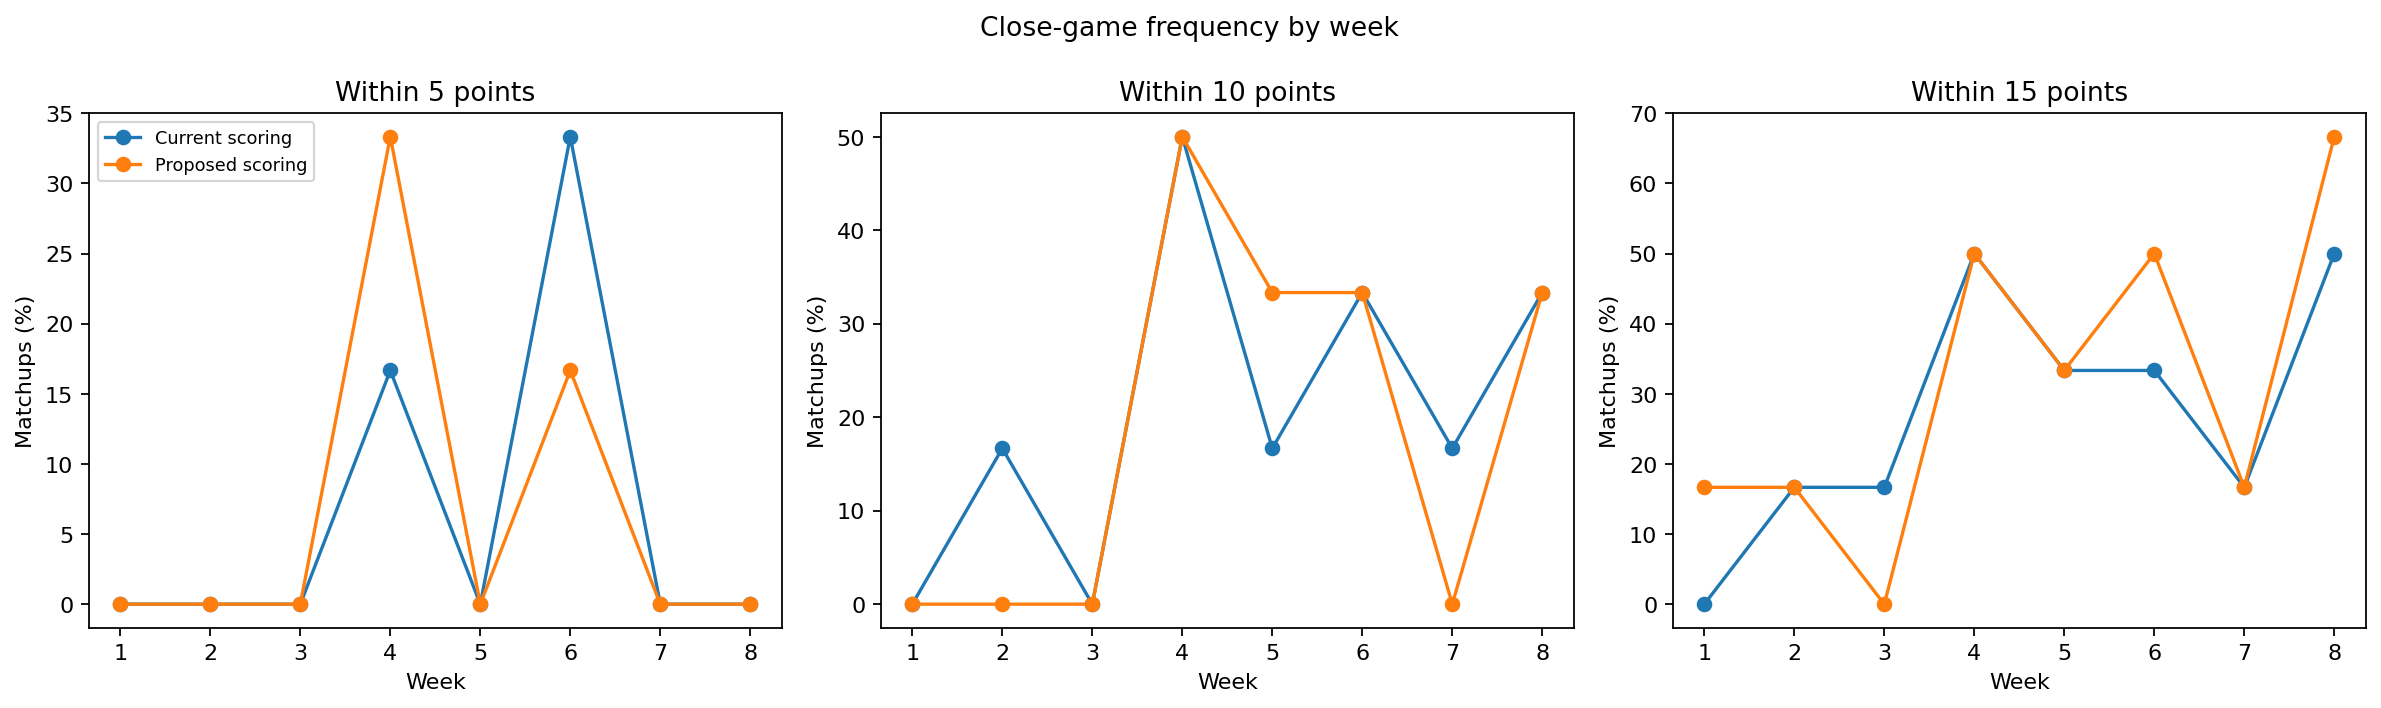

### Weekly Matchup Margin Distributions

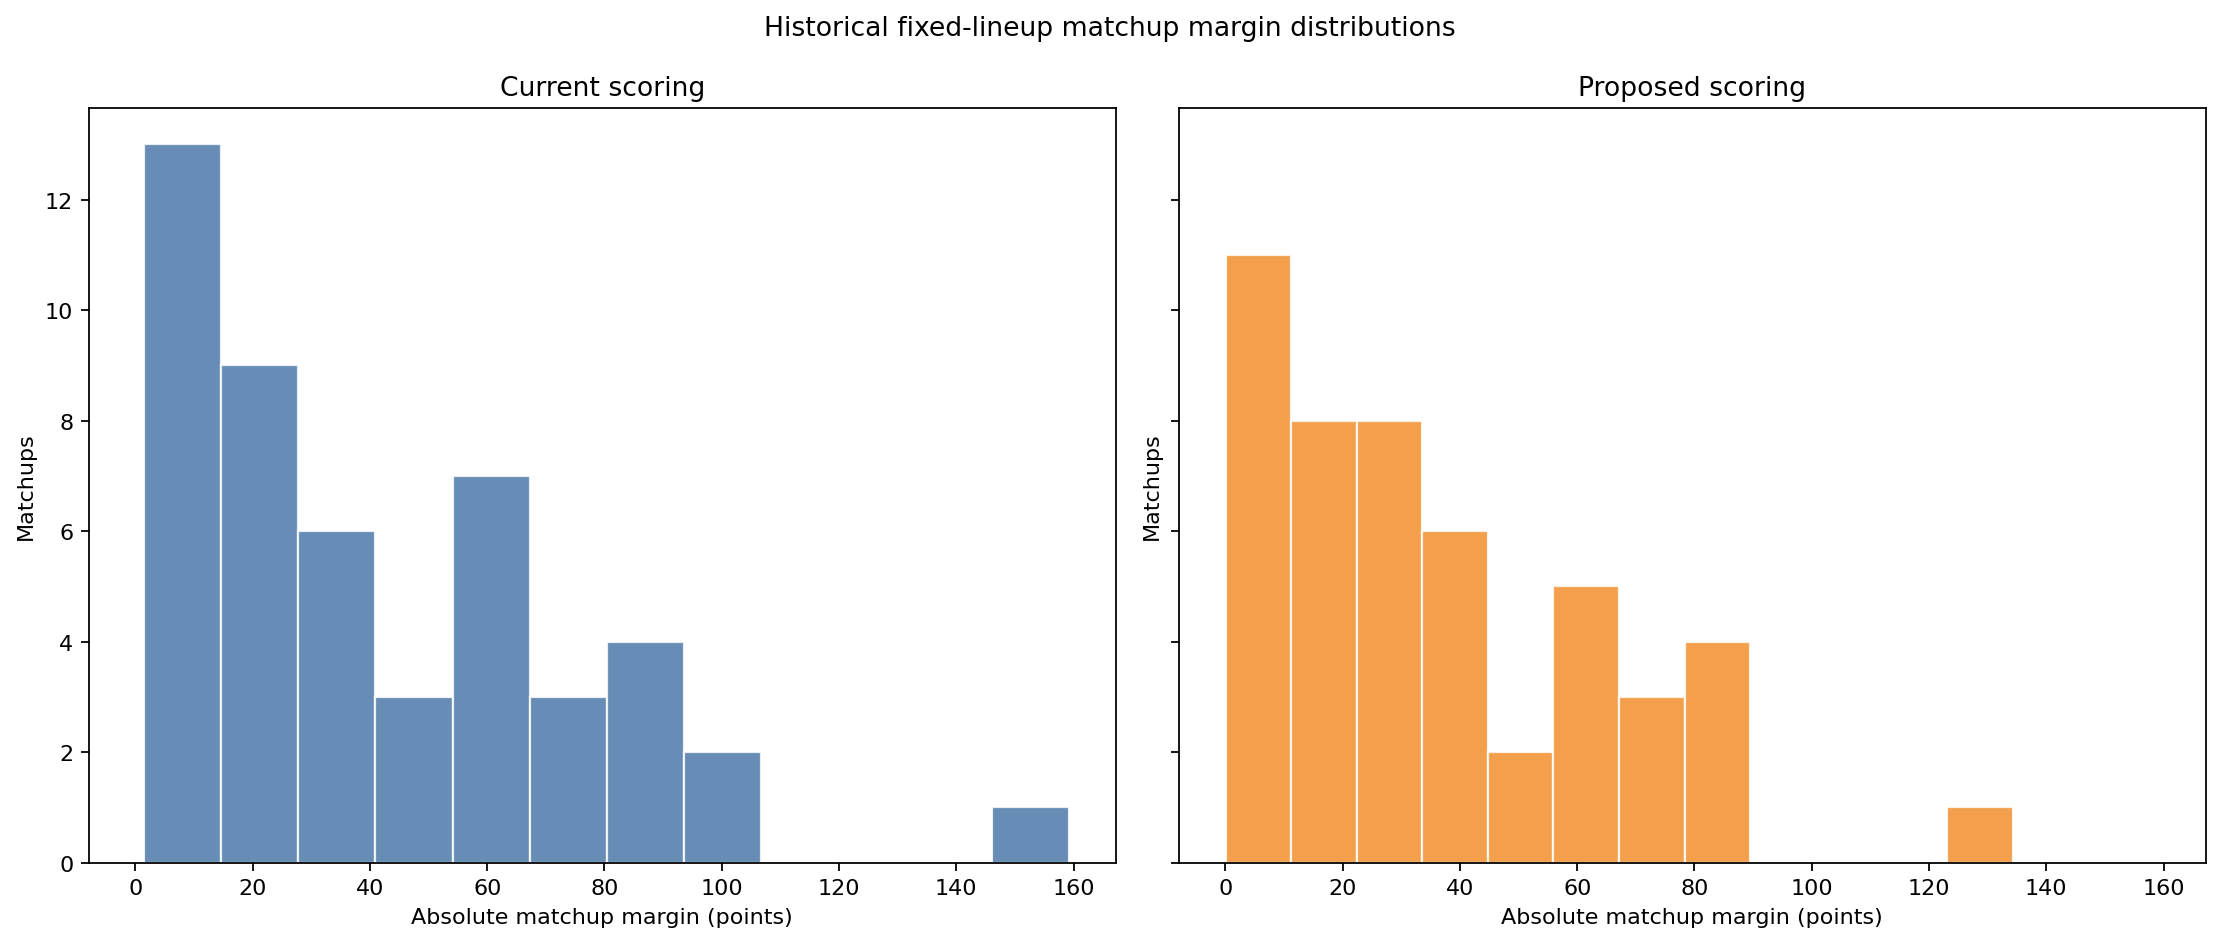

### Weekly Starter Score Ranges By Position

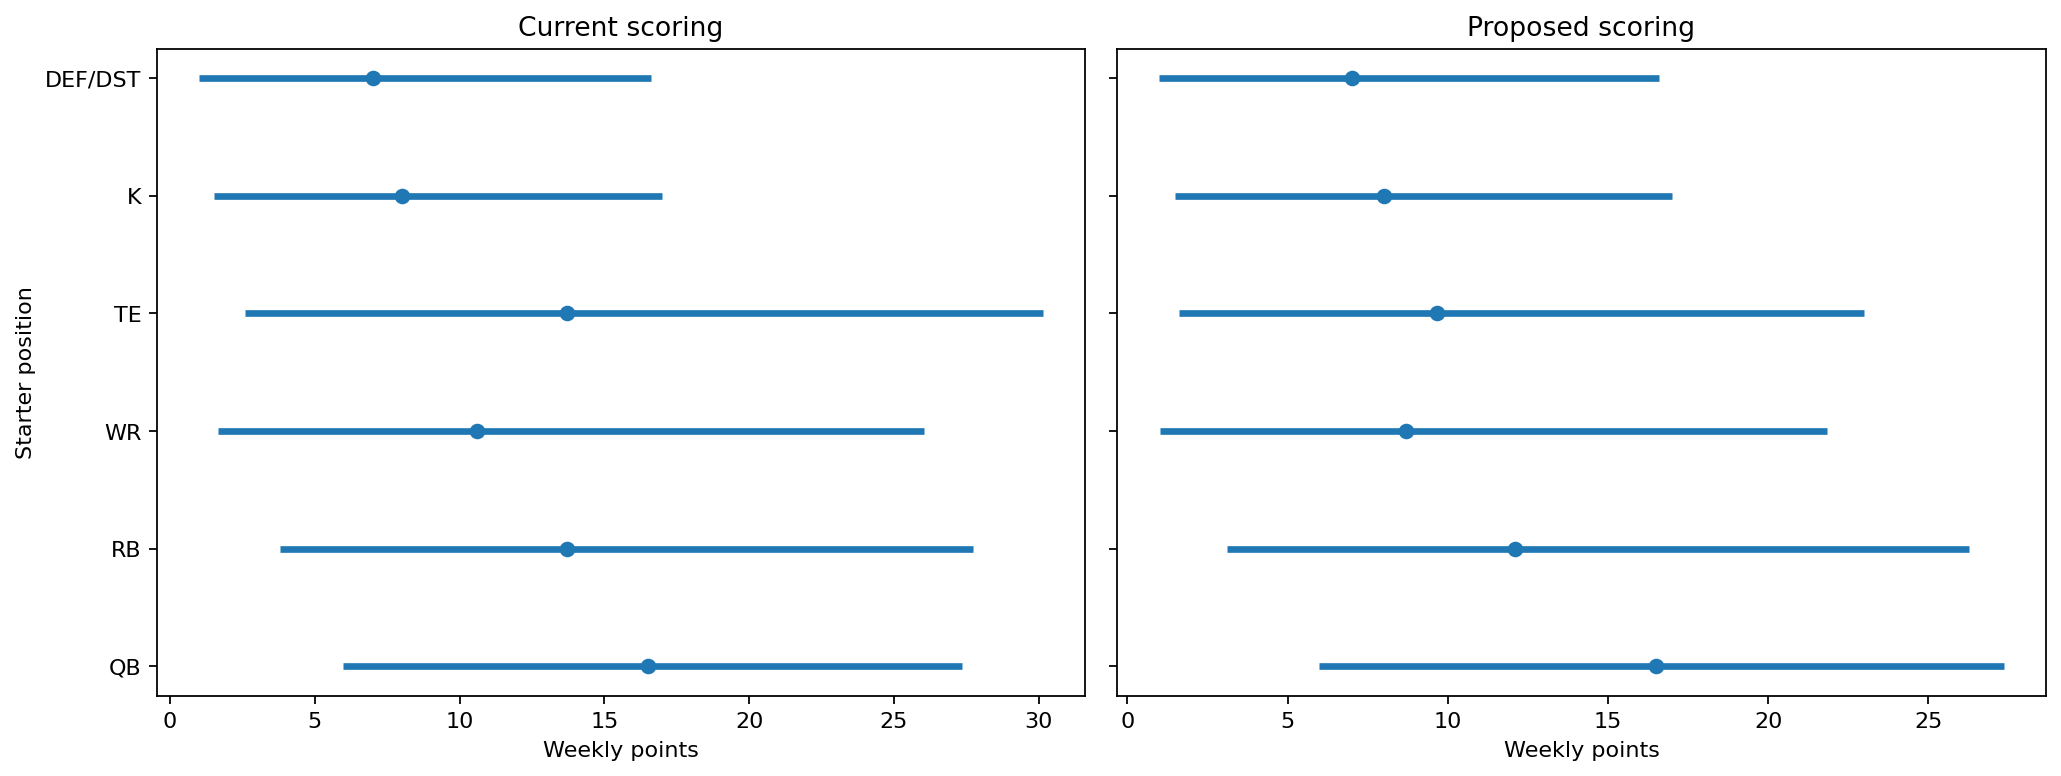

### Weekly Team Score Variation By Team

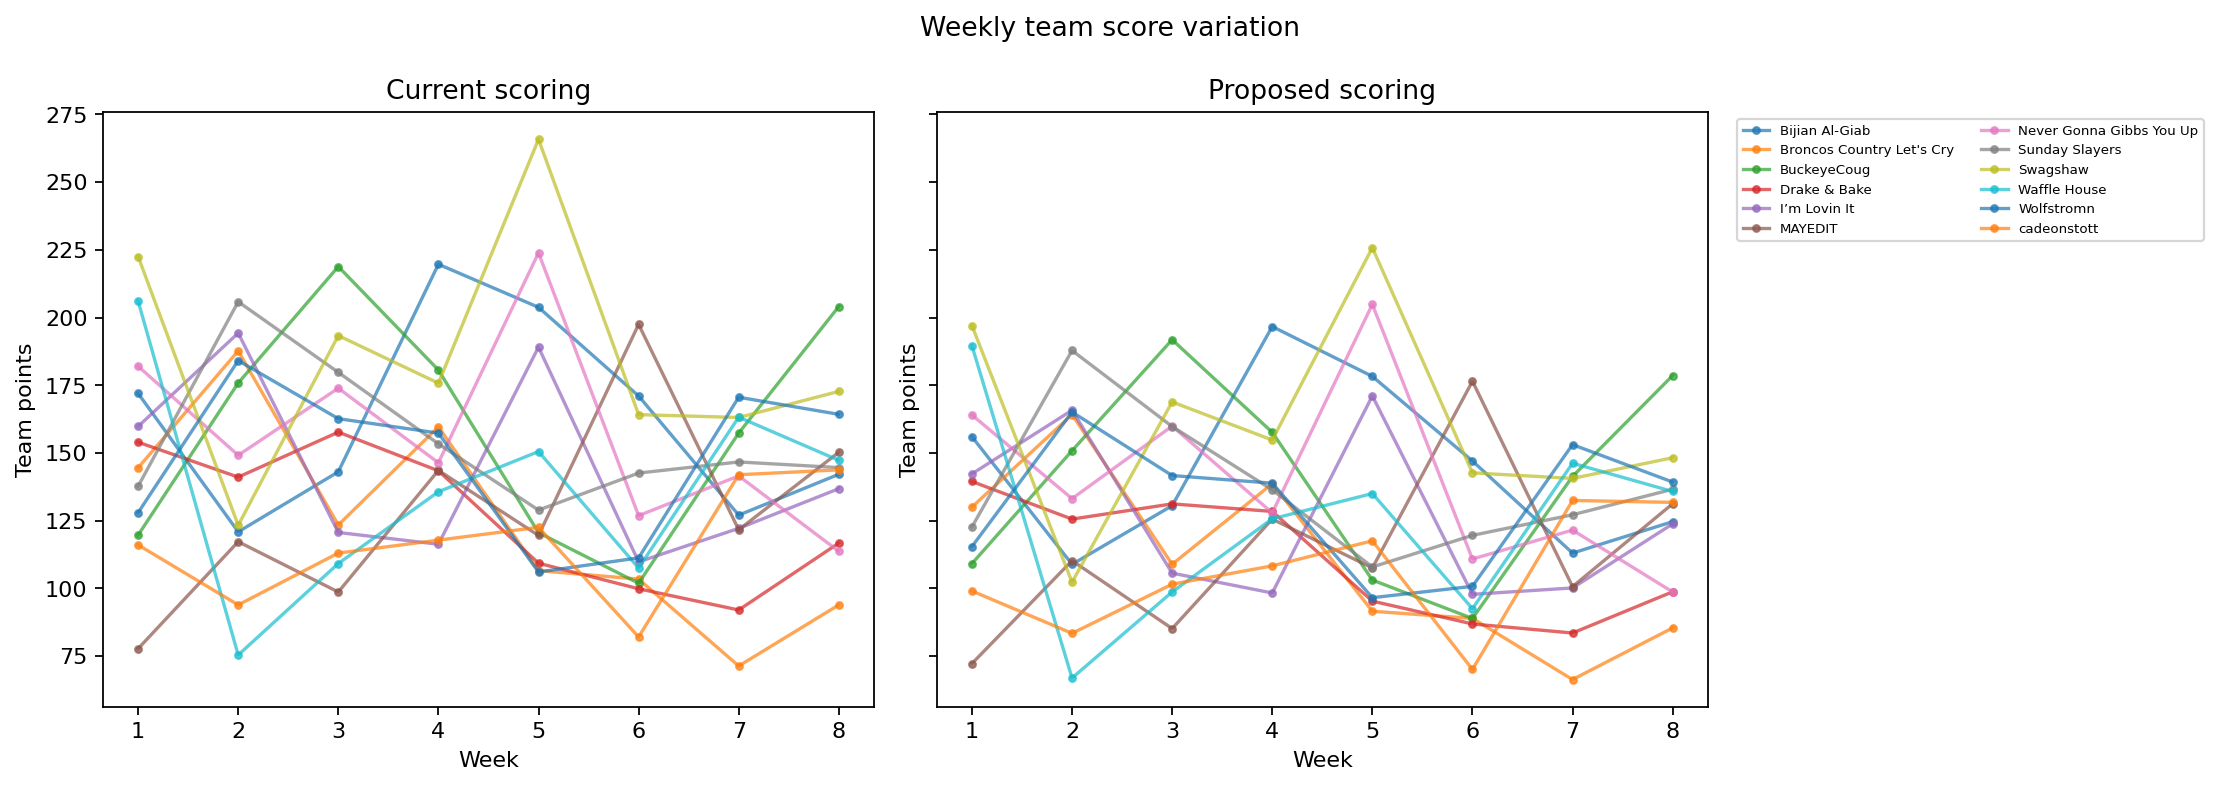

In [11]:
player_samples = read_report("lineup_player_scores.csv")
sample_columns = [
    "sleeper_id", "full_name", "position", "Team", "games_played",
    "games_played_source_available", "has_season_stats_record",
    "current_season_points", "current_points_per_game",
    "comparison_season_points", "comparison_points_per_game",
]
display(Markdown("### Player-level games played and per-game sample - first 48 rostered players"))
display(player_samples[sample_columns].head(48))

lineup_selection_detail = read_report("team_lineup_selections.csv")
display(Markdown("### Selected player IDs, slot assignments, and per-game scores - first 48 rows"))
display(lineup_selection_detail.head(48))

secondary_figures = [
    path for path in sorted(FIGURE_DIR.glob("*.png"))
    if path.name not in MAIN_FIGURES
]
for path in secondary_figures:
    display(Markdown(f"### {path.stem.replace('_', ' ').title()}"))
    display(Image(filename=str(path)))